# M3d redo: expanded logistic CV fold comparison

Adds unpenalized, fixed-$C$, and full-CV WERM variants at 2 and 10 folds while reusing validated completed competitor checkpoints.

## Experiment

In [1]:
from WERM.signal_priors import SparseGaussianSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
jax.config.update('jax_enable_x64', True)
import numpy.random as nprandom
import matplotlib.pyplot as plt
# Embed figures in executed notebook output even on a headless compute node.
plt.switch_backend("module://matplotlib_inline.backend_inline")
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
from joblib.externals.loky.process_executor import TerminatedWorkerError
from WERM.experiment_utils import data_hash as _data_hash, evaluate_changepoints as _evaluate_changepoints, summarize_setting as _summarize_setting, trial_rng as _trial_rng, weighted_erm_joint_cv as _weighted_erm_joint_cv, glm_bsa3_cv as _glm_bsa3_cv
import logging
from datetime import datetime, timedelta
import sys
import pickle
import os
os.environ['JAX_ENABLE_X64']='True'

# Set a random seed for reproducibility
random_seed = 42
SMOKE_MODE = os.environ.get('WERM_SMOKE') == '1'

def _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx):
    return os.path.join(checkpoint_dir, f'setting_{int(setting_idx):02d}_trial_{int(trial_idx):03d}.pkl')

def _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result):
    """Atomically persist one deterministic trial before returning it to joblib."""
    setting_idx, trial_idx, trial_result = result
    os.makedirs(checkpoint_dir, exist_ok=True)
    path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
    tmp_path = f'{path}.tmp-{os.getpid()}'
    payload = {
        'signature': checkpoint_signature,
        'setting_idx': int(setting_idx),
        'trial_idx': int(trial_idx),
        'result': result,
    }
    with open(tmp_path, 'wb') as checkpoint_file:
        pickle.dump(payload, checkpoint_file, protocol=pickle.HIGHEST_PROTOCOL)
        checkpoint_file.flush()
        os.fsync(checkpoint_file.fileno())
    os.replace(tmp_path, path)

def _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx):
    """Return a validated checkpoint, or None when absent/corrupt/incompatible."""
    path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
    if not os.path.exists(path):
        return None
    try:
        with open(path, 'rb') as checkpoint_file:
            payload = pickle.load(checkpoint_file)
        if payload.get('signature') != checkpoint_signature:
            return None
        result = payload['result']
        if (int(result[0]), int(result[1])) != (int(setting_idx), int(trial_idx)):
            return None
        data_hash = result[2].get('data_hash')
        if not isinstance(data_hash, str) or len(data_hash) != 32:
            return None
        return result
    except Exception as checkpoint_error:
        print(f'Ignoring invalid checkpoint {path}: {checkpoint_error}')
        return None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, gamma_candidates, method_configs, checkpoint_dir=None, checkpoint_signature=None, existing_trial_result=None):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    i, κ, j = params
    trial_start_time = time.time()
    rng = _trial_rng("M3d-redo-successive-halving", i, j)

    # Fixed delta
    δ = fixed_delta

    # --- Setup based on delta and kappa ---
    n = int(δ * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    α = 0.5
    σ_l_arr = κ * np.sqrt(δ) * np.ones(L)
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    B̃ = signal_prior.sample(p, rng=rng)
    X = rng.normal(0, np.sqrt(1/n), (n, p))
    ε = rng.uniform(0, 1, size=(n, ))

    X = X @ np.linalg.cholesky(Sigma).T
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    X_scaled = X * np.sqrt(n)
    B̃_scaled = B̃ / np.sqrt(n)
    Θ = X_scaled @ B̃_scaled
    y = np.array(jax.vmap(WERM.model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε))
    data_gen_time = time.time() - data_gen_start

    # --- Run Estimators for all configured methods ---
    current_data_hash = _data_hash(X, y)
    if existing_trial_result is not None:
        if existing_trial_result.get('data_hash') != current_data_hash:
            raise RuntimeError(f'legacy checkpoint data hash mismatch at setting={i}, trial={j}')
        trial_results = dict(existing_trial_result)
        methods_status = {method_name: False for method_name in method_configs.keys()}
        methods_status.update(existing_trial_result.get('methods_status', {}))
    else:
        trial_results = {'data_hash': current_data_hash}
        methods_status = {method_name: False for method_name in method_configs.keys()}
    reused_methods = []

    for method_name, method_func_info in method_configs.items():
        try:
            if f'status_{method_name}' in trial_results:
                reused_methods.append(method_name)
                continue
            print(f"Running {method_name} on params: ", params)
            method_start = time.time()
            cp = np.array([]) # Initialize changepoints

            if method_name == 'GLMBSA':
                # Fixed-c1 baseline; kmax is the automatic binary-segmentation pass budget.
                delta_fraction = 1/10
                cp = np.asarray(WERM.comparison.glm_bsa3(X_scaled, y.reshape((n, 1)), kmax=glmbsa_kmax, c1=0.18, 
                                                         m1 = None, delta = delta_fraction, exact=False))
                cp = np.asarray(cp, dtype=int)
                cp = cp[(cp > 1) & (cp < n)]  # Drop R endpoint sentinels 1 and n.
                print("BSA cp: ", cp)
            elif method_name in glmbsa_cv_folds:
                delta_fraction = 1/10
                selected_c1, cp, glmbsa_cv_scores = _glm_bsa3_cv(
                    X_scaled, y, kmax=glmbsa_kmax,
                    delta=delta_fraction, c1_candidates=glmbsa_c1_candidates,
                    num_folds=glmbsa_cv_folds[method_name],
                )
                trial_results[f'selected_c1_{method_name}'] = float(selected_c1)
                trial_results[f'cv_scores_{method_name}'] = np.asarray(glmbsa_cv_scores).copy()
                print(
                    f'{method_name} selected c1={selected_c1:g}; cp={cp}; '
                    f'folds={glmbsa_cv_folds[method_name]}'
                )

            elif method_name == 'GLMBSA-fixed0.18-2fold':
                # Use the identical held-out logistic CV path with c1 fixed at 0.18.
                delta_fraction = 1/10
                selected_c1, cp, glmbsa_cv_scores = _glm_bsa3_cv(
                    X_scaled, y, kmax=glmbsa_kmax,
                    delta=delta_fraction, c1_candidates=(0.18,),
                    num_folds=2,
                )
                trial_results['selected_c1_GLMBSA-fixed0.18-2fold'] = float(selected_c1)
                trial_results['cv_scores_GLMBSA-fixed0.18-2fold'] = np.asarray(glmbsa_cv_scores).copy()
                print(f'GLMBSA fixed c1=0.18 (2-fold CV path); cp={cp}')

                delta_fraction = 1/10
            elif method_name == 'WERM-CV':
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                def WERM_l1_reg_paramCV(X_train, y_train, l1_reg_param):
                    """Cross-validation function for WERM with L1 regularization, tested for fixed num chgpts."""
                    def P_func_(beta):
                        return l1_reg_param * jnp.sum(jnp.abs(beta))

                    return WERM.estimators.weighted_erm(
                        X=X_train, y=y_train, M=M, L=L, Delta_n=Delta_n(n), gamma=l1_reg_param,
                        L_is_upper_bound=False, return_B_hat=False,
                        brute_force=False, P_func=P_func_,
                        coefficient_loss="logistic", coefficient_lambda=l1_reg_param,
                    )
                lambda_hat = 1 * np.sqrt(2 * np.log(p) / n) 
                C=10
                best_l1_reg = C * n * lambda_hat
                P_func = lambda beta: best_l1_reg * jnp.sum(jnp.abs(beta))
                gamma = 3.75
                best_L_tilde, cp = WERM.estimators.weighted_erm_num_chgptCV(X=X, y=y, M=M, Delta_n=Delta_n(n), Lmax=L, 
                    brute_force=False, return_gof=False,
                    P_func=P_func, M_scorer=M_scorer,
                    num_folds=5, n_jobs=1,
                    coefficient_loss="logistic", coefficient_lambda=best_l1_reg,
                )
            elif method_name == 'WERM-L1-fullCV':
                # Fit and score with logistic loss; exhaustive joint CV.
                (best_segments, best_C), cp, full_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=joint_l1_constants,
                    num_folds=5, n_jobs=1, selection_strategy='exhaustive',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-6, 'max_iter': 20000},
                )
                trial_results['full_cv_WERM-L1-fullCV'] = full_cv_diagnostics
                trial_results['selected_segments_WERM-L1-fullCV'] = int(best_segments)
                trial_results['selected_num_chgpts_WERM-L1-fullCV'] = int(best_segments - 1)
                trial_results['selected_l1_constant_WERM-L1-fullCV'] = float(best_C)
                trial_results['selected_l1_lambda_WERM-L1-fullCV'] = float(best_C*np.sqrt(2*np.log(p)/n))

            elif method_name == 'WERM-L1-C0.3-2fold':
                # Hold C fixed and use exhaustive 2-fold CV only over segment count.
                (best_segments, best_C), cp, fixed_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=(0.3,),
                    num_folds=2, n_jobs=1, selection_strategy='exhaustive',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-6, 'max_iter': 20000},
                )
                trial_results['full_cv_WERM-L1-C0.3-2fold'] = fixed_cv_diagnostics
                trial_results['selected_segments_WERM-L1-C0.3-2fold'] = int(best_segments)
                trial_results['selected_num_chgpts_WERM-L1-C0.3-2fold'] = int(best_segments - 1)
                trial_results['selected_l1_constant_WERM-L1-C0.3-2fold'] = float(best_C)
                trial_results['selected_l1_lambda_WERM-L1-C0.3-2fold'] = float(best_C*np.sqrt(2*np.log(p)/n))

            elif method_name in (
                'WERM-L1-C0.18-2fold', 'WERM-L1-C0.18-10fold',
                'WERM-L1-C0.3-10fold',
                'WERM-L1-fullCV-2fold', 'WERM-L1-fullCV-10fold',
            ):
                # Reference M3d settings: logistic fit/score, Lmax=4,
                # delta_fraction=1/10, exhaustive segment-count selection.
                cv_folds = 10 if method_name.endswith('10fold') else 2
                if 'C0.18' in method_name:
                    l1_constants=(0.18,)
                elif 'C0.3' in method_name:
                    l1_constants=(0.3,)
                else:
                    l1_constants=joint_l1_constants
                (best_segments, best_C), cp, variant_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=l1_constants,
                    num_folds=cv_folds, n_jobs=1, selection_strategy='exhaustive',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-6, 'max_iter': 20000},
                )
                trial_results[f'full_cv_{method_name}'] = variant_cv_diagnostics
                trial_results[f'selected_segments_{method_name}'] = int(best_segments)
                trial_results[f'selected_num_chgpts_{method_name}'] = int(best_segments - 1)
                trial_results[f'selected_l1_constant_{method_name}'] = float(best_C)
                trial_results[f'selected_l1_lambda_{method_name}'] = float(best_C*np.sqrt(2*np.log(p)/n))

            elif method_name.startswith('WERM-unp-'):
                # Same M3d logistic fit and held-out logistic score; only k changes.
                cv_folds = int(method_name.rsplit('-', 1)[1].replace('fold', ''))
                (best_segments, _), cp, unpenalized_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=(0.0,),
                    num_folds=cv_folds, n_jobs=1, standardize_y=False,
                    selection_strategy='exhaustive', penalty_norm='none',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-4, 'max_iter': 20000},
                )
                trial_results[f'full_cv_{method_name}'] = unpenalized_cv_diagnostics
                trial_results[f'selected_segments_{method_name}'] = int(best_segments)
                trial_results[f'selected_num_chgpts_{method_name}'] = int(best_segments - 1)

            elif method_name == 'WERM-unp':
                delta_fraction = 1/20
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta_n(n), gamma=0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, 
                )
            elif method_name == 'WERM-fixed':
                fixed_gamma_value = 1e-3 # Example fixed gamma value
                P_func_fixed = lambda beta: fixed_gamma_value * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func_fixed
                )
            else:
                continue

            method_time = time.time() - method_start
            evaluation = _evaluate_changepoints(cp, true_chgpts, n)
            raw_cp = evaluation['raw_cp']
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'raw_cp_{method_name}'] = None if raw_cp is None else raw_cp.copy()
            trial_results[f'status_{method_name}'] = evaluation['status']
            trial_results[f'haus_{method_name}'] = evaluation['haus']
            trial_results[f'size_{method_name}'] = evaluation['size']
            trial_results[f'chgpts_{method_name}'] = np.array([]) if raw_cp is None else raw_cp.copy()
            methods_status[method_name] = evaluation['status'] != 'not_applicable'

        except Exception as e:
            print(f"Trial {j+1} for kappa={κ:.2f}: {method_name} failed with error: {e}")
            raise

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status
    trial_results['reused_methods'] = tuple(reused_methods)

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for κ={κ:.2f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = trial_results[f'status_{method_name}']
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")

    result = (i, j, trial_results)
    if checkpoint_dir is not None:
        _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result)
    return result

# Simulation Parameters
p = 200
L = 4
noise_std = np.sqrt(0.6) # Not used in logistic model
fixed_delta = 3.0 # Fixed delta value
kappa_list = np.sqrt([1.0, 10.0, 25.0, 50.0, 100.0, 500.0, 1000.0, 2000.0]) # Iterate over kappa
num_trials = 100
fractional_chgpt_locations = np.array([1/3, 8/15])
# glmbsa_c1_candidates = (0.045, 0.09, 0.18, 0.36, 0.72) # two Half and double of recommended parameter
glmbsa_c1_candidates = (0.09, 0.18, 0.36) # Half and double of recommended parameter
joint_l1_constants = (0.15, 0.3, 0.6) # Half and double the recommended parameter
n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '36')), 36))
if SMOKE_MODE:
    kappa_list = np.array([5.0])
    num_trials = 1
    n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '2')), 36))

def sample_corr(p, df=10, seed=None):
    """Sample a random correlation matrix using the Haar measure."""
    rng = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
    λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
    B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
    D = np.sqrt(np.diag(B))
    return B / np.outer(D, D)

Sigma = sample_corr(p, df=10, seed=random_seed) 

# --- Define Methods to be Evaluated ---
glmbsa_kmax = L - 2  # original M3d protocol; independent of ground truth
glmbsa_cv_folds = {'GLMBSA-CV': 2, 'GLMBSA-CV-5fold': 5, 'GLMBSA-CV-10fold': 10}
methods_to_evaluate = [
    {'name': 'GLMBSA-CV', 'label': '\\textbf{GLMBSA-CV (2-fold)}', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-5fold', 'label': 'GLMBSA-CV (5-fold)', 'color': '#56B4E9', 'marker': '<', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-10fold', 'label': 'GLMBSA-CV (10-fold)', 'color': '#009E73', 'marker': '>', 'linestyle': ':'},
    {'name': 'GLMBSA-fixed0.18-2fold', 'label': 'GLMBSA fixed $c_1=0.18$ (2-fold)', 'color': '#AA4499', 'marker': 'D', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV', 'label': '\\textbf{WERM Logistic+L1 full CV (5-fold)}', 'color': 'black', 'marker': '*', 'linestyle': '-'},
    {'name': 'WERM-L1-C0.3-2fold', 'label': '\\textbf{WERM Logistic+L1 $C=0.3$ (2-fold)}', 'color': '#555555', 'marker': 'X', 'linestyle': '--'},
    {'name': 'WERM-unp-2fold', 'label': 'WERM Logistic unpenalized (2-fold)', 'color': '#BBBBBB', 'marker': 'h', 'linestyle': '-'},
    {'name': 'WERM-unp-10fold', 'label': 'WERM Logistic unpenalized (10-fold)', 'color': '#882255', 'marker': 'H', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.18-2fold', 'label': 'WERM Logistic+L1 $C=0.18$ (2-fold)', 'color': '#0077BB', 'marker': 's', 'linestyle': '--'},
    {'name': 'WERM-L1-C0.18-10fold', 'label': 'WERM Logistic+L1 $C=0.18$ (10-fold)', 'color': '#33BBEE', 'marker': 'o', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.3-10fold', 'label': 'WERM Logistic+L1 $C=0.3$ (10-fold)', 'color': '#CC3311', 'marker': 'P', 'linestyle': '--'},
    {'name': 'WERM-L1-fullCV-2fold', 'label': 'WERM Logistic+L1 full CV (2-fold)', 'color': '#EE3377', 'marker': '^', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV-10fold', 'label': 'WERM Logistic+L1 full CV (10-fold)', 'color': '#009988', 'marker': 'v', 'linestyle': '-.'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(kappa_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'kappa_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'haus_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = []


# Logistic loss function
M = lambda u, v: jnp.logaddexp(0.0, u) - jnp.multiply(v, u)
M_scorer = M

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-4, 1, 8)

# --- Checkpointed parallel execution ---
tasks = [(i, κ, j) for i, κ in enumerate(kappa_list) for j in range(num_trials)]
checkpoint_signature = {
    'schema_version': 12,
    'experiment': 'M3d-redo-thirteen-method-logistic-fold-comparison-glmbsa2-5-10',
    'p': int(p),
    'L': int(L),
    'noise_std': float(noise_std),
    'fixed_delta': float(fixed_delta),
    'kappa_list': tuple(float(value) for value in kappa_list),
    'num_trials': int(num_trials),
    'fractional_chgpt_locations': tuple(float(value) for value in fractional_chgpt_locations),
    'random_seed': int(random_seed),
    'coefficient_solver': 'weighted-FISTA-backtracking-v2',
    'methods': tuple(method_names_list),
    'gamma_candidates': tuple(float(value) for value in gamma_candidates),
    'joint_l1_constants': tuple(float(value) for value in joint_l1_constants),
    'werm_cv_strategy': 'exhaustive',
    'glmbsa_c1_candidates': tuple(float(value) for value in glmbsa_c1_candidates),
    'glmbsa_cv_folds': (2, 5, 10),
}
checkpoint_mode = 'smoke' if SMOKE_MODE else 'full'
checkpoint_dir = os.path.join(
    'results', 'checkpoints',
    f'M3_upsample_d_redo_full_cv_delta{fixed_delta:g}_{checkpoint_mode}_seed{random_seed}_p{p}_L{L}_schema{checkpoint_signature["schema_version"]}',
)
os.makedirs(checkpoint_dir, exist_ok=True)

rerun_methods = ('GLMBSA-CV-5fold', 'GLMBSA-CV-10fold')

def _without_method_results(trial_result, method_names):
    cleaned = dict(trial_result)
    for key in tuple(cleaned):
        if any(key.endswith(f'_{method_name}') for method_name in method_names):
            cleaned.pop(key, None)
    cleaned['methods_status'] = dict(cleaned.get('methods_status', {}))
    for method_name in method_names:
        cleaned['methods_status'].pop(method_name, None)
    cleaned.pop('reused_methods', None)
    return cleaned

prior_checkpoint_signature = dict(checkpoint_signature)
prior_checkpoint_signature['schema_version'] = 11
prior_checkpoint_signature['experiment'] = 'M3d-redo-eleven-method-logistic-fold-comparison-glmbsa2fold'
prior_checkpoint_signature['methods'] = tuple(
    name for name in method_names_list if name not in rerun_methods
)
prior_checkpoint_signature['glmbsa_cv_folds'] = 2
prior_checkpoint_dir = os.path.join(
    'results', 'checkpoints',
    f'M3_upsample_d_redo_full_cv_delta{fixed_delta:g}_{checkpoint_mode}_seed{random_seed}_p{p}_L{L}_schema11',
)
legacy_results = {}
if os.path.isdir(prior_checkpoint_dir):
    for setting_idx, _, trial_idx in tasks:
        prior_checkpoint = _load_trial_checkpoint(
            prior_checkpoint_dir, prior_checkpoint_signature, setting_idx, trial_idx
        )
        if prior_checkpoint is not None:
            legacy_results[(int(setting_idx), int(trial_idx))] = _without_method_results(
                prior_checkpoint[2], rerun_methods
            )
print(
    f'Validated {len(legacy_results)}/{len(tasks)} schema-11 checkpoints; '
    'reusing completed methods and running GLMBSA 5- and 10-fold CV'
)

completed_results = {}
for task in tasks:
    setting_idx, _, trial_idx = task
    checkpointed = _load_trial_checkpoint(
        checkpoint_dir, checkpoint_signature, setting_idx, trial_idx
    )
    if checkpointed is not None:
        completed_results[(int(setting_idx), int(trial_idx))] = checkpointed

print(f'Resuming M3d redo thirteen-method comparison with {len(completed_results)}/{len(tasks)} validated trial checkpoints')
single_trial_estimate = 30.0 * len(methods_to_evaluate)
total_estimated_time = (len(tasks) - len(completed_results)) * single_trial_estimate / max(n_jobs, 1)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
simulation_start_time = time.time()
active_n_jobs = n_jobs
worker_restarts = 0
progress = tqdm(total=len(tasks), initial=len(completed_results), desc='Running simulation trials', ncols=100)

while len(completed_results) < len(tasks):
    pending = [task for task in tasks if (int(task[0]), int(task[2])) not in completed_results]
    batch_n_jobs = max(1, active_n_jobs)  # Keep BLAS threading invariant in a partial final batch.
    batch = pending[:batch_n_jobs]  # one task per fresh worker generation
    before = len(completed_results)
    crashed = False
    try:
        Parallel(
            n_jobs=batch_n_jobs, verbose=0, batch_size=1, pre_dispatch=batch_n_jobs,
            idle_worker_timeout=1,
        )(
            delayed(run_single_trial)(
                params=task,
                p=p,
                L=L,
                noise_std=noise_std,
                fractional_chgpt_locations=fractional_chgpt_locations,
                M=M,
                gamma_candidates=gamma_candidates,
                method_configs=method_configs,
                checkpoint_dir=checkpoint_dir,
                checkpoint_signature=checkpoint_signature,
                existing_trial_result=legacy_results.get((int(task[0]), int(task[2]))),
            ) for task in batch
        )
    except TerminatedWorkerError:
        crashed = True
        worker_restarts += 1
        print(f'WARNING: native M3 worker crash #{worker_restarts}; reloading checkpoints and retrying missing tasks')
    finally:
        # Let loky retire this generation before the next batch; this bounds native R/JAX state lifetime.
        time.sleep(1.25)

    for task in batch:
        setting_idx, _, trial_idx = task
        checkpointed = _load_trial_checkpoint(
            checkpoint_dir, checkpoint_signature, setting_idx, trial_idx
        )
        if checkpointed is not None:
            completed_results[(int(setting_idx), int(trial_idx))] = checkpointed

    newly_completed = len(completed_results) - before
    progress.update(newly_completed)
    if crashed and newly_completed == 0 and active_n_jobs > 1:
        active_n_jobs = max(1, active_n_jobs // 2)
        print(f'No checkpoint progress in the crashed batch; reducing outer workers to {active_n_jobs}')

progress.close()
parallel_results = [completed_results[(int(i), int(j))] for i, _, j in tasks]
expected_keys = {(int(i), int(j)) for i, _, j in tasks}
assert set(completed_results) == expected_keys
assert len(parallel_results) == num_trials * len(kappa_list)
simulation_end_time = time.time()
total_simulation_time = simulation_end_time - simulation_start_time

# --- Aggregate Results ---
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['kappa_values'].append((i, kappa_list[i]))

results['trial_records'] = parallel_results
results['summaries'] = []
for setting_idx, setting in enumerate(kappa_list):
    setting_records = [record for i, _, record in parallel_results if i == setting_idx]
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        summary = _summarize_setting(
            [record[f'haus_{method_name}'] for record in setting_records],
            [record[f'size_{method_name}'] for record in setting_records],
            [record[f'status_{method_name}'] for record in setting_records],
        )
        summary.update({'method': method_name, 'setting': float(setting)})
        results['summaries'].append(summary)
        print(method_name, f"kappa={setting:.3g}", summary)


# --- Legacy detailed summary statistics ---
for i, kappa in enumerate(kappa_list):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]

# --- Save one concise, unique aggregate artifact for the following plot cell ---
artifact_stem = 'results/M3d_redo_delta3_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42'
artifact_suffix = '_smoke' if SMOKE_MODE else '_100trials'
filename = artifact_stem + artifact_suffix + '.pkl'
payload = {
    'results': results,
    'params': {
        'p': p,
        'L': L,
        'noise_std': noise_std,
        'fixed_delta': fixed_delta,
        'kappa_list': np.asarray(kappa_list).copy(),
        'num_trials': num_trials,
        'fractional_chgpt_locations': fractional_chgpt_locations.copy(),
        'n_jobs': n_jobs,
        'random_seed': random_seed,
        'methods_evaluated': methods_to_evaluate,
        'checkpoint_signature': checkpoint_signature,
    },
}
with open(filename, 'wb') as results_file:
    pickle.dump(payload, results_file, protocol=pickle.HIGHEST_PROTOCOL)
    results_file.flush()
    os.fsync(results_file.fileno())
print(f'Saved aggregate results to {filename}')


Validated 800/800 schema-11 checkpoints; reusing completed methods and running GLMBSA 5- and 10-fold CV
Resuming M3d redo thirteen-method comparison with 800/800 validated trial checkpoints


Running simulation trials: 100%|##########################################| 800/800 [00:00<?, ?it/s]

GLMBSA-CV kappa=1 {'mean_haus': 0.22043859649122807, 'median_haus': 0.2, 'empty_estimate_rate': 0.81, 'not_applicable_rate': 0.0, 'mean_size': 0.2, 'method': 'GLMBSA-CV', 'setting': 1.0}
GLMBSA-CV-5fold kappa=1 {'mean_haus': 0.21883333333333335, 'median_haus': 0.19833333333333333, 'empty_estimate_rate': 0.8, 'not_applicable_rate': 0.0, 'mean_size': 0.26, 'method': 'GLMBSA-CV-5fold', 'setting': 1.0}
GLMBSA-CV-10fold kappa=1 {'mean_haus': 0.19927536231884058, 'median_haus': 0.195, 'empty_estimate_rate': 0.77, 'not_applicable_rate': 0.0, 'mean_size': 0.36, 'method': 'GLMBSA-CV-10fold', 'setting': 1.0}
GLMBSA-fixed0.18-2fold kappa=1 {'mean_haus': 0.23296666666666666, 'median_haus': 0.23166666666666666, 'empty_estimate_rate': 0.0, 'not_applicable_rate': 0.0, 'mean_size': 2.86, 'method': 'GLMBSA-fixed0.18-2fold', 'setting': 1.0}
WERM-L1-fullCV kappa=1 {'mean_haus': 0.29521505376344087, 'median_haus': 0.245, 'empty_estimate_rate': 0.69, 'not_applicable_rate': 0.0, 'mean_size': 0.46, 'method':

Saved aggregate results to results/M3d_redo_delta3_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42_100trials.pkl


## Plots

Removing 105 matplotlib modules...


Successfully set backend to: module://matplotlib_inline.backend_inline
Creating publication-ready plots...
Using palette: ['#E69F00', '#56B4E9', '#009E73', '#AA4499'] (Paul Tol Vibrant)
Using palette: ['#E69F00', '#56B4E9', '#009E73', '#AA4499', 'black', '#555555', '#BBBBBB', '#882255', '#0077BB', '#33BBEE', '#CC3311', '#EE3377', '#009988'] (Paul Tol Vibrant assigned to methods)
Data loaded for plotting; empty-estimate Hausdorff values are NaN.
DEBUG: Original kappa_list: [1.0e+00 1.0e+01 2.5e+01 5.0e+01 1.0e+02 5.0e+02 1.0e+03 2.0e+03]
DEBUG: Filtered kappa_list (>= 1.5): [  10.   25.   50.  100.  500. 1000. 2000.]
DEBUG: Method names available: ['GLMBSA-CV', 'GLMBSA-CV-5fold', 'GLMBSA-CV-10fold', 'GLMBSA-fixed0.18-2fold', 'WERM-L1-fullCV', 'WERM-L1-C0.3-2fold', 'WERM-unp-2fold', 'WERM-unp-10fold', 'WERM-L1-C0.18-2fold', 'WERM-L1-C0.18-10fold', 'WERM-L1-C0.3-10fold', 'WERM-L1-fullCV-2fold', 'WERM-L1-fullCV-10fold']
DEBUG: First few haus results (filtered): [[0.00833333        nan 0.09

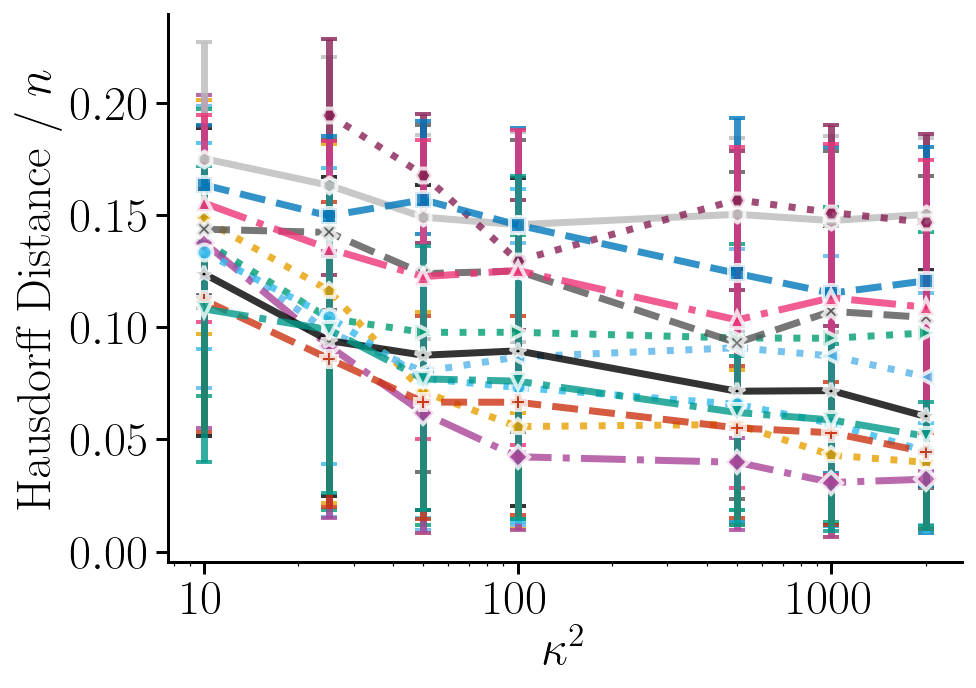

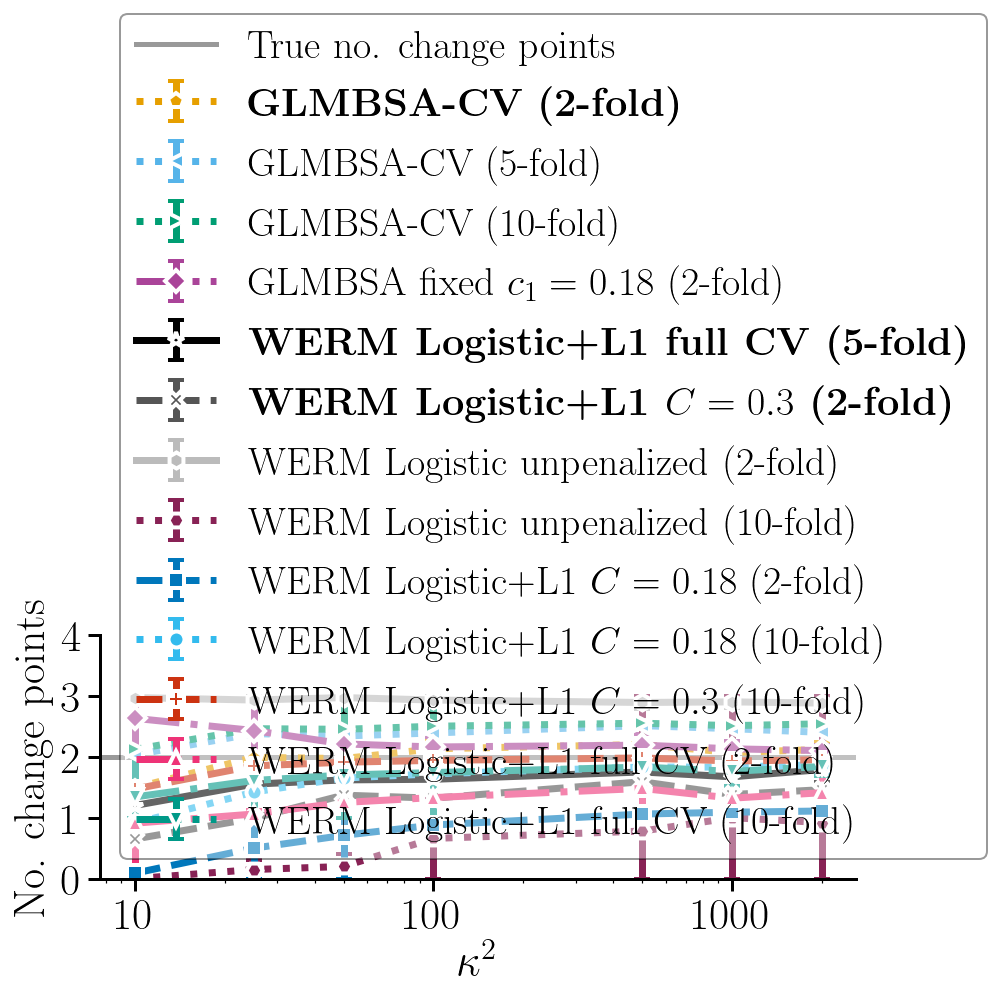

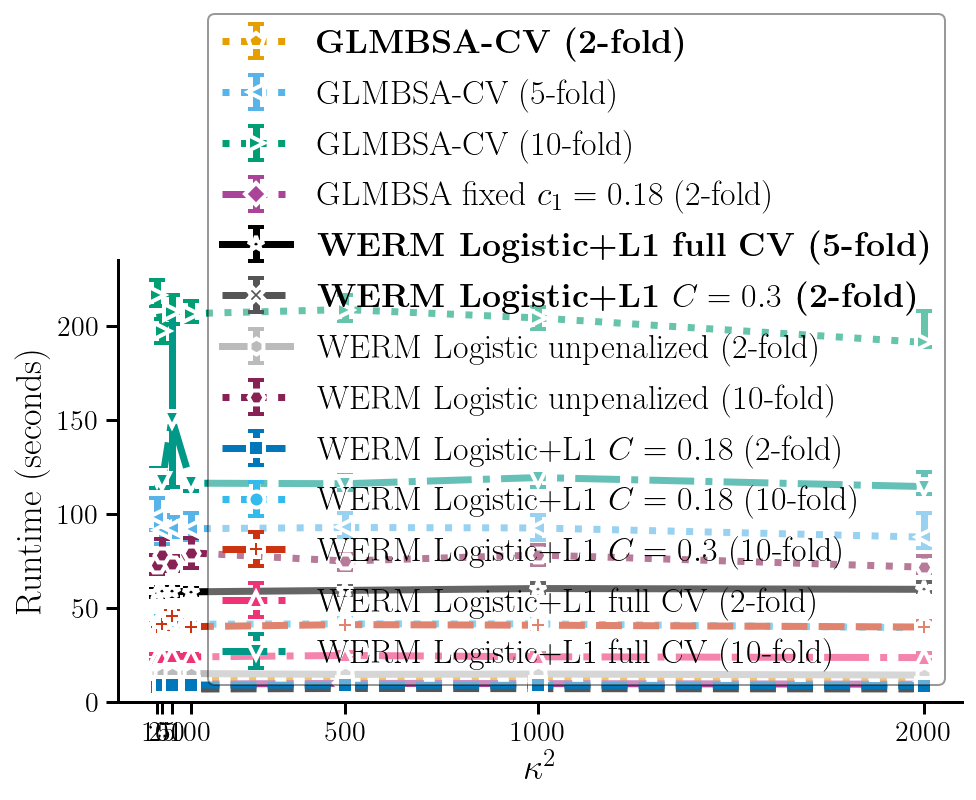


--- Plotting Distributions: boxplots + raw observations ---
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=10: n=90, unique=68, min=0.00166667, Q1=0.0970833, median=0.1575, Q3=0.20125, max=0.358333, IQR=0.104167, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV-5fold; kappa^2=10: n=92, unique=71, min=0.00166667, Q1=0.0729167, median=0.130833, Q3=0.198333, max=0.358333, IQR=0.125417, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV-10fold; kappa^2=10: n=92, unique=74, min=0.00166667, Q1=0.0691667, median=0.125833, Q3=0.197083, max=0.358333, IQR=0.127917, collapsed=False
Hausdorff distance / n; method=GLMBSA-fixed0.18-2fold; kappa^2=10: n=100, unique=78, min=0.00166667, Q1=0.055, median=0.126667, Q3=0.203333, max=0.336667, IQR=0.148333, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV; kappa^2=10: n=84, unique=66, min=0.00333333, Q1=0.0516667, median=0.124167, Q3=0.18875, max=0.336667, IQR=0.137083, collapsed=False
Hausdorff distance / n; method=WERM-L1-C

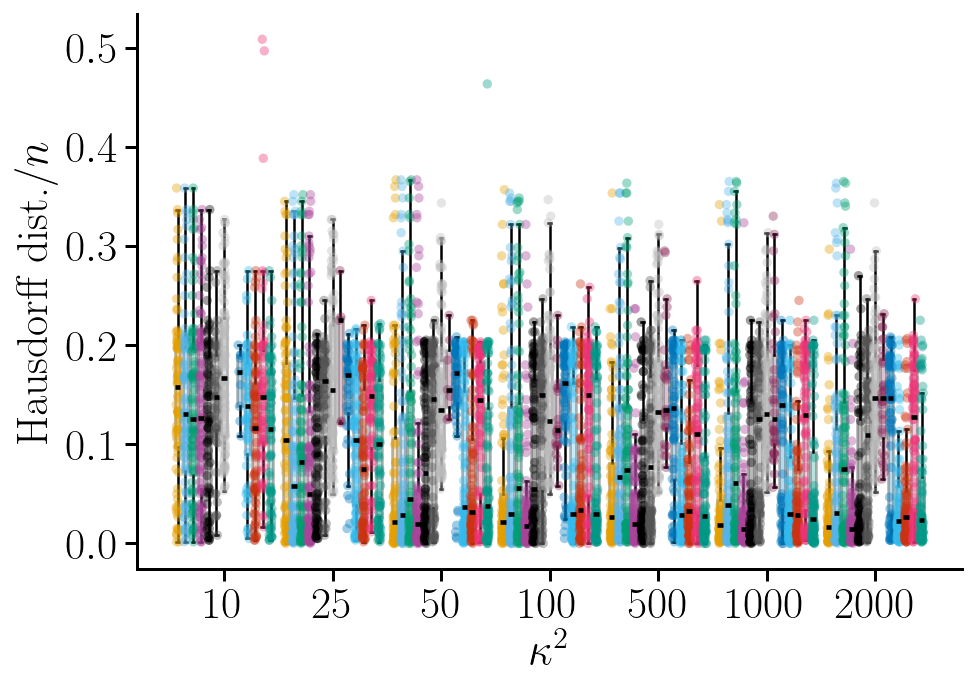

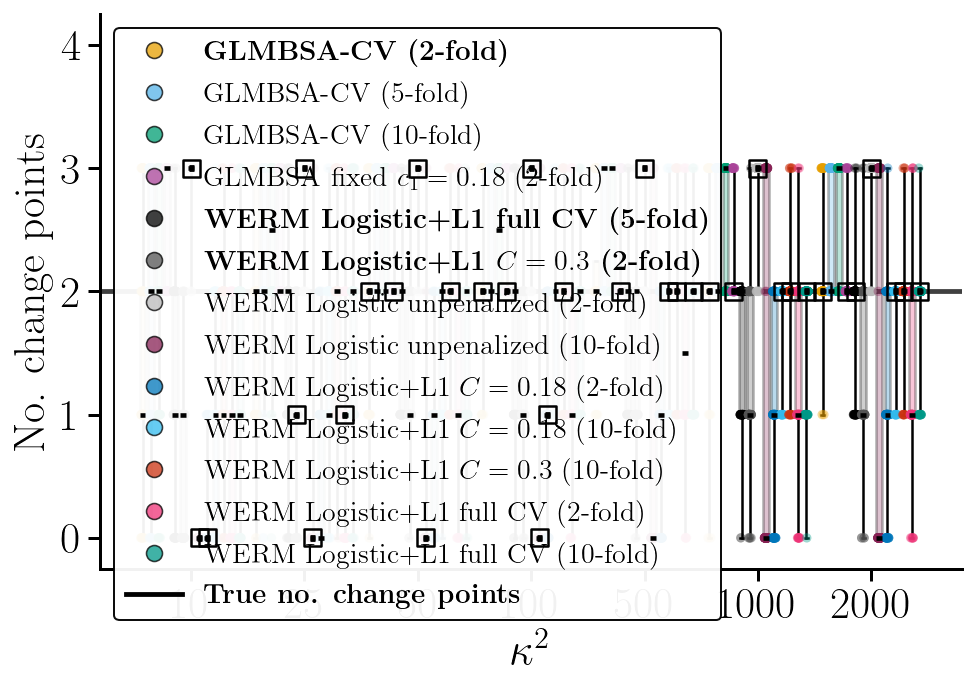

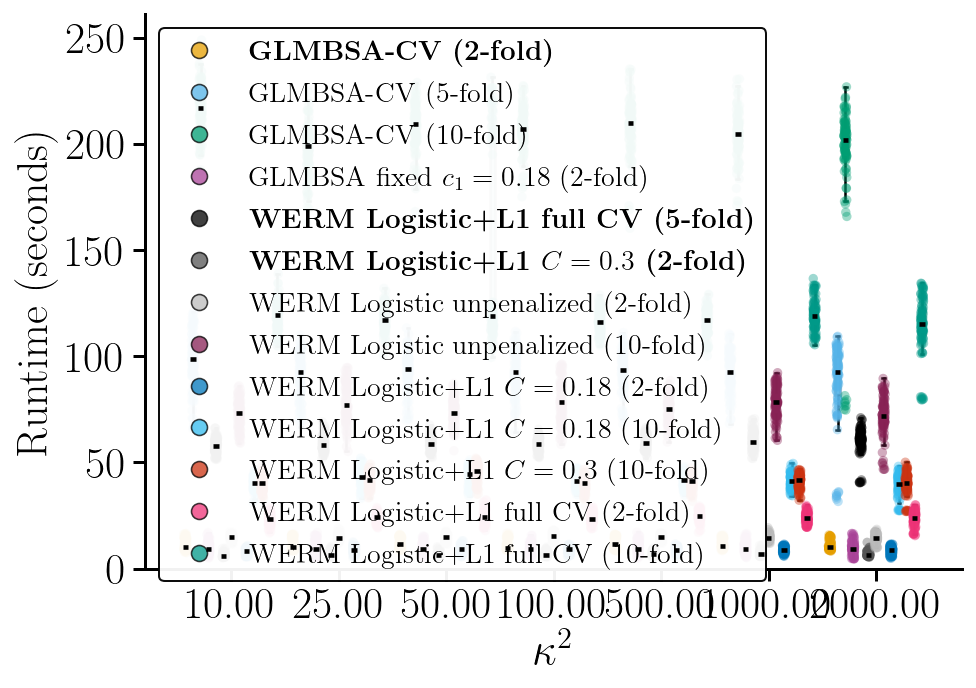


--- Plotting Changepoint Histograms ---


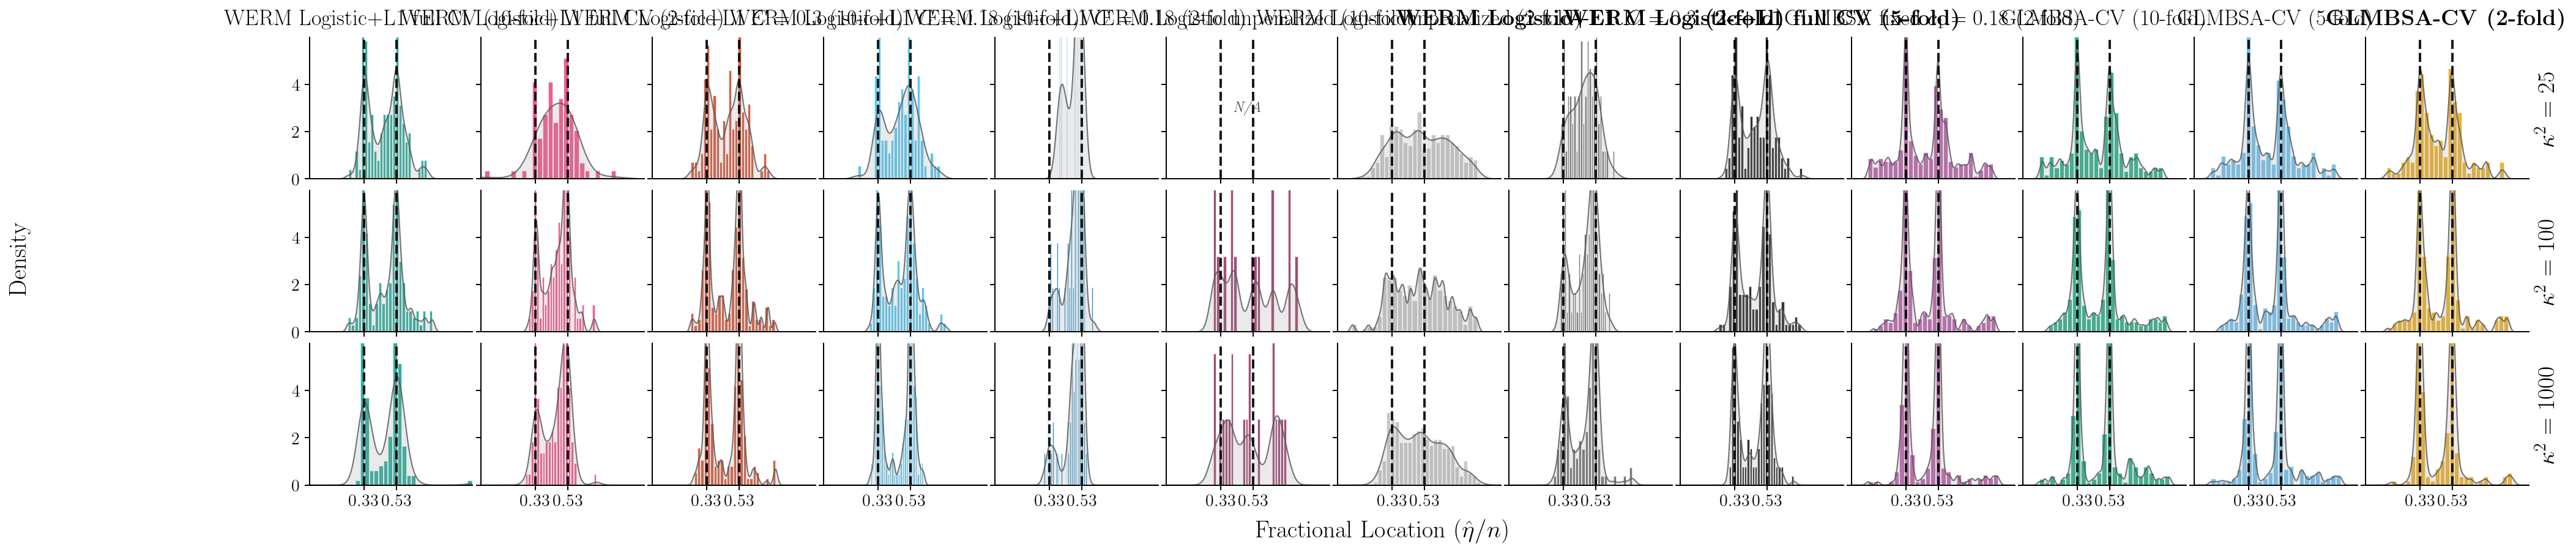

Publication-ready plotting completed in 13.93 seconds


In [2]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

methods_to_evaluate = [
    {'name': 'GLMBSA-CV', 'label': '\\textbf{GLMBSA-CV (2-fold)}', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-5fold', 'label': 'GLMBSA-CV (5-fold)', 'color': '#56B4E9', 'marker': '<', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-10fold', 'label': 'GLMBSA-CV (10-fold)', 'color': '#009E73', 'marker': '>', 'linestyle': ':'},
    {'name': 'GLMBSA-fixed0.18-2fold', 'label': 'GLMBSA fixed $c_1=0.18$ (2-fold)', 'color': '#AA4499', 'marker': 'D', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV', 'label': '\\textbf{WERM Logistic+L1 full CV (5-fold)}', 'color': 'black', 'marker': '*', 'linestyle': '-'},
    {'name': 'WERM-L1-C0.3-2fold', 'label': '\\textbf{WERM Logistic+L1 $C=0.3$ (2-fold)}', 'color': '#555555', 'marker': 'X', 'linestyle': '--'},
    {'name': 'WERM-unp-2fold', 'label': 'WERM Logistic unpenalized (2-fold)', 'color': '#BBBBBB', 'marker': 'h', 'linestyle': '-'},
    {'name': 'WERM-unp-10fold', 'label': 'WERM Logistic unpenalized (10-fold)', 'color': '#882255', 'marker': 'H', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.18-2fold', 'label': 'WERM Logistic+L1 $C=0.18$ (2-fold)', 'color': '#0077BB', 'marker': 's', 'linestyle': '--'},
    {'name': 'WERM-L1-C0.18-10fold', 'label': 'WERM Logistic+L1 $C=0.18$ (10-fold)', 'color': '#33BBEE', 'marker': 'o', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.3-10fold', 'label': 'WERM Logistic+L1 $C=0.3$ (10-fold)', 'color': '#CC3311', 'marker': 'P', 'linestyle': '--'},
    {'name': 'WERM-L1-fullCV-2fold', 'label': 'WERM Logistic+L1 full CV (2-fold)', 'color': '#EE3377', 'marker': '^', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV-10fold', 'label': 'WERM Logistic+L1 full CV (10-fold)', 'color': '#009988', 'marker': 'v', 'linestyle': '-.'},
]

method_colors_map = {method['name']: method['color'] for method in methods_to_evaluate}
PAL = [method['color'] for method in methods_to_evaluate]

# KDE / Histogram Context Style
kde_style = {
    'color': '#555555',       # Dark Grey line for definition
    'linestyle': '-',         # Solid line (distinct from competitor dashes)
    'linewidth': 1.0,         # Thinner than your methods (1.0 vs 1.5/2.5)
    'alpha': 0.8,             # Slight transparency for the line itself
    'fill_color': '#999999',  # Lighter grey for the area
    'fill_alpha': 0.2         # Very transparent fill
}

import sys
import numpy as np
import time
import matplotlib
import gc
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import pickle
import os


# Ensure the 'figures' directory exists
FIGURES_DIR = 'results/M3_upsample_redo2_plots/final_M3_upsample_format'
if not os.path.exists(FIGURES_DIR):
    os.makedirs(FIGURES_DIR)

# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except Exception:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72*2,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

try:
    # A dummy logger function to prevent NameError if main_logger is not defined
    def dummy_logger_info(message):
        print(message)
    main_logger = type('Logger', (object,), {'info': staticmethod(dummy_logger_info)})()
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()

print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data ---
# Load the completed eleven-method artifact; this cell never reruns the experiment.
filename_to_load = 'results/M3d_redo_delta3_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42_100trials.pkl'
if os.environ.get('WERM_SMOKE') == '1':
    filename_to_load = filename_to_load.replace('_100trials.pkl', '_smoke.pkl')
try:
    with open(filename_to_load, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    kappa_list = params['kappa_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    fixed_delta = params['fixed_delta']
    n_jobs = params['n_jobs']
    # methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', 42) # Get random_seed if available

    # Ensure colors are assigned from the palette in order for loaded methods
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]
    print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")
    # Change the method name from 'WERM-CV' to 'WERM'
    for method in methods_to_evaluate:
        if method['name'] == 'WERM-CV':
            method['label'] = r'\textbf{WERM}'

    method_names_list = [method['name'] for method in methods_to_evaluate]
    assert [method['name'] for method in params['methods_evaluated']] == method_names_list

except FileNotFoundError:
    print(f"Error: Results file '{filename_to_load}' not found. Please ensure your results are saved.")
    print("For demonstration, creating dummy data.")
    # Create dummy data for demonstration if file not found
    p = 200
    L = 4
    noise_std = 0.7745966692414834
    kappa_list = np.array([1, 2, 3, 4, 5]) # Example kappas
    fractional_chgpt_locations = np.array([0.2, 0.4, 0.6, 0.8])
    num_trials = 10
    n_jobs = 1
    methods_to_evaluate = [
        {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'marker': 'o', 'linestyle': '-'},
        {'name': 'WERM-CV', 'label': r'\textbf{WERM-CV}', 'marker': 's', 'linestyle': '--'},
    ]
    method_names_list = [method['name'] for method in methods_to_evaluate]

    # Assign colors from palette
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]

    results = {}
    for metric in ['haus', 'size', 'runtime', 'chgpts']:
        for method_config in methods_to_evaluate:
            method_name = method_config['name']
            key = f'{metric}_{method_name}'
            if metric == 'chgpts':
                results[key] = []
                for kappa_idx, kappa_val in enumerate(kappa_list):
                    n_for_kappa = int(kappa_val * p)
                    for _ in range(num_trials):
                        num_chgpts_detected = np.random.randint(L - 1, L + 2)
                        # Fix for histogram: Ensure dummy changepoints span 0-1 range
                        dummy_chgpts_fractional = np.random.rand(num_chgpts_detected)
                        # Scale to actual indices (0 to n_for_kappa) for storage
                        results[key].append((kappa_idx, dummy_chgpts_fractional * n_for_kappa))
            else:
                results[key] = np.random.rand(len(kappa_list), num_trials)
                if metric == 'size':
                    results[key] = np.round(results[key] * (L + 2)).astype(int)
                elif metric == 'runtime':
                    results[key] = results[key] * 10
                elif metric == 'haus':
                    results[key] = results[key] * 0.2 + 0.05
    random_seed = 42 # Set dummy seed

for method_name in method_names_list:
    _size = np.asarray(results[f'size_{method_name}'], dtype=float)
    _haus = np.asarray(results[f'haus_{method_name}'], dtype=float)
    results[f'haus_{method_name}'] = np.where(_size > 0, _haus, np.nan)

print("Data loaded for plotting; empty-estimate Hausdorff values are NaN.")

# Filter kappa_list for plotting from kappa = 1.5 and onwards
kappa_list = np.array(kappa_list) # Ensure it's a numpy array for easy filtering
kappa_start_index = np.where(kappa_list >= 1.5)[0]
if len(kappa_start_index) > 0:
    kappa_start_index = kappa_start_index[0]
else: # If no kappa >= 1.5, use the whole list or handle as an error
    kappa_start_index = 0
    print("Warning: No kappa values >= 1.5 found. Using all available kappa values for filtering.")

kappa_list_filtered = kappa_list[kappa_start_index:]

# Replace kappa list with kappa^2 values for plotting
kappa_list_filtered = np.power(kappa_list_filtered, 2)
kappa_list = np.power(kappa_list, 2)

# Filter results based on the new kappa_list for line plots and all box plots
results_filtered = {}
for key, value in results.items():
    if key.startswith(('haus_', 'size_', 'runtime_')):
        if value.shape[0] > kappa_start_index:
            results_filtered[key] = value[kappa_start_index:, :]
        else:
            results_filtered[key] = np.empty((0, value.shape[1]))

print(f"DEBUG: Original kappa_list: {kappa_list}")
print(f"DEBUG: Filtered kappa_list (>= 1.5): {kappa_list_filtered}")
print(f"DEBUG: Method names available: {method_names_list}")
print(f"DEBUG: First few haus results (filtered): {results_filtered.get('haus_GLMBSA-CV', 'Not available')[:2]}") # Changed to GLMBSA for consistency with example filename

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Asymmetric Error Bars Plotting Functions (Separated) ---

x_y_label_fontsize = 22

def plot_location_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Location Error}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'haus_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Hausdorff) for current kappa_list. Skipping plot for this metric.")
            continue
        data = np.where(np.isinf(data), np.nan, data)
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
    ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=24)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=24)
    ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.get_xaxis().set_minor_formatter(matplotlib.ticker.NullFormatter())
    # Set the tick font size larger for better readability
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=24)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=24)
    # ax.legend(loc='upper right', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pgf"))
    plt.show()

    # Replot the above, with in log-scale on the x axis
    # fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # # ax.set_title(r'\textbf{Changepoint Location Error (Log Scale)}', fontsize=18, pad=15) # Title removed 
    # for i, method_obj in enumerate(methods_to_evaluate):
    #     method_name = method_obj['name']
    #     data = current_results.get(f'haus_{method_name}')
    #     if data is None or data.size == 0 or np.all(np.isnan(data)):
    #         continue
    #     data = np.where(np.isinf(data), np.nan, data)
    #     means = np.nanmean(data, axis=1)
    #     errors = get_asymmetric_errors(data)
    #     ax.errorbar(current_kappa_list, means, yerr=errors,
    #                 label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
    #                 color=plot_colors[i], capsize=4, capthick=2, markersize=8,
    #                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    # ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    # ax.set_xlabel(r'$\kappa$ (log scale)', fontsize=18)
    # ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    # ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.tick_params(axis='both', which='major', width=1.5, length=6)
    # ax.spines['top'].set_visible(False)
    # ax.spines['right'].set_visible(False)
    # ax.spines['left'].set_linewidth(1.5)
    # ax.spines['bottom'].set_linewidth(1.5)
    # ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    # plt.tight_layout()
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pdf"))
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pgf"))
    # plt.show()

def plot_size_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Set Size}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'size_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Size) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_xscale('log')
    ax.axhline(y=len(fractional_chgpt_locations), color='gray', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'True no. change points')
    ax.set_ylim((0, L))
    ax.set_yticks(np.arange(0, L + 1, step=1).astype(int))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=x_y_label_fontsize)
    ax.set_ylabel(r'No. change points', fontsize=x_y_label_fontsize)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=x_y_label_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 20}, fancybox = True, framealpha = 0.4)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=x_y_label_fontsize)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pgf"))
    plt.show()

def plot_runtime_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Method Runtime}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'runtime_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Runtime) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\kappa^2$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pgf"))
    plt.show()

# --- Distribution Plotting Functions -----------------------------------------
#
# Three display modes are supported:
#   1. "box_jitter"      : standard boxplot + all observations (recommended)
#   2. "interval_jitter" : 5--95%, IQR, median + all observations
#   3. "violin_jitter"   : violin + IQR/median + all observations
#
# A box with Q1 == Q3 is statistically supposed to collapse.  We therefore do
# not artificially change its quartiles.  Instead, collapsed IQRs are reinforced
# with a thick horizontal line and, optionally, a hollow-square glyph.

from matplotlib.lines import Line2D


_DISTRIBUTION_STYLES = {"box_jitter", "interval_jitter", "violin_jitter"}
_COLLAPSED_STYLES = {"line", "line_and_marker", "none"}


def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }


def _warn(message):
    """Use the project logger when it supports warnings; otherwise print."""
    logger = globals().get("main_logger")
    warning_method = getattr(logger, "warning", None)
    if callable(warning_method):
        warning_method(message)
    else:
        print(f"WARNING: {message}")


def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)


def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.38,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )


def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )


def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_summary(
    ax,
    position,
    color,
    summary,
    box_width,
    collapsed_style,
):
    """Draw 5--95%, IQR, and median summaries."""
    cap_half_width = 0.14 * box_width

    # Thin 5--95% interval and end caps.
    ax.vlines(
        position,
        summary["q05"],
        summary["q95"],
        color="black",
        linewidth=1.35,
        zorder=5,
    )
    ax.hlines(
        [summary["q05"], summary["q95"]],
        position - cap_half_width,
        position + cap_half_width,
        color="black",
        linewidth=1.35,
        zorder=5,
    )

    # Thick IQR interval. It correctly becomes a point/line when IQR=0.
    ax.vlines(
        position,
        summary["q25"],
        summary["q75"],
        color=color,
        linewidth=8.0,
        alpha=0.58,
        zorder=5,
    )

    # Median remains visible even when every interval collapses.
    ax.scatter(
        [position],
        [summary["median"]],
        marker="D",
        s=46,
        facecolor=color,
        edgecolor="black",
        linewidth=0.9,
        zorder=7,
        label="_nolegend_",
    )

    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw raw observations together with quantile intervals and the median."""
    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _draw_violin_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """
    Draw a violin/raincloud-style display plus points and quantile summaries.

    The violin is omitted when there are fewer than two distinct observations,
    because a kernel density is then undefined/uninformative.
    """
    if values.size >= 2 and summary["n_unique"] >= 2:
        parts = ax.violinplot(
            [values],
            positions=[position],
            widths=1.15 * box_width,
            showmeans=False,
            showmedians=False,
            showextrema=False,
            points=100,
            bw_method="scott",
        )
        body = parts["bodies"][0]
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_linewidth(1.0)
        body.set_alpha(0.20)
        body.set_zorder(1)

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _format_distribution_diagnostic(metric_label, method_name, kappa, summary):
    return (
        f"{metric_label}; method={method_name}; kappa^2={kappa:g}: "
        f"n={summary['n']}, unique={summary['n_unique']}, "
        f"min={summary['min']:.6g}, Q1={summary['q25']:.6g}, "
        f"median={summary['median']:.6g}, Q3={summary['q75']:.6g}, "
        f"max={summary['max']:.6g}, IQR={summary['iqr']:.6g}, "
        f"collapsed={summary['collapsed']}"
    )


def _plot_grouped_distributions(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    metric_prefix,
    metric_label,
    y_label,
    filename_base,
    filename_metric,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    random_seed=2026,
    box_width=0.72,
    jitter_width=0.20,
    point_size=22,
    point_alpha=0.38,
    diagnostics=False,
    show_legend=True,
    legend_loc="upper left",
    y_limits=None,
    y_ticks=None,
    reference_y=None,
    reference_label=None,
    x_label=r'$\kappa^2$',
    tick_label_format=".0f",
):
    """Shared implementation for location, size, and runtime distributions."""
    if plot_style not in _DISTRIBUTION_STYLES:
        raise ValueError(
            f"plot_style must be one of {sorted(_DISTRIBUTION_STYLES)}, "
            f"got {plot_style!r}."
        )
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )

    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    rng = np.random.default_rng(random_seed)

    plot_labels = [method["label"] for method in methods_to_evaluate]
    plot_colors = [method["color"] for method in methods_to_evaluate]
    methods = [method["name"] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    diagnostic_records = []

    for kappa_idx, kappa in enumerate(current_kappa_list):
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f"{metric_prefix}_{method_name}")
            if data is None or data.ndim < 2 or data.shape[0] <= kappa_idx:
                _warn(
                    f"No {metric_label} data for {method_name} at "
                    f"kappa^2={kappa:g}; skipping this group."
                )
                continue

            values = _finite_1d(data[kappa_idx, :])
            if values.size == 0:
                _warn(
                    f"No finite {metric_label} observations for {method_name} "
                    f"at kappa^2={kappa:g}; skipping this group."
                )
                continue

            summary = _distribution_summary(values)
            position = kappa_idx * spacing + method_idx
            color = plot_colors[method_idx]

            record = {
                "metric": metric_label,
                "method": method_name,
                "kappa_squared": float(kappa),
                **summary,
            }
            diagnostic_records.append(record)
            if diagnostics:
                print(
                    _format_distribution_diagnostic(
                        metric_label, method_name, kappa, summary
                    )
                )

            draw_kwargs = dict(
                ax=ax,
                values=values,
                position=position,
                color=color,
                rng=rng,
                summary=summary,
                box_width=box_width,
                jitter_width=jitter_width,
                point_size=point_size,
                point_alpha=point_alpha,
                collapsed_style=collapsed_style,
            )

            if plot_style == "box_jitter":
                _draw_box_jitter_group(**draw_kwargs)
            elif plot_style == "interval_jitter":
                _draw_interval_jitter_group(**draw_kwargs)
            else:
                _draw_violin_jitter_group(**draw_kwargs)

    # Optional horizontal truth/reference line.
    if reference_y is not None:
        ax.axhline(
            y=reference_y,
            color="black",
            linestyle="-",
            linewidth=2.4,
            alpha=0.75,
            zorder=0,
            label="_nolegend_",
        )

    kappa_positions = [
        i * spacing + (len(methods) - 1) / 2
        for i in range(len(current_kappa_list))
    ]
    ax.set_xticks(kappa_positions)
    ax.set_xticklabels(
        [format(float(k), tick_label_format) for k in current_kappa_list]
    )
    ax.set_xlabel(x_label, fontsize=x_y_label_fontsize)
    ax.set_ylabel(y_label, fontsize=x_y_label_fontsize)

    if y_limits is not None:
        ax.set_ylim(*y_limits)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)

    if show_legend:
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markersize=8,
                markerfacecolor=plot_colors[i],
                markeredgecolor="black",
                markeredgewidth=0.8,
                alpha=0.75,
                label=plot_labels[i],
            )
            for i in range(len(methods))
        ]
        if reference_y is not None and reference_label is not None:
            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    color="black",
                    linewidth=2.4,
                    label=reference_label,
                )
            )
        ax.legend(
            handles=legend_elements,
            loc=legend_loc,
            fontsize=14,
            frameon=True,
            edgecolor="black",
            framealpha=0.95,
        )

    ax.tick_params(
        axis="both",
        which="major",
        width=1.5,
        length=6,
        labelsize=x_y_label_fontsize,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    # Keep the historical filenames for the recommended box+jitter mode.
    style_suffix = {
        "box_jitter": "boxplots",
        "interval_jitter": "interval_jitter",
        "violin_jitter": "violin_jitter",
    }[plot_style]
    output_stem = f"{filename_base}_{filename_metric}_{style_suffix}"

    fig.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pdf"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.png"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pgf"))
    plt.show()

    return fig, ax, diagnostic_records


def plot_location_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot the Hausdorff-error distributions.

    Recommended publication mode: plot_style="box_jitter".
    Clean alternative:             plot_style="interval_jitter".
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="haus",
        metric_label="Hausdorff distance / n",
        y_label=r'Hausdorff dist./$n$',
        filename_base=filename_base,
        filename_metric="location",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=False,
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_size_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot estimated changepoint counts.

    Because this response is discrete, box+jitter or interval+jitter is preferable
    to a violin plot, whose kernel smoothing can imply nonexistent values.
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="size",
        metric_label="Number of change points",
        y_label=r'No. change points',
        filename_base=filename_base,
        filename_metric="size",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(-0.25, L + 0.25),
        y_ticks=np.arange(0, L + 1, dtype=int),
        reference_y=len(fractional_chgpt_locations),
        reference_label=r'\textbf{True no. change points}',
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_runtime_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """Plot runtime distributions using any supported display mode."""
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="runtime",
        metric_label="Runtime (seconds)",
        y_label=r'Runtime (seconds)',
        filename_base=filename_base,
        filename_metric="runtime",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(0, None),
        tick_label_format=".2f",
        x_label=r'$\kappa^2$',
    )

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms (Optimized Layout)
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(original_results, original_kappa_list, fractional_chgpt_locations, methods_to_plot_names_, p):
    """
    Publication-ready changepoint location histograms with tight layout (Kappa variant)
    """

    # 1. Setup Data
    # Use existing method_plotting_info/methods_to_evaluate if available, else fallback
    try:
        method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
        method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    except:
        import seaborn as sns
        pal = sns.color_palette("colorblind", len(methods_to_plot_names_))
        method_names_map = {name: name.upper() for name in methods_to_plot_names_}
        method_colors_map = {name: pal[i] for i, name in enumerate(methods_to_plot_names_)}

    current_methods = methods_to_plot_names_.copy()
    # current_method_names = [method['name'] for method in current_methods] # Adaptation: input is already names list
    
    # Reverse order as per original request
    # method_names_map = {k: method_names_map[k] for k in reversed(method_names_map)} # Key error risk if iterating dict
    current_methods.reverse()
    current_method_names = current_methods

    # Kappa Selection Logic (Adapted from Template's Delta Logic)
    selected_kappas_idx = [i for i, k in enumerate(original_kappa_list) if k >= 1.5]
    selected_kappas = [original_kappa_list[i] for i in selected_kappas_idx]
    
    num_rows = len(selected_kappas)
    num_cols = len(current_methods)

    # 2. Setup Figure - TIGHTER DIMENSIONS
    # Using a roughly 3:2.5 ratio per subplot, scaled for standard latex textwidth
    # A width of 14-16 inches usually scales down perfectly to a 7 inch page width
    fig, axes = plt.subplots(num_rows, num_cols,
                             figsize=(2.5 * num_cols, 2.2 * num_rows), 
                             sharex=True, sharey=True,
                             gridspec_kw={'wspace': 0.05, 'hspace': 0.08}) # <--- KEY FOR TIGHTNESS
    
    # Handle single subplot cases to ensure axes is always 2D array
    if num_rows == 1 and num_cols == 1:
        axes = np.array([[axes]])
    elif num_cols == 1:
        axes = axes.reshape(-1, 1)
    elif num_rows == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')

    # 3. Plotting Loop
    for row, (kappa_idx, kappa) in enumerate(zip(selected_kappas_idx, selected_kappas)):
        # Calculate n based on fixed_delta (assuming global) or fallback
        try:
            n = int(fixed_delta * p)
        except:
            n = 100
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # --- Data Collection (Adapted for Kappa structure) ---
            all_chgpts = []
            chgpts_data_for_method = original_results.get(f'chgpts_{method_name}', [])
            
            for stored_kappa_idx, chgpts_list in chgpts_data_for_method:
                if stored_kappa_idx == kappa_idx:
                     # Robust handling for list-of-lists vs arrays
                    if isinstance(chgpts_list, list):
                        for chgpts_arr in chgpts_list:
                            if chgpts_arr is not None and len(chgpts_arr) > 0:
                                arr = np.array(chgpts_arr)
                                if not (np.isscalar(arr) and np.isnan(arr)):
                                    valid = arr[arr != -1]
                                    for x in valid: all_chgpts.append(x / n)
                    elif chgpts_list is not None:
                        arr = np.array(chgpts_list)
                        if arr.size > 0 and not (np.isscalar(arr) and np.isnan(arr)):
                            valid = arr[arr != -1]
                            for x in valid: all_chgpts.append(x / n)
            
            # --- Plotting ---
            if len(all_chgpts) > 0:
                # Histogram
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                color=method_colors_map.get(method_name, 'blue'),
                                                density=True, edgecolor='white',
                                                linewidth=1.0) # Thinner line for tighter look
                
                # KDE (GridSearch Logic)
                if len(all_chgpts) > 6:
                    try:
                        # Use grid search to find optimal bandwidth
                        params = {'bandwidth': np.logspace(-2, 0, 50)}
                        grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)
                        grid.fit(np.array(all_chgpts).reshape(-1, 1))
                        
                        x_range = np.linspace(0, 1, 200)
                        # Score_samples returns log-density, so we exponentiate
                        log_dens = grid.best_estimator_.score_samples(x_range.reshape(-1, 1))
                        kde_values = np.exp(log_dens)
                        
                        # --- UPDATED PLOTTING LOGIC ---
                        # 1. Plot the line (Dark Grey)
                        ax.plot(x_range, kde_values, 
                                color=kde_style['color'], 
                                linewidth=kde_style['linewidth'],
                                linestyle=kde_style['linestyle'], # Solid line for context
                                alpha=kde_style['alpha'], 
                                label='KDE', # No bolding, keep it contextual
                                zorder=2) # Low z-order to sit BEHIND methods
                        
                        # 2. Add the fill (Subtle Grey)
                        # This makes the "shape" of the data distribution easier to see
                        ax.fill_between(x_range, kde_values, 
                                        color=kde_style['fill_color'], 
                                        alpha=kde_style['fill_alpha'],
                                        zorder=1)
                    except:
                        pass
            else:
                ax.text(0.5, 0.5, r'\textit{N/A}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=12, alpha=0.7, style='italic')
            
            # True Changepoints
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', 
                           linewidth=2, alpha=0.9, zorder=10,
                           label=r'\textbf{True changepoints}' if i == 0 else "")

            # --- Formatting & Ticks ---
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 6) # Enforce uniform height
            
            # Clean spines
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.0)
            ax.spines['bottom'].set_linewidth(1.0)
            
            # Custom ticks - apply to ALL, but sharex hides labels automatically
            ax.set_xticks(np.array([*fractional_chgpt_locations]))
            # ax.set_xticklabels([*[f'${tc:.2f}$' for tc in fractional_chgpt_locations]], fontsize=12)
            ax.set_xticklabels(['$0.33$', '$0.53$'], fontsize=10)
            ax.set_yticks([0, 2, 4]) # Minimal Y-ticks
            
            # Tick parameters
            # 'labelleft' and 'labelbottom' control visibility explicitly if sharex/y fails
            ax.tick_params(axis='both', which='major', width=1, length=4, labelsize=14)

            # 4. Labels and Titles (Specific Locations Only)
            
            # Column Titles (Method Names) - Only Top Row
            if row == 0:
                ax.set_title(f'{method_names_map.get(method_name, method_name)}', fontsize=18, pad=10)
            
            # Row Labels (Kappa) - Right side of Last Column
            if col == num_cols - 1:
                # Use ax.text roughly in the middle right
                ax.text(1.05, 0.5, rf'$\kappa$\textsuperscript{{2}} $= {kappa:.0f}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', horizontalalignment='left',
                        fontsize=20, fontweight='bold')

            # X-Axis Label - Bottom Row, Centered on Figure not Subplot
            # We skip per-subplot labels to save space
    
    # Global Labels (cleaner than per-subplot)
    fig.text(0.5, 0.01, r'Fractional Location ($\hat{\mathbf{\eta}}/n$)', 
             ha='center', va='bottom', fontsize=20)
    fig.text(0.02, 0.5, r'Density', 
             va='center', rotation='vertical', fontsize=20)

    # 5. Legend
    # Place one legend for the whole figure, or inside the first visible plot
    # Here we put it in the first plot, but make it compact
    first_ax = axes[0, 0]
    handles, labels = first_ax.get_legend_handles_labels()
    # if handles:
    #     # Create a legend that floats slightly inside the plot
    #     legend = first_ax.legend(loc='upper right', fontsize=18, frameon=True,
    #                              edgecolor='white', framealpha=0.8, handlelength=1.5)
    #     legend.set_zorder(20)

    # Final Tight Layout to handle the global labels
    # rect tuple is (left, bottom, right, top)
    plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96]) 
    
    return fig, axes

# Get a base filename for saving figures based on the loaded data's properties
# This uses the original filename from which data was loaded to create a consistent naming convention
filename_base_for_plots = 'final_M3_upsample_format_' + os.path.basename(filename_to_load).replace('.pkl', '')
print(f"Base filename for saving plots: {filename_base_for_plots}")

# --- Execute plotting functions ---
print("\n--- Plotting Asymmetric Error Bars ---")
plot_location_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_size_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_runtime_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots)

print("\n--- Plotting Distributions: boxplots + raw observations ---")

# Recommended figure: retain the familiar boxplot, but show every repetition.
# Set this to False after you have diagnosed the collapsed groups once.
PRINT_DISTRIBUTION_DIAGNOSTICS = True

plot_location_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=PRINT_DISTRIBUTION_DIAGNOSTICS,
)
plot_size_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)
plot_runtime_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)

# Optional alternative outputs. These use distinct filenames, so they do not
# overwrite the recommended box+jitter figures.
PLOT_ALTERNATIVE_DISTRIBUTIONS = False
if PLOT_ALTERNATIVE_DISTRIBUTIONS:
    print("\n--- Plotting Distributions: quantile intervals + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_size_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        L,
        fractional_chgpt_locations,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )

    # Violin plots are optional for continuous metrics. They are deliberately
    # not generated for the integer-valued changepoint-count metric.
    print("\n--- Plotting Distributions: violin + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )

print("\n--- Plotting Changepoint Histograms ---")
fig_hist, axes_hist = plot_changepoint_histograms_publication(results, kappa_list[::2], fractional_chgpt_locations, method_names_list, p=p)
_histogram_stem = os.path.join(FIGURES_DIR, f'{filename_base_for_plots}_changepoint_histograms')
fig_hist.savefig(f'{_histogram_stem}.pdf', dpi=300, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.png', dpi=200, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.pgf', dpi=300, bbox_inches='tight')
plt.show()


plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

### Two-method comparison: 2-fold full CV only

Removing 100 matplotlib modules...
Successfully set backend to: module://matplotlib_inline.backend_inline
Creating publication-ready plots...
Using palette: ['#E69F00', '#EE3377'] (Paul Tol Vibrant)


Using palette: ['#E69F00', '#EE3377'] (Paul Tol Vibrant assigned to methods)
Data loaded for plotting; empty-estimate Hausdorff values are NaN.
DEBUG: Original kappa_list: [1.0e+00 1.0e+01 2.5e+01 5.0e+01 1.0e+02 5.0e+02 1.0e+03 2.0e+03]
DEBUG: Filtered kappa_list (>= 1.5): [  10.   25.   50.  100.  500. 1000. 2000.]
DEBUG: Method names available: ['GLMBSA-CV', 'WERM-L1-fullCV-2fold']
DEBUG: First few haus results (filtered): [[0.00833333        nan 0.09833333 0.33666667 0.13333333 0.23666667
  0.07166667        nan 0.20333333 0.35833333 0.01333333 0.105
  0.00166667        nan 0.21166667 0.13166667 0.115      0.18
  0.13       0.215      0.115      0.20166667 0.01              nan
  0.17166667 0.20833333 0.09166667 0.21333333 0.03666667 0.20333333
  0.24666667 0.31666667 0.20833333 0.205      0.00166667 0.18166667
  0.195      0.19833333        nan 0.26833333 0.01333333 0.115
         nan 0.19833333 0.03166667 0.285      0.17       0.235
  0.05       0.20166667 0.11333333 0.045      0

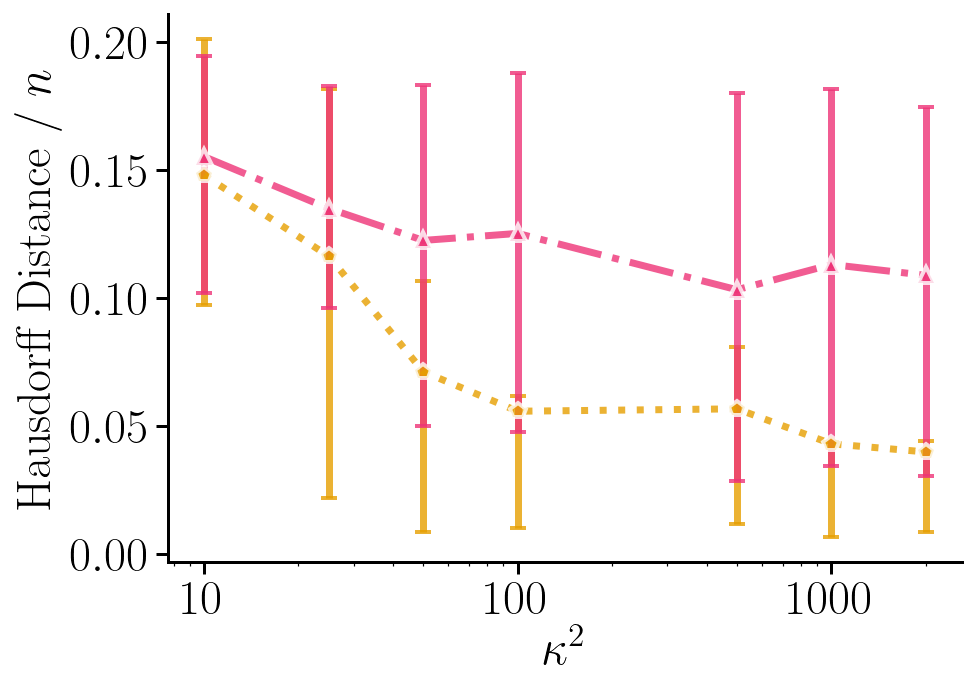

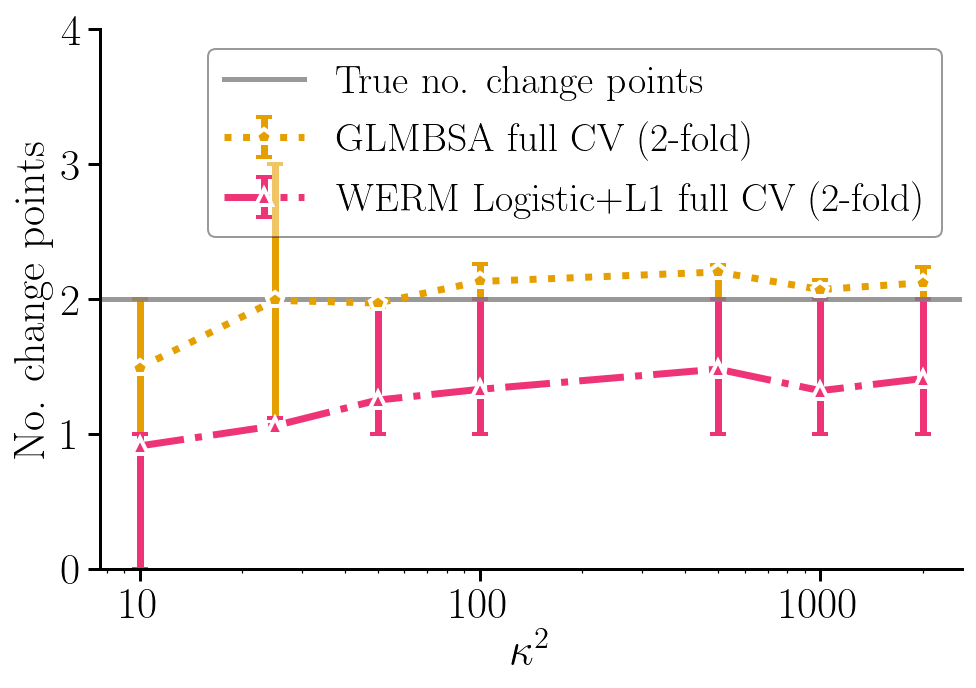

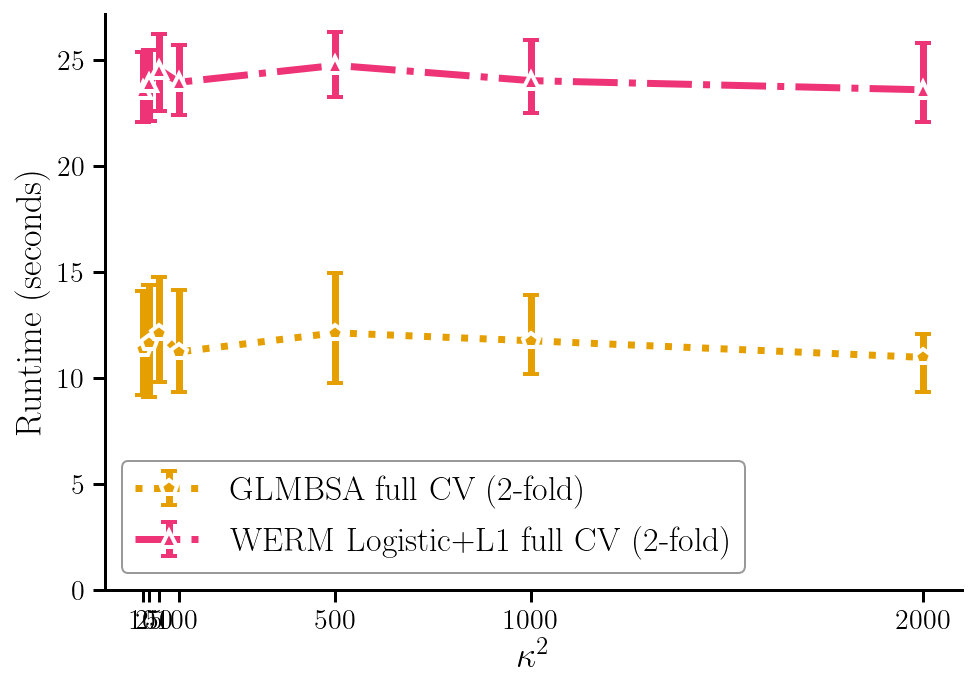


--- Plotting Distributions: boxplots + raw observations ---
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=10: n=90, unique=68, min=0.00166667, Q1=0.0970833, median=0.1575, Q3=0.20125, max=0.358333, IQR=0.104167, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV-2fold; kappa^2=10: n=66, unique=54, min=0.0166667, Q1=0.102083, median=0.1475, Q3=0.194583, max=0.508333, IQR=0.0925, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=25: n=98, unique=69, min=0, Q1=0.0216667, median=0.104167, Q3=0.181667, max=0.345, IQR=0.16, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV-2fold; kappa^2=25: n=78, unique=55, min=0.0116667, Q1=0.09625, median=0.149167, Q3=0.182917, max=0.245, IQR=0.0866667, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=50: n=99, unique=57, min=0, Q1=0.00833333, median=0.0216667, Q3=0.106667, max=0.366667, IQR=0.0983333, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV-2fold; kappa^2=50: n=91, unique=

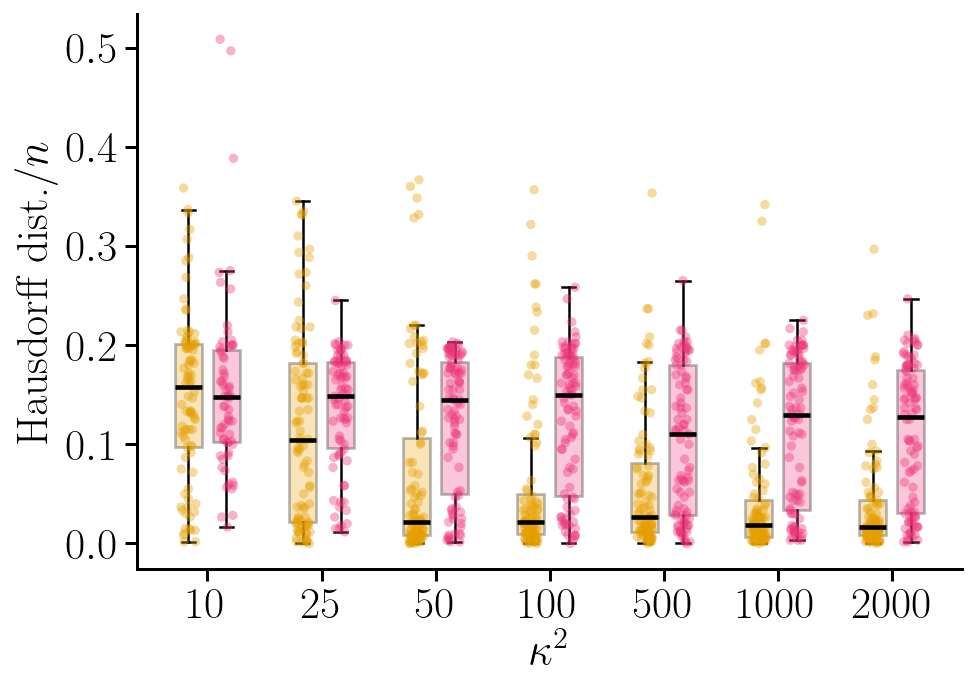

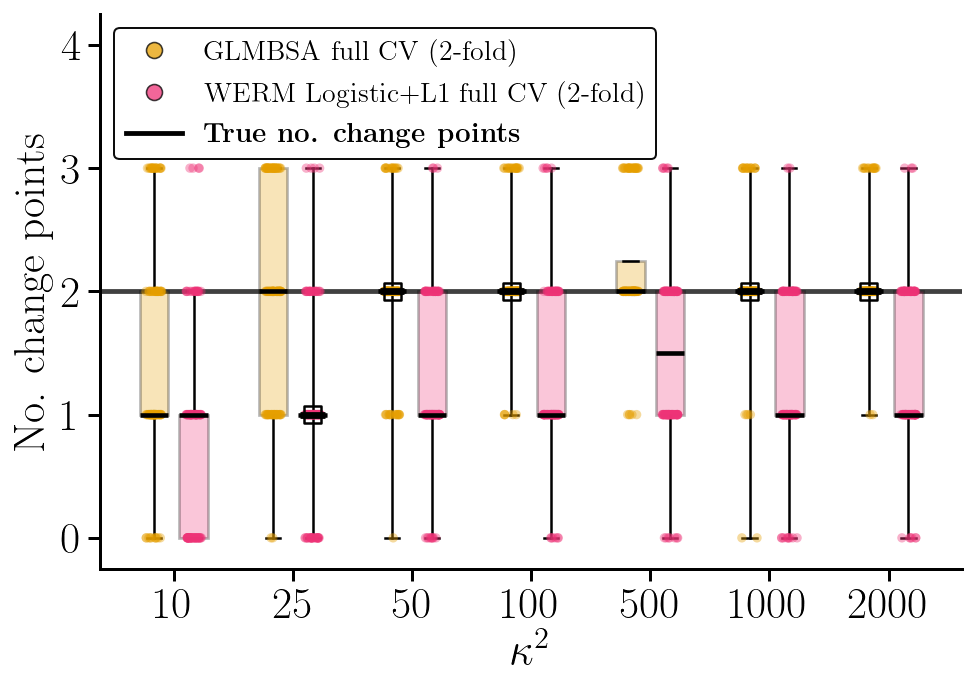

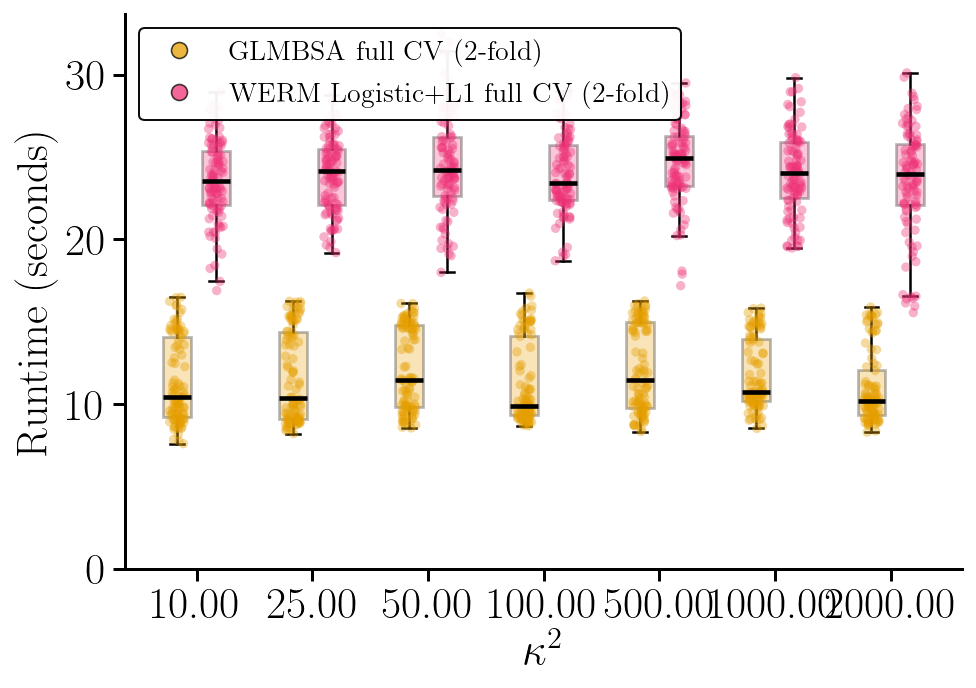


--- Plotting Changepoint Histograms ---


/tmp/ipykernel_245321/1305482123.py:1270: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96])


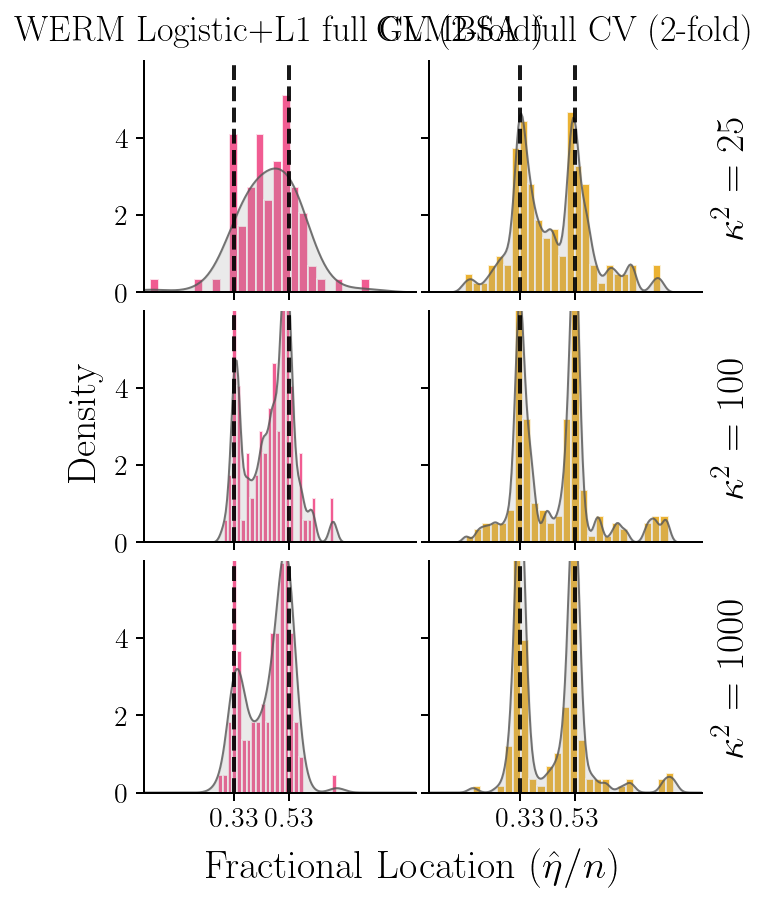

Publication-ready plotting completed in 5.39 seconds


In [1]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

methods_to_evaluate = [
    {'name': 'GLMBSA-CV', 'label': r'GLMBSA full CV (2-fold)', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'},
    {'name': 'WERM-L1-fullCV-2fold', 'label': r'WERM Logistic+L1 full CV (2-fold)', 'color': '#EE3377', 'marker': '^', 'linestyle': '-.'},
]

method_colors_map = {method['name']: method['color'] for method in methods_to_evaluate}
PAL = [method['color'] for method in methods_to_evaluate]

# KDE / Histogram Context Style
kde_style = {
    'color': '#555555',       # Dark Grey line for definition
    'linestyle': '-',         # Solid line (distinct from competitor dashes)
    'linewidth': 1.0,         # Thinner than your methods (1.0 vs 1.5/2.5)
    'alpha': 0.8,             # Slight transparency for the line itself
    'fill_color': '#999999',  # Lighter grey for the area
    'fill_alpha': 0.2         # Very transparent fill
}

import sys
import numpy as np
import time
import matplotlib
import gc
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import pickle
import os


# Ensure the 'figures' directory exists
FIGURES_DIR = 'results/M3_upsample_redo2_plots/final_M3_upsample_format'
if not os.path.exists(FIGURES_DIR):
    os.makedirs(FIGURES_DIR)

# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except Exception:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72*2,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

try:
    # A dummy logger function to prevent NameError if main_logger is not defined
    def dummy_logger_info(message):
        print(message)
    main_logger = type('Logger', (object,), {'info': staticmethod(dummy_logger_info)})()
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()

print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data ---
# Load the completed eleven-method artifact; this cell never reruns the experiment.
filename_to_load = 'results/M3d_redo_delta3_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42_100trials.pkl'
if os.environ.get('WERM_SMOKE') == '1':
    filename_to_load = filename_to_load.replace('_100trials.pkl', '_smoke.pkl')
try:
    with open(filename_to_load, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    kappa_list = params['kappa_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    fixed_delta = params['fixed_delta']
    n_jobs = params['n_jobs']
    # methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', 42) # Get random_seed if available

    # Ensure colors are assigned from the palette in order for loaded methods
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]
    print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")
    # Change the method name from 'WERM-CV' to 'WERM'
    for method in methods_to_evaluate:
        if method['name'] == 'WERM-CV':
            method['label'] = r'\textbf{WERM}'

    method_names_list = [method['name'] for method in methods_to_evaluate]
    available_method_names = {method['name'] for method in params['methods_evaluated']}
    assert set(method_names_list).issubset(available_method_names)

except FileNotFoundError:
    print(f"Error: Results file '{filename_to_load}' not found. Please ensure your results are saved.")
    print("For demonstration, creating dummy data.")
    # Create dummy data for demonstration if file not found
    p = 200
    L = 4
    noise_std = 0.7745966692414834
    kappa_list = np.array([1, 2, 3, 4, 5]) # Example kappas
    fractional_chgpt_locations = np.array([0.2, 0.4, 0.6, 0.8])
    num_trials = 10
    n_jobs = 1
    methods_to_evaluate = [
        {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'marker': 'o', 'linestyle': '-'},
        {'name': 'WERM-CV', 'label': r'\textbf{WERM-CV}', 'marker': 's', 'linestyle': '--'},
    ]
    method_names_list = [method['name'] for method in methods_to_evaluate]

    # Assign colors from palette
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]

    results = {}
    for metric in ['haus', 'size', 'runtime', 'chgpts']:
        for method_config in methods_to_evaluate:
            method_name = method_config['name']
            key = f'{metric}_{method_name}'
            if metric == 'chgpts':
                results[key] = []
                for kappa_idx, kappa_val in enumerate(kappa_list):
                    n_for_kappa = int(kappa_val * p)
                    for _ in range(num_trials):
                        num_chgpts_detected = np.random.randint(L - 1, L + 2)
                        # Fix for histogram: Ensure dummy changepoints span 0-1 range
                        dummy_chgpts_fractional = np.random.rand(num_chgpts_detected)
                        # Scale to actual indices (0 to n_for_kappa) for storage
                        results[key].append((kappa_idx, dummy_chgpts_fractional * n_for_kappa))
            else:
                results[key] = np.random.rand(len(kappa_list), num_trials)
                if metric == 'size':
                    results[key] = np.round(results[key] * (L + 2)).astype(int)
                elif metric == 'runtime':
                    results[key] = results[key] * 10
                elif metric == 'haus':
                    results[key] = results[key] * 0.2 + 0.05
    random_seed = 42 # Set dummy seed

for method_name in method_names_list:
    _size = np.asarray(results[f'size_{method_name}'], dtype=float)
    _haus = np.asarray(results[f'haus_{method_name}'], dtype=float)
    results[f'haus_{method_name}'] = np.where(_size > 0, _haus, np.nan)

print("Data loaded for plotting; empty-estimate Hausdorff values are NaN.")

# Filter kappa_list for plotting from kappa = 1.5 and onwards
kappa_list = np.array(kappa_list) # Ensure it's a numpy array for easy filtering
kappa_start_index = np.where(kappa_list >= 1.5)[0]
if len(kappa_start_index) > 0:
    kappa_start_index = kappa_start_index[0]
else: # If no kappa >= 1.5, use the whole list or handle as an error
    kappa_start_index = 0
    print("Warning: No kappa values >= 1.5 found. Using all available kappa values for filtering.")

kappa_list_filtered = kappa_list[kappa_start_index:]

# Replace kappa list with kappa^2 values for plotting
kappa_list_filtered = np.power(kappa_list_filtered, 2)
kappa_list = np.power(kappa_list, 2)

# Filter results based on the new kappa_list for line plots and all box plots
results_filtered = {}
for key, value in results.items():
    if key.startswith(('haus_', 'size_', 'runtime_')):
        if value.shape[0] > kappa_start_index:
            results_filtered[key] = value[kappa_start_index:, :]
        else:
            results_filtered[key] = np.empty((0, value.shape[1]))

print(f"DEBUG: Original kappa_list: {kappa_list}")
print(f"DEBUG: Filtered kappa_list (>= 1.5): {kappa_list_filtered}")
print(f"DEBUG: Method names available: {method_names_list}")
print(f"DEBUG: First few haus results (filtered): {results_filtered.get('haus_GLMBSA-CV', 'Not available')[:2]}") # Changed to GLMBSA for consistency with example filename

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Asymmetric Error Bars Plotting Functions (Separated) ---

x_y_label_fontsize = 22

def plot_location_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Location Error}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'haus_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Hausdorff) for current kappa_list. Skipping plot for this metric.")
            continue
        data = np.where(np.isinf(data), np.nan, data)
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
    ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=24)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=24)
    ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.get_xaxis().set_minor_formatter(matplotlib.ticker.NullFormatter())
    # Set the tick font size larger for better readability
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=24)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=24)
    # ax.legend(loc='upper right', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pgf"))
    plt.show()

    # Replot the above, with in log-scale on the x axis
    # fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # # ax.set_title(r'\textbf{Changepoint Location Error (Log Scale)}', fontsize=18, pad=15) # Title removed 
    # for i, method_obj in enumerate(methods_to_evaluate):
    #     method_name = method_obj['name']
    #     data = current_results.get(f'haus_{method_name}')
    #     if data is None or data.size == 0 or np.all(np.isnan(data)):
    #         continue
    #     data = np.where(np.isinf(data), np.nan, data)
    #     means = np.nanmean(data, axis=1)
    #     errors = get_asymmetric_errors(data)
    #     ax.errorbar(current_kappa_list, means, yerr=errors,
    #                 label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
    #                 color=plot_colors[i], capsize=4, capthick=2, markersize=8,
    #                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    # ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    # ax.set_xlabel(r'$\kappa$ (log scale)', fontsize=18)
    # ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    # ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.tick_params(axis='both', which='major', width=1.5, length=6)
    # ax.spines['top'].set_visible(False)
    # ax.spines['right'].set_visible(False)
    # ax.spines['left'].set_linewidth(1.5)
    # ax.spines['bottom'].set_linewidth(1.5)
    # ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    # plt.tight_layout()
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pdf"))
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pgf"))
    # plt.show()

def plot_size_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Set Size}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'size_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Size) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_xscale('log')
    ax.axhline(y=len(fractional_chgpt_locations), color='gray', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'True no. change points')
    ax.set_ylim((0, L))
    ax.set_yticks(np.arange(0, L + 1, step=1).astype(int))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=x_y_label_fontsize)
    ax.set_ylabel(r'No. change points', fontsize=x_y_label_fontsize)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=x_y_label_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 20}, fancybox = True, framealpha = 0.4)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=x_y_label_fontsize)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pgf"))
    plt.show()

def plot_runtime_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Method Runtime}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'runtime_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Runtime) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\kappa^2$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pgf"))
    plt.show()

# --- Distribution Plotting Functions -----------------------------------------
#
# Three display modes are supported:
#   1. "box_jitter"      : standard boxplot + all observations (recommended)
#   2. "interval_jitter" : 5--95%, IQR, median + all observations
#   3. "violin_jitter"   : violin + IQR/median + all observations
#
# A box with Q1 == Q3 is statistically supposed to collapse.  We therefore do
# not artificially change its quartiles.  Instead, collapsed IQRs are reinforced
# with a thick horizontal line and, optionally, a hollow-square glyph.

from matplotlib.lines import Line2D


_DISTRIBUTION_STYLES = {"box_jitter", "interval_jitter", "violin_jitter"}
_COLLAPSED_STYLES = {"line", "line_and_marker", "none"}


def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }


def _warn(message):
    """Use the project logger when it supports warnings; otherwise print."""
    logger = globals().get("main_logger")
    warning_method = getattr(logger, "warning", None)
    if callable(warning_method):
        warning_method(message)
    else:
        print(f"WARNING: {message}")


def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)


def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.38,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )


def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )


def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_summary(
    ax,
    position,
    color,
    summary,
    box_width,
    collapsed_style,
):
    """Draw 5--95%, IQR, and median summaries."""
    cap_half_width = 0.14 * box_width

    # Thin 5--95% interval and end caps.
    ax.vlines(
        position,
        summary["q05"],
        summary["q95"],
        color="black",
        linewidth=1.35,
        zorder=5,
    )
    ax.hlines(
        [summary["q05"], summary["q95"]],
        position - cap_half_width,
        position + cap_half_width,
        color="black",
        linewidth=1.35,
        zorder=5,
    )

    # Thick IQR interval. It correctly becomes a point/line when IQR=0.
    ax.vlines(
        position,
        summary["q25"],
        summary["q75"],
        color=color,
        linewidth=8.0,
        alpha=0.58,
        zorder=5,
    )

    # Median remains visible even when every interval collapses.
    ax.scatter(
        [position],
        [summary["median"]],
        marker="D",
        s=46,
        facecolor=color,
        edgecolor="black",
        linewidth=0.9,
        zorder=7,
        label="_nolegend_",
    )

    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw raw observations together with quantile intervals and the median."""
    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _draw_violin_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """
    Draw a violin/raincloud-style display plus points and quantile summaries.

    The violin is omitted when there are fewer than two distinct observations,
    because a kernel density is then undefined/uninformative.
    """
    if values.size >= 2 and summary["n_unique"] >= 2:
        parts = ax.violinplot(
            [values],
            positions=[position],
            widths=1.15 * box_width,
            showmeans=False,
            showmedians=False,
            showextrema=False,
            points=100,
            bw_method="scott",
        )
        body = parts["bodies"][0]
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_linewidth(1.0)
        body.set_alpha(0.20)
        body.set_zorder(1)

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _format_distribution_diagnostic(metric_label, method_name, kappa, summary):
    return (
        f"{metric_label}; method={method_name}; kappa^2={kappa:g}: "
        f"n={summary['n']}, unique={summary['n_unique']}, "
        f"min={summary['min']:.6g}, Q1={summary['q25']:.6g}, "
        f"median={summary['median']:.6g}, Q3={summary['q75']:.6g}, "
        f"max={summary['max']:.6g}, IQR={summary['iqr']:.6g}, "
        f"collapsed={summary['collapsed']}"
    )


def _plot_grouped_distributions(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    metric_prefix,
    metric_label,
    y_label,
    filename_base,
    filename_metric,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    random_seed=2026,
    box_width=0.72,
    jitter_width=0.20,
    point_size=22,
    point_alpha=0.38,
    diagnostics=False,
    show_legend=True,
    legend_loc="upper left",
    y_limits=None,
    y_ticks=None,
    reference_y=None,
    reference_label=None,
    x_label=r'$\kappa^2$',
    tick_label_format=".0f",
):
    """Shared implementation for location, size, and runtime distributions."""
    if plot_style not in _DISTRIBUTION_STYLES:
        raise ValueError(
            f"plot_style must be one of {sorted(_DISTRIBUTION_STYLES)}, "
            f"got {plot_style!r}."
        )
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )

    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    rng = np.random.default_rng(random_seed)

    plot_labels = [method["label"] for method in methods_to_evaluate]
    plot_colors = [method["color"] for method in methods_to_evaluate]
    methods = [method["name"] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    diagnostic_records = []

    for kappa_idx, kappa in enumerate(current_kappa_list):
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f"{metric_prefix}_{method_name}")
            if data is None or data.ndim < 2 or data.shape[0] <= kappa_idx:
                _warn(
                    f"No {metric_label} data for {method_name} at "
                    f"kappa^2={kappa:g}; skipping this group."
                )
                continue

            values = _finite_1d(data[kappa_idx, :])
            if values.size == 0:
                _warn(
                    f"No finite {metric_label} observations for {method_name} "
                    f"at kappa^2={kappa:g}; skipping this group."
                )
                continue

            summary = _distribution_summary(values)
            position = kappa_idx * spacing + method_idx
            color = plot_colors[method_idx]

            record = {
                "metric": metric_label,
                "method": method_name,
                "kappa_squared": float(kappa),
                **summary,
            }
            diagnostic_records.append(record)
            if diagnostics:
                print(
                    _format_distribution_diagnostic(
                        metric_label, method_name, kappa, summary
                    )
                )

            draw_kwargs = dict(
                ax=ax,
                values=values,
                position=position,
                color=color,
                rng=rng,
                summary=summary,
                box_width=box_width,
                jitter_width=jitter_width,
                point_size=point_size,
                point_alpha=point_alpha,
                collapsed_style=collapsed_style,
            )

            if plot_style == "box_jitter":
                _draw_box_jitter_group(**draw_kwargs)
            elif plot_style == "interval_jitter":
                _draw_interval_jitter_group(**draw_kwargs)
            else:
                _draw_violin_jitter_group(**draw_kwargs)

    # Optional horizontal truth/reference line.
    if reference_y is not None:
        ax.axhline(
            y=reference_y,
            color="black",
            linestyle="-",
            linewidth=2.4,
            alpha=0.75,
            zorder=0,
            label="_nolegend_",
        )

    kappa_positions = [
        i * spacing + (len(methods) - 1) / 2
        for i in range(len(current_kappa_list))
    ]
    ax.set_xticks(kappa_positions)
    ax.set_xticklabels(
        [format(float(k), tick_label_format) for k in current_kappa_list]
    )
    ax.set_xlabel(x_label, fontsize=x_y_label_fontsize)
    ax.set_ylabel(y_label, fontsize=x_y_label_fontsize)

    if y_limits is not None:
        ax.set_ylim(*y_limits)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)

    if show_legend:
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markersize=8,
                markerfacecolor=plot_colors[i],
                markeredgecolor="black",
                markeredgewidth=0.8,
                alpha=0.75,
                label=plot_labels[i],
            )
            for i in range(len(methods))
        ]
        if reference_y is not None and reference_label is not None:
            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    color="black",
                    linewidth=2.4,
                    label=reference_label,
                )
            )
        ax.legend(
            handles=legend_elements,
            loc=legend_loc,
            fontsize=14,
            frameon=True,
            edgecolor="black",
            framealpha=0.95,
        )

    ax.tick_params(
        axis="both",
        which="major",
        width=1.5,
        length=6,
        labelsize=x_y_label_fontsize,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    # Keep the historical filenames for the recommended box+jitter mode.
    style_suffix = {
        "box_jitter": "boxplots",
        "interval_jitter": "interval_jitter",
        "violin_jitter": "violin_jitter",
    }[plot_style]
    output_stem = f"{filename_base}_{filename_metric}_{style_suffix}"

    fig.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pdf"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.png"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pgf"))
    plt.show()

    return fig, ax, diagnostic_records


def plot_location_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot the Hausdorff-error distributions.

    Recommended publication mode: plot_style="box_jitter".
    Clean alternative:             plot_style="interval_jitter".
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="haus",
        metric_label="Hausdorff distance / n",
        y_label=r'Hausdorff dist./$n$',
        filename_base=filename_base,
        filename_metric="location",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=False,
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_size_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot estimated changepoint counts.

    Because this response is discrete, box+jitter or interval+jitter is preferable
    to a violin plot, whose kernel smoothing can imply nonexistent values.
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="size",
        metric_label="Number of change points",
        y_label=r'No. change points',
        filename_base=filename_base,
        filename_metric="size",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(-0.25, L + 0.25),
        y_ticks=np.arange(0, L + 1, dtype=int),
        reference_y=len(fractional_chgpt_locations),
        reference_label=r'\textbf{True no. change points}',
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_runtime_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """Plot runtime distributions using any supported display mode."""
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="runtime",
        metric_label="Runtime (seconds)",
        y_label=r'Runtime (seconds)',
        filename_base=filename_base,
        filename_metric="runtime",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(0, None),
        tick_label_format=".2f",
        x_label=r'$\kappa^2$',
    )

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms (Optimized Layout)
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(original_results, original_kappa_list, fractional_chgpt_locations, methods_to_plot_names_, p):
    """
    Publication-ready changepoint location histograms with tight layout (Kappa variant)
    """

    # 1. Setup Data
    # Use existing method_plotting_info/methods_to_evaluate if available, else fallback
    try:
        method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
        method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    except:
        import seaborn as sns
        pal = sns.color_palette("colorblind", len(methods_to_plot_names_))
        method_names_map = {name: name.upper() for name in methods_to_plot_names_}
        method_colors_map = {name: pal[i] for i, name in enumerate(methods_to_plot_names_)}

    current_methods = methods_to_plot_names_.copy()
    # current_method_names = [method['name'] for method in current_methods] # Adaptation: input is already names list
    
    # Reverse order as per original request
    # method_names_map = {k: method_names_map[k] for k in reversed(method_names_map)} # Key error risk if iterating dict
    current_methods.reverse()
    current_method_names = current_methods

    # Kappa Selection Logic (Adapted from Template's Delta Logic)
    selected_kappas_idx = [i for i, k in enumerate(original_kappa_list) if k >= 1.5]
    selected_kappas = [original_kappa_list[i] for i in selected_kappas_idx]
    
    num_rows = len(selected_kappas)
    num_cols = len(current_methods)

    # 2. Setup Figure - TIGHTER DIMENSIONS
    # Using a roughly 3:2.5 ratio per subplot, scaled for standard latex textwidth
    # A width of 14-16 inches usually scales down perfectly to a 7 inch page width
    fig, axes = plt.subplots(num_rows, num_cols,
                             figsize=(2.5 * num_cols, 2.2 * num_rows), 
                             sharex=True, sharey=True,
                             gridspec_kw={'wspace': 0.05, 'hspace': 0.08}) # <--- KEY FOR TIGHTNESS
    
    # Handle single subplot cases to ensure axes is always 2D array
    if num_rows == 1 and num_cols == 1:
        axes = np.array([[axes]])
    elif num_cols == 1:
        axes = axes.reshape(-1, 1)
    elif num_rows == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')

    # 3. Plotting Loop
    for row, (kappa_idx, kappa) in enumerate(zip(selected_kappas_idx, selected_kappas)):
        # Calculate n based on fixed_delta (assuming global) or fallback
        try:
            n = int(fixed_delta * p)
        except:
            n = 100
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # --- Data Collection (Adapted for Kappa structure) ---
            all_chgpts = []
            chgpts_data_for_method = original_results.get(f'chgpts_{method_name}', [])
            
            for stored_kappa_idx, chgpts_list in chgpts_data_for_method:
                if stored_kappa_idx == kappa_idx:
                     # Robust handling for list-of-lists vs arrays
                    if isinstance(chgpts_list, list):
                        for chgpts_arr in chgpts_list:
                            if chgpts_arr is not None and len(chgpts_arr) > 0:
                                arr = np.array(chgpts_arr)
                                if not (np.isscalar(arr) and np.isnan(arr)):
                                    valid = arr[arr != -1]
                                    for x in valid: all_chgpts.append(x / n)
                    elif chgpts_list is not None:
                        arr = np.array(chgpts_list)
                        if arr.size > 0 and not (np.isscalar(arr) and np.isnan(arr)):
                            valid = arr[arr != -1]
                            for x in valid: all_chgpts.append(x / n)
            
            # --- Plotting ---
            if len(all_chgpts) > 0:
                # Histogram
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                color=method_colors_map.get(method_name, 'blue'),
                                                density=True, edgecolor='white',
                                                linewidth=1.0) # Thinner line for tighter look
                
                # KDE (GridSearch Logic)
                if len(all_chgpts) > 6:
                    try:
                        # Use grid search to find optimal bandwidth
                        params = {'bandwidth': np.logspace(-2, 0, 50)}
                        grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)
                        grid.fit(np.array(all_chgpts).reshape(-1, 1))
                        
                        x_range = np.linspace(0, 1, 200)
                        # Score_samples returns log-density, so we exponentiate
                        log_dens = grid.best_estimator_.score_samples(x_range.reshape(-1, 1))
                        kde_values = np.exp(log_dens)
                        
                        # --- UPDATED PLOTTING LOGIC ---
                        # 1. Plot the line (Dark Grey)
                        ax.plot(x_range, kde_values, 
                                color=kde_style['color'], 
                                linewidth=kde_style['linewidth'],
                                linestyle=kde_style['linestyle'], # Solid line for context
                                alpha=kde_style['alpha'], 
                                label='KDE', # No bolding, keep it contextual
                                zorder=2) # Low z-order to sit BEHIND methods
                        
                        # 2. Add the fill (Subtle Grey)
                        # This makes the "shape" of the data distribution easier to see
                        ax.fill_between(x_range, kde_values, 
                                        color=kde_style['fill_color'], 
                                        alpha=kde_style['fill_alpha'],
                                        zorder=1)
                    except:
                        pass
            else:
                ax.text(0.5, 0.5, r'\textit{N/A}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=12, alpha=0.7, style='italic')
            
            # True Changepoints
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', 
                           linewidth=2, alpha=0.9, zorder=10,
                           label=r'\textbf{True changepoints}' if i == 0 else "")

            # --- Formatting & Ticks ---
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 6) # Enforce uniform height
            
            # Clean spines
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.0)
            ax.spines['bottom'].set_linewidth(1.0)
            
            # Custom ticks - apply to ALL, but sharex hides labels automatically
            ax.set_xticks(np.array([*fractional_chgpt_locations]))
            # ax.set_xticklabels([*[f'${tc:.2f}$' for tc in fractional_chgpt_locations]], fontsize=12)
            ax.set_xticklabels(['$0.33$', '$0.53$'], fontsize=10)
            ax.set_yticks([0, 2, 4]) # Minimal Y-ticks
            
            # Tick parameters
            # 'labelleft' and 'labelbottom' control visibility explicitly if sharex/y fails
            ax.tick_params(axis='both', which='major', width=1, length=4, labelsize=14)

            # 4. Labels and Titles (Specific Locations Only)
            
            # Column Titles (Method Names) - Only Top Row
            if row == 0:
                ax.set_title(f'{method_names_map.get(method_name, method_name)}', fontsize=18, pad=10)
            
            # Row Labels (Kappa) - Right side of Last Column
            if col == num_cols - 1:
                # Use ax.text roughly in the middle right
                ax.text(1.05, 0.5, rf'$\kappa$\textsuperscript{{2}} $= {kappa:.0f}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', horizontalalignment='left',
                        fontsize=20, fontweight='bold')

            # X-Axis Label - Bottom Row, Centered on Figure not Subplot
            # We skip per-subplot labels to save space
    
    # Global Labels (cleaner than per-subplot)
    fig.text(0.5, 0.01, r'Fractional Location ($\hat{\mathbf{\eta}}/n$)', 
             ha='center', va='bottom', fontsize=20)
    fig.text(0.02, 0.5, r'Density', 
             va='center', rotation='vertical', fontsize=20)

    # 5. Legend
    # Place one legend for the whole figure, or inside the first visible plot
    # Here we put it in the first plot, but make it compact
    first_ax = axes[0, 0]
    handles, labels = first_ax.get_legend_handles_labels()
    # if handles:
    #     # Create a legend that floats slightly inside the plot
    #     legend = first_ax.legend(loc='upper right', fontsize=18, frameon=True,
    #                              edgecolor='white', framealpha=0.8, handlelength=1.5)
    #     legend.set_zorder(20)

    # Final Tight Layout to handle the global labels
    # rect tuple is (left, bottom, right, top)
    plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96]) 
    
    return fig, axes

# Get a base filename for saving figures based on the loaded data's properties
# This uses the original filename from which data was loaded to create a consistent naming convention
filename_base_for_plots = 'final_M3_upsample_format_' + os.path.basename(filename_to_load).replace('.pkl', '') + '_two_method_2fold'
print(f"Base filename for saving plots: {filename_base_for_plots}")

# --- Execute plotting functions ---
print("\n--- Plotting Asymmetric Error Bars ---")
plot_location_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_size_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_runtime_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots)

print("\n--- Plotting Distributions: boxplots + raw observations ---")

# Recommended figure: retain the familiar boxplot, but show every repetition.
# Set this to False after you have diagnosed the collapsed groups once.
PRINT_DISTRIBUTION_DIAGNOSTICS = True

plot_location_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=PRINT_DISTRIBUTION_DIAGNOSTICS,
)
plot_size_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)
plot_runtime_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)

# Optional alternative outputs. These use distinct filenames, so they do not
# overwrite the recommended box+jitter figures.
PLOT_ALTERNATIVE_DISTRIBUTIONS = False
if PLOT_ALTERNATIVE_DISTRIBUTIONS:
    print("\n--- Plotting Distributions: quantile intervals + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_size_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        L,
        fractional_chgpt_locations,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )

    # Violin plots are optional for continuous metrics. They are deliberately
    # not generated for the integer-valued changepoint-count metric.
    print("\n--- Plotting Distributions: violin + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )

print("\n--- Plotting Changepoint Histograms ---")
fig_hist, axes_hist = plot_changepoint_histograms_publication(results, kappa_list[::2], fractional_chgpt_locations, method_names_list, p=p)
_histogram_stem = os.path.join(FIGURES_DIR, f'{filename_base_for_plots}_changepoint_histograms')
fig_hist.savefig(f'{_histogram_stem}.pdf', dpi=300, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.png', dpi=200, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.pgf', dpi=300, bbox_inches='tight')
plt.show()


plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

## M3d redo at $\delta=3$, $\alpha=0.3$

The following experiment and plot cells are self-contained and use the same eleven-method comparison as the $\alpha=0.5$ experiment.

In [3]:
from WERM.signal_priors import SparseGaussianSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
jax.config.update('jax_enable_x64', True)
import numpy.random as nprandom
import matplotlib.pyplot as plt
# Embed figures in executed notebook output even on a headless compute node.
plt.switch_backend("module://matplotlib_inline.backend_inline")
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
from joblib.externals.loky.process_executor import TerminatedWorkerError
from WERM.experiment_utils import data_hash as _data_hash, evaluate_changepoints as _evaluate_changepoints, summarize_setting as _summarize_setting, trial_rng as _trial_rng, weighted_erm_joint_cv as _weighted_erm_joint_cv, glm_bsa3_cv as _glm_bsa3_cv
import logging
from datetime import datetime, timedelta
import sys
import pickle
import os
os.environ['JAX_ENABLE_X64']='True'

# Set a random seed for reproducibility
random_seed = 42
SMOKE_MODE = os.environ.get('WERM_SMOKE') == '1'

def _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx):
    return os.path.join(checkpoint_dir, f'setting_{int(setting_idx):02d}_trial_{int(trial_idx):03d}.pkl')

def _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result):
    """Atomically persist one deterministic trial before returning it to joblib."""
    setting_idx, trial_idx, trial_result = result
    os.makedirs(checkpoint_dir, exist_ok=True)
    path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
    tmp_path = f'{path}.tmp-{os.getpid()}'
    payload = {
        'signature': checkpoint_signature,
        'setting_idx': int(setting_idx),
        'trial_idx': int(trial_idx),
        'result': result,
    }
    with open(tmp_path, 'wb') as checkpoint_file:
        pickle.dump(payload, checkpoint_file, protocol=pickle.HIGHEST_PROTOCOL)
        checkpoint_file.flush()
        os.fsync(checkpoint_file.fileno())
    os.replace(tmp_path, path)

def _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx):
    """Return a validated checkpoint, or None when absent/corrupt/incompatible."""
    path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
    if not os.path.exists(path):
        return None
    try:
        with open(path, 'rb') as checkpoint_file:
            payload = pickle.load(checkpoint_file)
        if payload.get('signature') != checkpoint_signature:
            return None
        result = payload['result']
        if (int(result[0]), int(result[1])) != (int(setting_idx), int(trial_idx)):
            return None
        data_hash = result[2].get('data_hash')
        if not isinstance(data_hash, str) or len(data_hash) != 32:
            return None
        return result
    except Exception as checkpoint_error:
        print(f'Ignoring invalid checkpoint {path}: {checkpoint_error}')
        return None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, gamma_candidates, method_configs, checkpoint_dir=None, checkpoint_signature=None, existing_trial_result=None):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    i, κ, j = params
    trial_start_time = time.time()
    rng = _trial_rng("M3d-redo-successive-halving", i, j)

    # Fixed delta
    δ = fixed_delta

    # --- Setup based on delta and kappa ---
    n = int(δ * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    α = signal_alpha
    σ_l_arr = κ * np.sqrt(δ) * np.ones(L)
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    B̃ = signal_prior.sample(p, rng=rng)
    X = rng.normal(0, np.sqrt(1/n), (n, p))
    ε = rng.uniform(0, 1, size=(n, ))

    X = X @ np.linalg.cholesky(Sigma).T
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    X_scaled = X * np.sqrt(n)
    B̃_scaled = B̃ / np.sqrt(n)
    Θ = X_scaled @ B̃_scaled
    y = np.array(jax.vmap(WERM.model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε))
    data_gen_time = time.time() - data_gen_start

    # --- Run Estimators for all configured methods ---
    current_data_hash = _data_hash(X, y)
    if existing_trial_result is not None:
        if existing_trial_result.get('data_hash') != current_data_hash:
            raise RuntimeError(f'legacy checkpoint data hash mismatch at setting={i}, trial={j}')
        trial_results = dict(existing_trial_result)
        methods_status = {method_name: False for method_name in method_configs.keys()}
        methods_status.update(existing_trial_result.get('methods_status', {}))
    else:
        trial_results = {'data_hash': current_data_hash}
        methods_status = {method_name: False for method_name in method_configs.keys()}
    reused_methods = []

    for method_name, method_func_info in method_configs.items():
        try:
            if f'status_{method_name}' in trial_results:
                reused_methods.append(method_name)
                continue
            print(f"Running {method_name} on params: ", params)
            method_start = time.time()
            cp = np.array([]) # Initialize changepoints

            if method_name == 'GLMBSA':
                # Fixed-c1 baseline; kmax is the automatic binary-segmentation pass budget.
                delta_fraction = 1/10
                cp = np.asarray(WERM.comparison.glm_bsa3(X_scaled, y.reshape((n, 1)), kmax=glmbsa_kmax, c1=0.18, 
                                                         m1 = None, delta = delta_fraction, exact=False))
                cp = np.asarray(cp, dtype=int)
                cp = cp[(cp > 1) & (cp < n)]  # Drop R endpoint sentinels 1 and n.
                print("BSA cp: ", cp)
            elif method_name in glmbsa_cv_folds:
                delta_fraction = 1/10
                selected_c1, cp, glmbsa_cv_scores = _glm_bsa3_cv(
                    X_scaled, y, kmax=glmbsa_kmax,
                    delta=delta_fraction, c1_candidates=glmbsa_c1_candidates,
                    num_folds=glmbsa_cv_folds[method_name],
                )
                trial_results[f'selected_c1_{method_name}'] = float(selected_c1)
                trial_results[f'cv_scores_{method_name}'] = np.asarray(glmbsa_cv_scores).copy()
                print(
                    f'{method_name} selected c1={selected_c1:g}; cp={cp}; '
                    f'folds={glmbsa_cv_folds[method_name]}'
                )

            elif method_name == 'GLMBSA-fixed0.18-2fold':
                # Use the identical held-out logistic CV path with c1 fixed at 0.18.
                delta_fraction = 1/10
                selected_c1, cp, glmbsa_cv_scores = _glm_bsa3_cv(
                    X_scaled, y, kmax=glmbsa_kmax,
                    delta=delta_fraction, c1_candidates=(0.18,),
                    num_folds=2,
                )
                trial_results['selected_c1_GLMBSA-fixed0.18-2fold'] = float(selected_c1)
                trial_results['cv_scores_GLMBSA-fixed0.18-2fold'] = np.asarray(glmbsa_cv_scores).copy()
                print(f'GLMBSA fixed c1=0.18 (2-fold CV path); cp={cp}')

                delta_fraction = 1/10
            elif method_name == 'WERM-CV':
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                def WERM_l1_reg_paramCV(X_train, y_train, l1_reg_param):
                    """Cross-validation function for WERM with L1 regularization, tested for fixed num chgpts."""
                    def P_func_(beta):
                        return l1_reg_param * jnp.sum(jnp.abs(beta))

                    return WERM.estimators.weighted_erm(
                        X=X_train, y=y_train, M=M, L=L, Delta_n=Delta_n(n), gamma=l1_reg_param,
                        L_is_upper_bound=False, return_B_hat=False,
                        brute_force=False, P_func=P_func_,
                        coefficient_loss="logistic", coefficient_lambda=l1_reg_param,
                    )
                lambda_hat = 1 * np.sqrt(2 * np.log(p) / n) 
                C=10
                best_l1_reg = C * n * lambda_hat
                P_func = lambda beta: best_l1_reg * jnp.sum(jnp.abs(beta))
                gamma = 3.75
                best_L_tilde, cp = WERM.estimators.weighted_erm_num_chgptCV(X=X, y=y, M=M, Delta_n=Delta_n(n), Lmax=L, 
                    brute_force=False, return_gof=False,
                    P_func=P_func, M_scorer=M_scorer,
                    num_folds=5, n_jobs=1,
                    coefficient_loss="logistic", coefficient_lambda=best_l1_reg,
                )
            elif method_name == 'WERM-L1-fullCV':
                # Fit and score with logistic loss; exhaustive joint CV.
                (best_segments, best_C), cp, full_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=joint_l1_constants,
                    num_folds=5, n_jobs=1, selection_strategy='exhaustive',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-6, 'max_iter': 20000},
                )
                trial_results['full_cv_WERM-L1-fullCV'] = full_cv_diagnostics
                trial_results['selected_segments_WERM-L1-fullCV'] = int(best_segments)
                trial_results['selected_num_chgpts_WERM-L1-fullCV'] = int(best_segments - 1)
                trial_results['selected_l1_constant_WERM-L1-fullCV'] = float(best_C)
                trial_results['selected_l1_lambda_WERM-L1-fullCV'] = float(best_C*np.sqrt(2*np.log(p)/n))

            elif method_name == 'WERM-L1-C0.3-2fold':
                # Hold C fixed and use exhaustive 2-fold CV only over segment count.
                (best_segments, best_C), cp, fixed_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=(0.3,),
                    num_folds=2, n_jobs=1, selection_strategy='exhaustive',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-6, 'max_iter': 20000},
                )
                trial_results['full_cv_WERM-L1-C0.3-2fold'] = fixed_cv_diagnostics
                trial_results['selected_segments_WERM-L1-C0.3-2fold'] = int(best_segments)
                trial_results['selected_num_chgpts_WERM-L1-C0.3-2fold'] = int(best_segments - 1)
                trial_results['selected_l1_constant_WERM-L1-C0.3-2fold'] = float(best_C)
                trial_results['selected_l1_lambda_WERM-L1-C0.3-2fold'] = float(best_C*np.sqrt(2*np.log(p)/n))

            elif method_name in (
                'WERM-L1-C0.18-2fold', 'WERM-L1-C0.18-10fold',
                'WERM-L1-C0.3-10fold',
                'WERM-L1-fullCV-2fold', 'WERM-L1-fullCV-10fold',
            ):
                # Reference M3d settings: logistic fit/score, Lmax=4,
                # delta_fraction=1/10, exhaustive segment-count selection.
                cv_folds = 10 if method_name.endswith('10fold') else 2
                if 'C0.18' in method_name:
                    l1_constants=(0.18,)
                elif 'C0.3' in method_name:
                    l1_constants=(0.3,)
                else:
                    l1_constants=joint_l1_constants
                (best_segments, best_C), cp, variant_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=l1_constants,
                    num_folds=cv_folds, n_jobs=1, selection_strategy='exhaustive',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-6, 'max_iter': 20000},
                )
                trial_results[f'full_cv_{method_name}'] = variant_cv_diagnostics
                trial_results[f'selected_segments_{method_name}'] = int(best_segments)
                trial_results[f'selected_num_chgpts_{method_name}'] = int(best_segments - 1)
                trial_results[f'selected_l1_constant_{method_name}'] = float(best_C)
                trial_results[f'selected_l1_lambda_{method_name}'] = float(best_C*np.sqrt(2*np.log(p)/n))

            elif method_name.startswith('WERM-unp-'):
                # Same M3d logistic fit and held-out logistic score; only k changes.
                cv_folds = int(method_name.rsplit('-', 1)[1].replace('fold', ''))
                (best_segments, _), cp, unpenalized_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=(0.0,),
                    num_folds=cv_folds, n_jobs=1, standardize_y=False,
                    selection_strategy='exhaustive', penalty_norm='none',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-4, 'max_iter': 20000},
                )
                trial_results[f'full_cv_{method_name}'] = unpenalized_cv_diagnostics
                trial_results[f'selected_segments_{method_name}'] = int(best_segments)
                trial_results[f'selected_num_chgpts_{method_name}'] = int(best_segments - 1)

            elif method_name == 'WERM-unp':
                delta_fraction = 1/20
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta_n(n), gamma=0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, 
                )
            elif method_name == 'WERM-fixed':
                fixed_gamma_value = 1e-3 # Example fixed gamma value
                P_func_fixed = lambda beta: fixed_gamma_value * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func_fixed
                )
            else:
                continue

            method_time = time.time() - method_start
            evaluation = _evaluate_changepoints(cp, true_chgpts, n)
            raw_cp = evaluation['raw_cp']
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'raw_cp_{method_name}'] = None if raw_cp is None else raw_cp.copy()
            trial_results[f'status_{method_name}'] = evaluation['status']
            trial_results[f'haus_{method_name}'] = evaluation['haus']
            trial_results[f'size_{method_name}'] = evaluation['size']
            trial_results[f'chgpts_{method_name}'] = np.array([]) if raw_cp is None else raw_cp.copy()
            methods_status[method_name] = evaluation['status'] != 'not_applicable'

        except Exception as e:
            print(f"Trial {j+1} for kappa={κ:.2f}: {method_name} failed with error: {e}")
            raise

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status
    trial_results['reused_methods'] = tuple(reused_methods)

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for κ={κ:.2f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = trial_results[f'status_{method_name}']
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")

    result = (i, j, trial_results)
    if checkpoint_dir is not None:
        _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result)
    return result

# Simulation Parameters
p = 200
L = 4
noise_std = np.sqrt(0.6) # Not used in logistic model
fixed_delta = 3.0 # Fixed delta value
signal_alpha = 0.3
kappa_list = np.sqrt([1.0, 10.0, 25.0, 50.0, 100.0, 500.0, 1000.0, 2000.0]) # Iterate over kappa
num_trials = 100
fractional_chgpt_locations = np.array([1/3, 8/15])
# glmbsa_c1_candidates = (0.045, 0.09, 0.18, 0.36, 0.72) # two Half and double of recommended parameter
glmbsa_c1_candidates = (0.09, 0.18, 0.36) # Half and double of recommended parameter
joint_l1_constants = (0.15, 0.3, 0.6) # Half and double the recommended parameter
n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '36')), 36))
if SMOKE_MODE:
    kappa_list = np.array([5.0])
    num_trials = 1
    n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '2')), 36))

def sample_corr(p, df=10, seed=None):
    """Sample a random correlation matrix using the Haar measure."""
    rng = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
    λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
    B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
    D = np.sqrt(np.diag(B))
    return B / np.outer(D, D)

Sigma = sample_corr(p, df=10, seed=random_seed) 

# --- Define Methods to be Evaluated ---
glmbsa_kmax = L - 2  # original M3d protocol; independent of ground truth
glmbsa_cv_folds = {'GLMBSA-CV': 2, 'GLMBSA-CV-5fold': 5, 'GLMBSA-CV-10fold': 10}
methods_to_evaluate = [
    {'name': 'GLMBSA-CV', 'label': '\\textbf{GLMBSA-CV (2-fold)}', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-5fold', 'label': 'GLMBSA-CV (5-fold)', 'color': '#56B4E9', 'marker': '<', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-10fold', 'label': 'GLMBSA-CV (10-fold)', 'color': '#009E73', 'marker': '>', 'linestyle': ':'},
    {'name': 'GLMBSA-fixed0.18-2fold', 'label': 'GLMBSA fixed $c_1=0.18$ (2-fold)', 'color': '#AA4499', 'marker': 'D', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV', 'label': '\\textbf{WERM Logistic+L1 full CV (5-fold)}', 'color': 'black', 'marker': '*', 'linestyle': '-'},
    {'name': 'WERM-L1-C0.3-2fold', 'label': '\\textbf{WERM Logistic+L1 $C=0.3$ (2-fold)}', 'color': '#555555', 'marker': 'X', 'linestyle': '--'},
    {'name': 'WERM-unp-2fold', 'label': 'WERM Logistic unpenalized (2-fold)', 'color': '#BBBBBB', 'marker': 'h', 'linestyle': '-'},
    {'name': 'WERM-unp-10fold', 'label': 'WERM Logistic unpenalized (10-fold)', 'color': '#882255', 'marker': 'H', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.18-2fold', 'label': 'WERM Logistic+L1 $C=0.18$ (2-fold)', 'color': '#0077BB', 'marker': 's', 'linestyle': '--'},
    {'name': 'WERM-L1-C0.18-10fold', 'label': 'WERM Logistic+L1 $C=0.18$ (10-fold)', 'color': '#33BBEE', 'marker': 'o', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.3-10fold', 'label': 'WERM Logistic+L1 $C=0.3$ (10-fold)', 'color': '#CC3311', 'marker': 'P', 'linestyle': '--'},
    {'name': 'WERM-L1-fullCV-2fold', 'label': 'WERM Logistic+L1 full CV (2-fold)', 'color': '#EE3377', 'marker': '^', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV-10fold', 'label': 'WERM Logistic+L1 full CV (10-fold)', 'color': '#009988', 'marker': 'v', 'linestyle': '-.'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(kappa_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'kappa_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'haus_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = []


# Logistic loss function
M = lambda u, v: jnp.logaddexp(0.0, u) - jnp.multiply(v, u)
M_scorer = M

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-4, 1, 8)

# --- Checkpointed parallel execution ---
tasks = [(i, κ, j) for i, κ in enumerate(kappa_list) for j in range(num_trials)]
checkpoint_signature = {
    'schema_version': 12,
    'experiment': 'M3d-redo-alpha03-thirteen-method-logistic-fold-comparison-glmbsa2-5-10',
    'p': int(p),
    'L': int(L),
    'noise_std': float(noise_std),
    'fixed_delta': float(fixed_delta),
    'alpha': float(signal_alpha),
    'kappa_list': tuple(float(value) for value in kappa_list),
    'num_trials': int(num_trials),
    'fractional_chgpt_locations': tuple(float(value) for value in fractional_chgpt_locations),
    'random_seed': int(random_seed),
    'coefficient_solver': 'weighted-FISTA-backtracking-v2',
    'methods': tuple(method_names_list),
    'gamma_candidates': tuple(float(value) for value in gamma_candidates),
    'joint_l1_constants': tuple(float(value) for value in joint_l1_constants),
    'werm_cv_strategy': 'exhaustive',
    'glmbsa_c1_candidates': tuple(float(value) for value in glmbsa_c1_candidates),
    'glmbsa_cv_folds': (2, 5, 10),
}
checkpoint_mode = 'smoke' if SMOKE_MODE else 'full'
checkpoint_dir = os.path.join(
    'results', 'checkpoints',
    f'M3_upsample_d_redo_full_cv_delta{fixed_delta:g}_alpha{signal_alpha:g}_{checkpoint_mode}_seed{random_seed}_p{p}_L{L}_schema{checkpoint_signature["schema_version"]}',
)
os.makedirs(checkpoint_dir, exist_ok=True)

rerun_methods = ('GLMBSA-CV-5fold', 'GLMBSA-CV-10fold')

def _without_method_results(trial_result, method_names):
    cleaned = dict(trial_result)
    for key in tuple(cleaned):
        if any(key.endswith(f'_{method_name}') for method_name in method_names):
            cleaned.pop(key, None)
    cleaned['methods_status'] = dict(cleaned.get('methods_status', {}))
    for method_name in method_names:
        cleaned['methods_status'].pop(method_name, None)
    cleaned.pop('reused_methods', None)
    return cleaned

prior_checkpoint_signature = dict(checkpoint_signature)
prior_checkpoint_signature['schema_version'] = 11
prior_checkpoint_signature['experiment'] = 'M3d-redo-alpha03-eleven-method-logistic-fold-comparison-glmbsa2fold'
prior_checkpoint_signature['methods'] = tuple(
    name for name in method_names_list if name not in rerun_methods
)
prior_checkpoint_signature['glmbsa_cv_folds'] = 2
prior_checkpoint_dir = os.path.join(
    'results', 'checkpoints',
    f'M3_upsample_d_redo_full_cv_delta{fixed_delta:g}_alpha{signal_alpha:g}_{checkpoint_mode}_seed{random_seed}_p{p}_L{L}_schema11',
)
legacy_results = {}
if os.path.isdir(prior_checkpoint_dir):
    for setting_idx, _, trial_idx in tasks:
        prior_checkpoint = _load_trial_checkpoint(
            prior_checkpoint_dir, prior_checkpoint_signature, setting_idx, trial_idx
        )
        if prior_checkpoint is not None:
            legacy_results[(int(setting_idx), int(trial_idx))] = _without_method_results(
                prior_checkpoint[2], rerun_methods
            )
print(
    f'Validated {len(legacy_results)}/{len(tasks)} schema-11 checkpoints; '
    'reusing completed methods and running GLMBSA 5- and 10-fold CV'
)

completed_results = {}
for task in tasks:
    setting_idx, _, trial_idx = task
    checkpointed = _load_trial_checkpoint(
        checkpoint_dir, checkpoint_signature, setting_idx, trial_idx
    )
    if checkpointed is not None:
        completed_results[(int(setting_idx), int(trial_idx))] = checkpointed

print(f'Resuming M3d redo thirteen-method comparison with {len(completed_results)}/{len(tasks)} validated trial checkpoints')
single_trial_estimate = 30.0 * len(methods_to_evaluate)
total_estimated_time = (len(tasks) - len(completed_results)) * single_trial_estimate / max(n_jobs, 1)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
simulation_start_time = time.time()
active_n_jobs = n_jobs
worker_restarts = 0
progress = tqdm(total=len(tasks), initial=len(completed_results), desc='Running simulation trials', ncols=100)

while len(completed_results) < len(tasks):
    pending = [task for task in tasks if (int(task[0]), int(task[2])) not in completed_results]
    batch_n_jobs = max(1, active_n_jobs)  # Keep BLAS threading invariant in a partial final batch.
    batch = pending[:batch_n_jobs]  # one task per fresh worker generation
    before = len(completed_results)
    crashed = False
    try:
        Parallel(
            n_jobs=batch_n_jobs, verbose=0, batch_size=1, pre_dispatch=batch_n_jobs,
            idle_worker_timeout=1,
        )(
            delayed(run_single_trial)(
                params=task,
                p=p,
                L=L,
                noise_std=noise_std,
                fractional_chgpt_locations=fractional_chgpt_locations,
                M=M,
                gamma_candidates=gamma_candidates,
                method_configs=method_configs,
                checkpoint_dir=checkpoint_dir,
                checkpoint_signature=checkpoint_signature,
                existing_trial_result=legacy_results.get((int(task[0]), int(task[2]))),
            ) for task in batch
        )
    except TerminatedWorkerError:
        crashed = True
        worker_restarts += 1
        print(f'WARNING: native M3 worker crash #{worker_restarts}; reloading checkpoints and retrying missing tasks')
    finally:
        # Let loky retire this generation before the next batch; this bounds native R/JAX state lifetime.
        time.sleep(1.25)

    for task in batch:
        setting_idx, _, trial_idx = task
        checkpointed = _load_trial_checkpoint(
            checkpoint_dir, checkpoint_signature, setting_idx, trial_idx
        )
        if checkpointed is not None:
            completed_results[(int(setting_idx), int(trial_idx))] = checkpointed

    newly_completed = len(completed_results) - before
    progress.update(newly_completed)
    if crashed and newly_completed == 0 and active_n_jobs > 1:
        active_n_jobs = max(1, active_n_jobs // 2)
        print(f'No checkpoint progress in the crashed batch; reducing outer workers to {active_n_jobs}')

progress.close()
parallel_results = [completed_results[(int(i), int(j))] for i, _, j in tasks]
expected_keys = {(int(i), int(j)) for i, _, j in tasks}
assert set(completed_results) == expected_keys
assert len(parallel_results) == num_trials * len(kappa_list)
simulation_end_time = time.time()
total_simulation_time = simulation_end_time - simulation_start_time

# --- Aggregate Results ---
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['kappa_values'].append((i, kappa_list[i]))

results['trial_records'] = parallel_results
results['summaries'] = []
for setting_idx, setting in enumerate(kappa_list):
    setting_records = [record for i, _, record in parallel_results if i == setting_idx]
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        summary = _summarize_setting(
            [record[f'haus_{method_name}'] for record in setting_records],
            [record[f'size_{method_name}'] for record in setting_records],
            [record[f'status_{method_name}'] for record in setting_records],
        )
        summary.update({'method': method_name, 'setting': float(setting)})
        results['summaries'].append(summary)
        print(method_name, f"kappa={setting:.3g}", summary)


# --- Legacy detailed summary statistics ---
for i, kappa in enumerate(kappa_list):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]

# --- Save one concise, unique aggregate artifact for the following plot cell ---
artifact_stem = 'results/M3d_redo_delta3_alpha03_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42'
artifact_suffix = '_smoke' if SMOKE_MODE else '_100trials'
filename = artifact_stem + artifact_suffix + '.pkl'
payload = {
    'results': results,
    'params': {
        'p': p,
        'L': L,
        'noise_std': noise_std,
        'fixed_delta': fixed_delta,
        'signal_alpha': signal_alpha,
        'kappa_list': np.asarray(kappa_list).copy(),
        'num_trials': num_trials,
        'fractional_chgpt_locations': fractional_chgpt_locations.copy(),
        'n_jobs': n_jobs,
        'random_seed': random_seed,
        'methods_evaluated': methods_to_evaluate,
        'checkpoint_signature': checkpoint_signature,
    },
}
with open(filename, 'wb') as results_file:
    pickle.dump(payload, results_file, protocol=pickle.HIGHEST_PROTOCOL)
    results_file.flush()
    os.fsync(results_file.fileno())
print(f'Saved aggregate results to {filename}')


Validated 0/800 schema-11 checkpoints; reusing completed methods and running GLMBSA 5- and 10-fold CV
Resuming M3d redo thirteen-method comparison with 800/800 validated trial checkpoints


Running simulation trials: 100%|##########################################| 800/800 [00:00<?, ?it/s]

GLMBSA-CV kappa=1 {'mean_haus': 0.21620370370370373, 'median_haus': 0.2025, 'empty_estimate_rate': 0.82, 'not_applicable_rate': 0.0, 'mean_size': 0.18, 'method': 'GLMBSA-CV', 'setting': 1.0}
GLMBSA-CV-5fold kappa=1 {'mean_haus': 0.21722222222222223, 'median_haus': 0.2025, 'empty_estimate_rate': 0.82, 'not_applicable_rate': 0.0, 'mean_size': 0.2, 'method': 'GLMBSA-CV-5fold', 'setting': 1.0}
GLMBSA-CV-10fold kappa=1 {'mean_haus': 0.20766666666666667, 'median_haus': 0.195, 'empty_estimate_rate': 0.8, 'not_applicable_rate': 0.0, 'mean_size': 0.26, 'method': 'GLMBSA-CV-10fold', 'setting': 1.0}
GLMBSA-fixed0.18-2fold kappa=1 {'mean_haus': 0.22791666666666668, 'median_haus': 0.21916666666666668, 'empty_estimate_rate': 0.0, 'not_applicable_rate': 0.0, 'mean_size': 2.83, 'method': 'GLMBSA-fixed0.18-2fold', 'setting': 1.0}
WERM-L1-fullCV kappa=1 {'mean_haus': 0.27567567567567564, 'median_haus': 0.22166666666666668, 'empty_estimate_rate': 0.63, 'not_applicable_rate': 0.0, 'mean_size': 0.55, 'meth

Saved aggregate results to results/M3d_redo_delta3_alpha03_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42_100trials.pkl


Removing 110 matplotlib modules...


Successfully set backend to: module://matplotlib_inline.backend_inline
Creating publication-ready plots...
Plotting M3d delta=3, alpha=0.3
Using palette: ['#E69F00', '#56B4E9', '#009E73', '#AA4499'] (Paul Tol Vibrant)
Using palette: ['#E69F00', '#56B4E9', '#009E73', '#AA4499', 'black', '#555555', '#BBBBBB', '#882255', '#0077BB', '#33BBEE', '#CC3311', '#EE3377', '#009988'] (Paul Tol Vibrant assigned to methods)
Data loaded for plotting; empty-estimate Hausdorff values are NaN.
DEBUG: Original kappa_list: [1.0e+00 1.0e+01 2.5e+01 5.0e+01 1.0e+02 5.0e+02 1.0e+03 2.0e+03]
DEBUG: Filtered kappa_list (>= 1.5): [  10.   25.   50.  100.  500. 1000. 2000.]
DEBUG: Method names available: ['GLMBSA-CV', 'GLMBSA-CV-5fold', 'GLMBSA-CV-10fold', 'GLMBSA-fixed0.18-2fold', 'WERM-L1-fullCV', 'WERM-L1-C0.3-2fold', 'WERM-unp-2fold', 'WERM-unp-10fold', 'WERM-L1-C0.18-2fold', 'WERM-L1-C0.18-10fold', 'WERM-L1-C0.3-10fold', 'WERM-L1-fullCV-2fold', 'WERM-L1-fullCV-10fold']
DEBUG: First few haus results (filtere

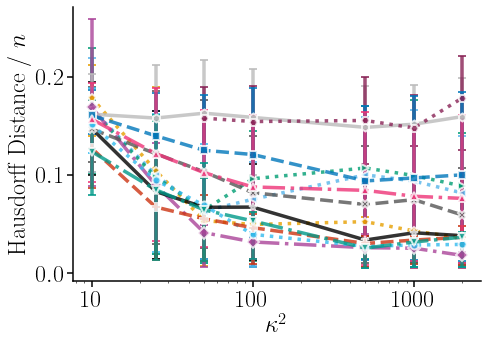

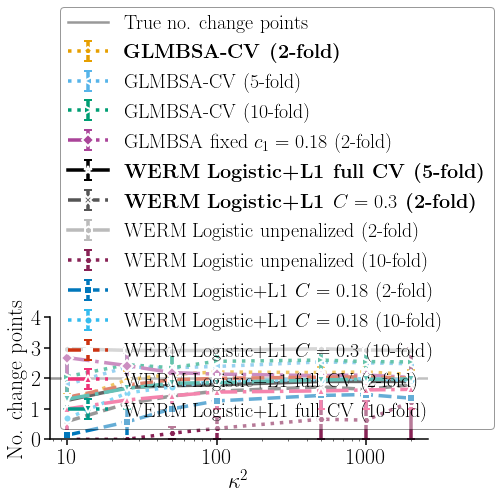

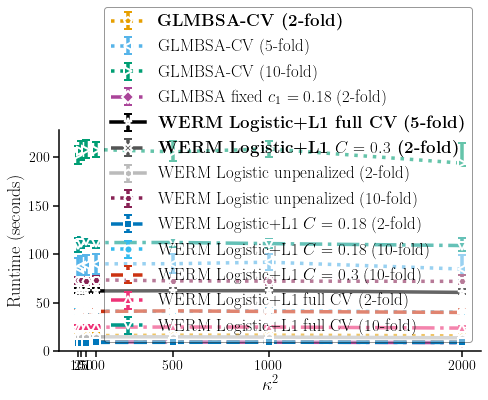


--- Plotting Distributions: boxplots + raw observations ---
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=10: n=84, unique=60, min=0.02, Q1=0.139583, median=0.180833, Q3=0.2125, max=0.32, IQR=0.0729167, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV-5fold; kappa^2=10: n=88, unique=72, min=0.015, Q1=0.102917, median=0.1775, Q3=0.21875, max=0.341667, IQR=0.115833, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV-10fold; kappa^2=10: n=91, unique=75, min=0.015, Q1=0.100833, median=0.168333, Q3=0.229167, max=0.346667, IQR=0.128333, collapsed=False
Hausdorff distance / n; method=GLMBSA-fixed0.18-2fold; kappa^2=10: n=100, unique=77, min=0.015, Q1=0.0883333, median=0.156667, Q3=0.258333, max=0.346667, IQR=0.17, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV; kappa^2=10: n=92, unique=59, min=0.00666667, Q1=0.100417, median=0.156667, Q3=0.195, max=0.665, IQR=0.0945833, collapsed=False
Hausdorff distance / n; method=WERM-L1-C0.3-2fold; kappa^2=10: n=50, uniqu

Hausdorff distance / n; method=GLMBSA-CV; kappa^2=50: n=99, unique=53, min=0, Q1=0.0075, median=0.0233333, Q3=0.0566667, max=0.34, IQR=0.0491667, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV-5fold; kappa^2=50: n=100, unique=58, min=0, Q1=0.01, median=0.0291667, Q3=0.1, max=0.31, IQR=0.09, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV-10fold; kappa^2=50: n=100, unique=58, min=0, Q1=0.01, median=0.0333333, Q3=0.0970833, max=0.313333, IQR=0.0870833, collapsed=False
Hausdorff distance / n; method=GLMBSA-fixed0.18-2fold; kappa^2=50: n=100, unique=48, min=0, Q1=0.00666667, median=0.0216667, Q3=0.04875, max=0.276667, IQR=0.0420833, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV; kappa^2=50: n=99, unique=59, min=0.00166667, Q1=0.015, median=0.0333333, Q3=0.123333, max=0.23, IQR=0.108333, collapsed=False
Hausdorff distance / n; method=WERM-L1-C0.3-2fold; kappa^2=50: n=95, unique=63, min=0.00166667, Q1=0.0258333, median=0.111667, Q3=0.176667, max=0.253333, I

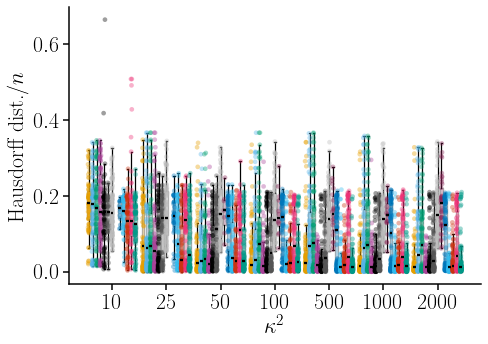

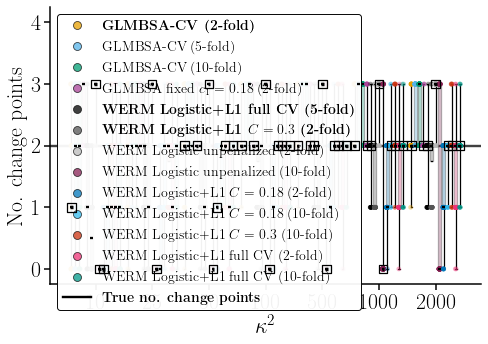

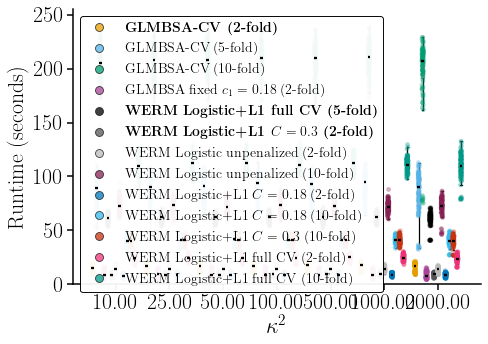


--- Plotting Changepoint Histograms ---


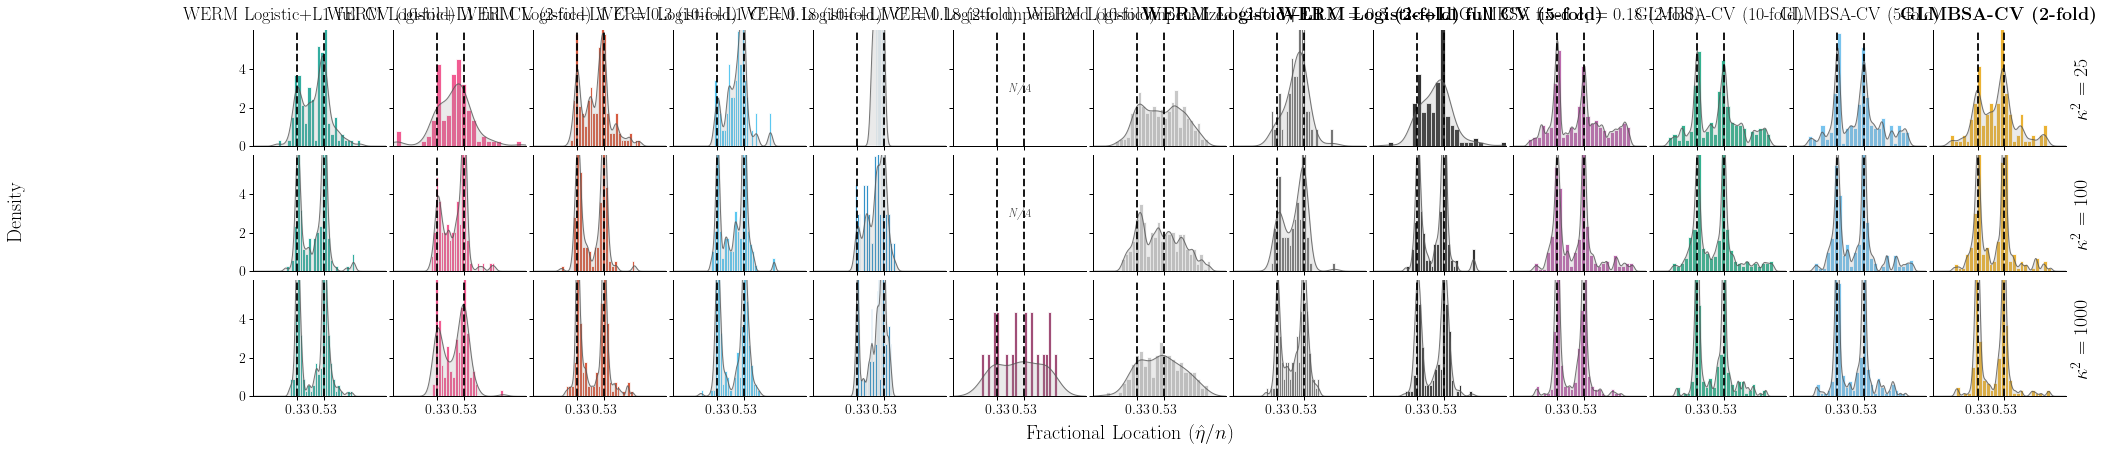

Publication-ready plotting completed in 13.37 seconds


In [4]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

methods_to_evaluate = [
    {'name': 'GLMBSA-CV', 'label': '\\textbf{GLMBSA-CV (2-fold)}', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-5fold', 'label': 'GLMBSA-CV (5-fold)', 'color': '#56B4E9', 'marker': '<', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-10fold', 'label': 'GLMBSA-CV (10-fold)', 'color': '#009E73', 'marker': '>', 'linestyle': ':'},
    {'name': 'GLMBSA-fixed0.18-2fold', 'label': 'GLMBSA fixed $c_1=0.18$ (2-fold)', 'color': '#AA4499', 'marker': 'D', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV', 'label': '\\textbf{WERM Logistic+L1 full CV (5-fold)}', 'color': 'black', 'marker': '*', 'linestyle': '-'},
    {'name': 'WERM-L1-C0.3-2fold', 'label': '\\textbf{WERM Logistic+L1 $C=0.3$ (2-fold)}', 'color': '#555555', 'marker': 'X', 'linestyle': '--'},
    {'name': 'WERM-unp-2fold', 'label': 'WERM Logistic unpenalized (2-fold)', 'color': '#BBBBBB', 'marker': 'h', 'linestyle': '-'},
    {'name': 'WERM-unp-10fold', 'label': 'WERM Logistic unpenalized (10-fold)', 'color': '#882255', 'marker': 'H', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.18-2fold', 'label': 'WERM Logistic+L1 $C=0.18$ (2-fold)', 'color': '#0077BB', 'marker': 's', 'linestyle': '--'},
    {'name': 'WERM-L1-C0.18-10fold', 'label': 'WERM Logistic+L1 $C=0.18$ (10-fold)', 'color': '#33BBEE', 'marker': 'o', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.3-10fold', 'label': 'WERM Logistic+L1 $C=0.3$ (10-fold)', 'color': '#CC3311', 'marker': 'P', 'linestyle': '--'},
    {'name': 'WERM-L1-fullCV-2fold', 'label': 'WERM Logistic+L1 full CV (2-fold)', 'color': '#EE3377', 'marker': '^', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV-10fold', 'label': 'WERM Logistic+L1 full CV (10-fold)', 'color': '#009988', 'marker': 'v', 'linestyle': '-.'},
]

method_colors_map = {method['name']: method['color'] for method in methods_to_evaluate}
PAL = [method['color'] for method in methods_to_evaluate]

# KDE / Histogram Context Style
kde_style = {
    'color': '#555555',       # Dark Grey line for definition
    'linestyle': '-',         # Solid line (distinct from competitor dashes)
    'linewidth': 1.0,         # Thinner than your methods (1.0 vs 1.5/2.5)
    'alpha': 0.8,             # Slight transparency for the line itself
    'fill_color': '#999999',  # Lighter grey for the area
    'fill_alpha': 0.2         # Very transparent fill
}

import sys
import numpy as np
import time
import matplotlib
import gc
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import pickle
import os


# Ensure the 'figures' directory exists
FIGURES_DIR = 'results/M3_upsample_redo2_plots/final_M3_upsample_format'
if not os.path.exists(FIGURES_DIR):
    os.makedirs(FIGURES_DIR)

# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except Exception:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

try:
    # A dummy logger function to prevent NameError if main_logger is not defined
    def dummy_logger_info(message):
        print(message)
    main_logger = type('Logger', (object,), {'info': staticmethod(dummy_logger_info)})()
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()

print("Plotting M3d delta=3, alpha=0.3")
print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data ---
# Load the completed eleven-method artifact; this cell never reruns the experiment.
filename_to_load = 'results/M3d_redo_delta3_alpha03_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42_100trials.pkl'
if os.environ.get('WERM_SMOKE') == '1':
    filename_to_load = filename_to_load.replace('_100trials.pkl', '_smoke.pkl')
try:
    with open(filename_to_load, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    kappa_list = params['kappa_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    fixed_delta = params['fixed_delta']
    signal_alpha = params.get('signal_alpha', 0.3)
    n_jobs = params['n_jobs']
    # methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', 42) # Get random_seed if available

    # Ensure colors are assigned from the palette in order for loaded methods
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]
    print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")
    # Change the method name from 'WERM-CV' to 'WERM'
    for method in methods_to_evaluate:
        if method['name'] == 'WERM-CV':
            method['label'] = r'\textbf{WERM}'

    method_names_list = [method['name'] for method in methods_to_evaluate]
    assert [method['name'] for method in params['methods_evaluated']] == method_names_list

except FileNotFoundError:
    print(f"Error: Results file '{filename_to_load}' not found. Please ensure your results are saved.")
    print("For demonstration, creating dummy data.")
    # Create dummy data for demonstration if file not found
    p = 200
    L = 4
    noise_std = 0.7745966692414834
    kappa_list = np.array([1, 2, 3, 4, 5]) # Example kappas
    fractional_chgpt_locations = np.array([0.2, 0.4, 0.6, 0.8])
    num_trials = 10
    n_jobs = 1
    methods_to_evaluate = [
        {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'marker': 'o', 'linestyle': '-'},
        {'name': 'WERM-CV', 'label': r'\textbf{WERM-CV}', 'marker': 's', 'linestyle': '--'},
    ]
    method_names_list = [method['name'] for method in methods_to_evaluate]

    # Assign colors from palette
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]

    results = {}
    for metric in ['haus', 'size', 'runtime', 'chgpts']:
        for method_config in methods_to_evaluate:
            method_name = method_config['name']
            key = f'{metric}_{method_name}'
            if metric == 'chgpts':
                results[key] = []
                for kappa_idx, kappa_val in enumerate(kappa_list):
                    n_for_kappa = int(kappa_val * p)
                    for _ in range(num_trials):
                        num_chgpts_detected = np.random.randint(L - 1, L + 2)
                        # Fix for histogram: Ensure dummy changepoints span 0-1 range
                        dummy_chgpts_fractional = np.random.rand(num_chgpts_detected)
                        # Scale to actual indices (0 to n_for_kappa) for storage
                        results[key].append((kappa_idx, dummy_chgpts_fractional * n_for_kappa))
            else:
                results[key] = np.random.rand(len(kappa_list), num_trials)
                if metric == 'size':
                    results[key] = np.round(results[key] * (L + 2)).astype(int)
                elif metric == 'runtime':
                    results[key] = results[key] * 10
                elif metric == 'haus':
                    results[key] = results[key] * 0.2 + 0.05
    random_seed = 42 # Set dummy seed

for method_name in method_names_list:
    _size = np.asarray(results[f'size_{method_name}'], dtype=float)
    _haus = np.asarray(results[f'haus_{method_name}'], dtype=float)
    results[f'haus_{method_name}'] = np.where(_size > 0, _haus, np.nan)

print("Data loaded for plotting; empty-estimate Hausdorff values are NaN.")

# Filter kappa_list for plotting from kappa = 1.5 and onwards
kappa_list = np.array(kappa_list) # Ensure it's a numpy array for easy filtering
kappa_start_index = np.where(kappa_list >= 1.5)[0]
if len(kappa_start_index) > 0:
    kappa_start_index = kappa_start_index[0]
else: # If no kappa >= 1.5, use the whole list or handle as an error
    kappa_start_index = 0
    print("Warning: No kappa values >= 1.5 found. Using all available kappa values for filtering.")

kappa_list_filtered = kappa_list[kappa_start_index:]

# Replace kappa list with kappa^2 values for plotting
kappa_list_filtered = np.power(kappa_list_filtered, 2)
kappa_list = np.power(kappa_list, 2)

# Filter results based on the new kappa_list for line plots and all box plots
results_filtered = {}
for key, value in results.items():
    if key.startswith(('haus_', 'size_', 'runtime_')):
        if value.shape[0] > kappa_start_index:
            results_filtered[key] = value[kappa_start_index:, :]
        else:
            results_filtered[key] = np.empty((0, value.shape[1]))

print(f"DEBUG: Original kappa_list: {kappa_list}")
print(f"DEBUG: Filtered kappa_list (>= 1.5): {kappa_list_filtered}")
print(f"DEBUG: Method names available: {method_names_list}")
print(f"DEBUG: First few haus results (filtered): {results_filtered.get('haus_GLMBSA-CV', 'Not available')[:2]}") # Changed to GLMBSA for consistency with example filename

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Asymmetric Error Bars Plotting Functions (Separated) ---

x_y_label_fontsize = 22

def plot_location_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Location Error}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'haus_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Hausdorff) for current kappa_list. Skipping plot for this metric.")
            continue
        data = np.where(np.isinf(data), np.nan, data)
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
    ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=24)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=24)
    ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.get_xaxis().set_minor_formatter(matplotlib.ticker.NullFormatter())
    # Set the tick font size larger for better readability
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=24)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=24)
    # ax.legend(loc='upper right', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pgf"))
    plt.show()

    # Replot the above, with in log-scale on the x axis
    # fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # # ax.set_title(r'\textbf{Changepoint Location Error (Log Scale)}', fontsize=18, pad=15) # Title removed 
    # for i, method_obj in enumerate(methods_to_evaluate):
    #     method_name = method_obj['name']
    #     data = current_results.get(f'haus_{method_name}')
    #     if data is None or data.size == 0 or np.all(np.isnan(data)):
    #         continue
    #     data = np.where(np.isinf(data), np.nan, data)
    #     means = np.nanmean(data, axis=1)
    #     errors = get_asymmetric_errors(data)
    #     ax.errorbar(current_kappa_list, means, yerr=errors,
    #                 label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
    #                 color=plot_colors[i], capsize=4, capthick=2, markersize=8,
    #                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    # ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    # ax.set_xlabel(r'$\kappa$ (log scale)', fontsize=18)
    # ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    # ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.tick_params(axis='both', which='major', width=1.5, length=6)
    # ax.spines['top'].set_visible(False)
    # ax.spines['right'].set_visible(False)
    # ax.spines['left'].set_linewidth(1.5)
    # ax.spines['bottom'].set_linewidth(1.5)
    # ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    # plt.tight_layout()
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pdf"))
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pgf"))
    # plt.show()

def plot_size_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Set Size}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'size_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Size) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_xscale('log')
    ax.axhline(y=len(fractional_chgpt_locations), color='gray', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'True no. change points')
    ax.set_ylim((0, L))
    ax.set_yticks(np.arange(0, L + 1, step=1).astype(int))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=x_y_label_fontsize)
    ax.set_ylabel(r'No. change points', fontsize=x_y_label_fontsize)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=x_y_label_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 20}, fancybox = True, framealpha = 0.4)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=x_y_label_fontsize)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pgf"))
    plt.show()

def plot_runtime_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Method Runtime}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'runtime_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Runtime) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\kappa^2$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pgf"))
    plt.show()

# --- Distribution Plotting Functions -----------------------------------------
#
# Three display modes are supported:
#   1. "box_jitter"      : standard boxplot + all observations (recommended)
#   2. "interval_jitter" : 5--95%, IQR, median + all observations
#   3. "violin_jitter"   : violin + IQR/median + all observations
#
# A box with Q1 == Q3 is statistically supposed to collapse.  We therefore do
# not artificially change its quartiles.  Instead, collapsed IQRs are reinforced
# with a thick horizontal line and, optionally, a hollow-square glyph.

from matplotlib.lines import Line2D


_DISTRIBUTION_STYLES = {"box_jitter", "interval_jitter", "violin_jitter"}
_COLLAPSED_STYLES = {"line", "line_and_marker", "none"}


def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }


def _warn(message):
    """Use the project logger when it supports warnings; otherwise print."""
    logger = globals().get("main_logger")
    warning_method = getattr(logger, "warning", None)
    if callable(warning_method):
        warning_method(message)
    else:
        print(f"WARNING: {message}")


def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)


def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.38,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )


def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )


def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_summary(
    ax,
    position,
    color,
    summary,
    box_width,
    collapsed_style,
):
    """Draw 5--95%, IQR, and median summaries."""
    cap_half_width = 0.14 * box_width

    # Thin 5--95% interval and end caps.
    ax.vlines(
        position,
        summary["q05"],
        summary["q95"],
        color="black",
        linewidth=1.35,
        zorder=5,
    )
    ax.hlines(
        [summary["q05"], summary["q95"]],
        position - cap_half_width,
        position + cap_half_width,
        color="black",
        linewidth=1.35,
        zorder=5,
    )

    # Thick IQR interval. It correctly becomes a point/line when IQR=0.
    ax.vlines(
        position,
        summary["q25"],
        summary["q75"],
        color=color,
        linewidth=8.0,
        alpha=0.58,
        zorder=5,
    )

    # Median remains visible even when every interval collapses.
    ax.scatter(
        [position],
        [summary["median"]],
        marker="D",
        s=46,
        facecolor=color,
        edgecolor="black",
        linewidth=0.9,
        zorder=7,
        label="_nolegend_",
    )

    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw raw observations together with quantile intervals and the median."""
    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _draw_violin_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """
    Draw a violin/raincloud-style display plus points and quantile summaries.

    The violin is omitted when there are fewer than two distinct observations,
    because a kernel density is then undefined/uninformative.
    """
    if values.size >= 2 and summary["n_unique"] >= 2:
        parts = ax.violinplot(
            [values],
            positions=[position],
            widths=1.15 * box_width,
            showmeans=False,
            showmedians=False,
            showextrema=False,
            points=100,
            bw_method="scott",
        )
        body = parts["bodies"][0]
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_linewidth(1.0)
        body.set_alpha(0.20)
        body.set_zorder(1)

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _format_distribution_diagnostic(metric_label, method_name, kappa, summary):
    return (
        f"{metric_label}; method={method_name}; kappa^2={kappa:g}: "
        f"n={summary['n']}, unique={summary['n_unique']}, "
        f"min={summary['min']:.6g}, Q1={summary['q25']:.6g}, "
        f"median={summary['median']:.6g}, Q3={summary['q75']:.6g}, "
        f"max={summary['max']:.6g}, IQR={summary['iqr']:.6g}, "
        f"collapsed={summary['collapsed']}"
    )


def _plot_grouped_distributions(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    metric_prefix,
    metric_label,
    y_label,
    filename_base,
    filename_metric,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    random_seed=2026,
    box_width=0.72,
    jitter_width=0.20,
    point_size=22,
    point_alpha=0.38,
    diagnostics=False,
    show_legend=True,
    legend_loc="upper left",
    y_limits=None,
    y_ticks=None,
    reference_y=None,
    reference_label=None,
    x_label=r'$\kappa^2$',
    tick_label_format=".0f",
):
    """Shared implementation for location, size, and runtime distributions."""
    if plot_style not in _DISTRIBUTION_STYLES:
        raise ValueError(
            f"plot_style must be one of {sorted(_DISTRIBUTION_STYLES)}, "
            f"got {plot_style!r}."
        )
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )

    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    rng = np.random.default_rng(random_seed)

    plot_labels = [method["label"] for method in methods_to_evaluate]
    plot_colors = [method["color"] for method in methods_to_evaluate]
    methods = [method["name"] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    diagnostic_records = []

    for kappa_idx, kappa in enumerate(current_kappa_list):
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f"{metric_prefix}_{method_name}")
            if data is None or data.ndim < 2 or data.shape[0] <= kappa_idx:
                _warn(
                    f"No {metric_label} data for {method_name} at "
                    f"kappa^2={kappa:g}; skipping this group."
                )
                continue

            values = _finite_1d(data[kappa_idx, :])
            if values.size == 0:
                _warn(
                    f"No finite {metric_label} observations for {method_name} "
                    f"at kappa^2={kappa:g}; skipping this group."
                )
                continue

            summary = _distribution_summary(values)
            position = kappa_idx * spacing + method_idx
            color = plot_colors[method_idx]

            record = {
                "metric": metric_label,
                "method": method_name,
                "kappa_squared": float(kappa),
                **summary,
            }
            diagnostic_records.append(record)
            if diagnostics:
                print(
                    _format_distribution_diagnostic(
                        metric_label, method_name, kappa, summary
                    )
                )

            draw_kwargs = dict(
                ax=ax,
                values=values,
                position=position,
                color=color,
                rng=rng,
                summary=summary,
                box_width=box_width,
                jitter_width=jitter_width,
                point_size=point_size,
                point_alpha=point_alpha,
                collapsed_style=collapsed_style,
            )

            if plot_style == "box_jitter":
                _draw_box_jitter_group(**draw_kwargs)
            elif plot_style == "interval_jitter":
                _draw_interval_jitter_group(**draw_kwargs)
            else:
                _draw_violin_jitter_group(**draw_kwargs)

    # Optional horizontal truth/reference line.
    if reference_y is not None:
        ax.axhline(
            y=reference_y,
            color="black",
            linestyle="-",
            linewidth=2.4,
            alpha=0.75,
            zorder=0,
            label="_nolegend_",
        )

    kappa_positions = [
        i * spacing + (len(methods) - 1) / 2
        for i in range(len(current_kappa_list))
    ]
    ax.set_xticks(kappa_positions)
    ax.set_xticklabels(
        [format(float(k), tick_label_format) for k in current_kappa_list]
    )
    ax.set_xlabel(x_label, fontsize=x_y_label_fontsize)
    ax.set_ylabel(y_label, fontsize=x_y_label_fontsize)

    if y_limits is not None:
        ax.set_ylim(*y_limits)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)

    if show_legend:
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markersize=8,
                markerfacecolor=plot_colors[i],
                markeredgecolor="black",
                markeredgewidth=0.8,
                alpha=0.75,
                label=plot_labels[i],
            )
            for i in range(len(methods))
        ]
        if reference_y is not None and reference_label is not None:
            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    color="black",
                    linewidth=2.4,
                    label=reference_label,
                )
            )
        ax.legend(
            handles=legend_elements,
            loc=legend_loc,
            fontsize=14,
            frameon=True,
            edgecolor="black",
            framealpha=0.95,
        )

    ax.tick_params(
        axis="both",
        which="major",
        width=1.5,
        length=6,
        labelsize=x_y_label_fontsize,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    # Keep the historical filenames for the recommended box+jitter mode.
    style_suffix = {
        "box_jitter": "boxplots",
        "interval_jitter": "interval_jitter",
        "violin_jitter": "violin_jitter",
    }[plot_style]
    output_stem = f"{filename_base}_{filename_metric}_{style_suffix}"

    fig.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pdf"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.png"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pgf"))
    plt.show()

    return fig, ax, diagnostic_records


def plot_location_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot the Hausdorff-error distributions.

    Recommended publication mode: plot_style="box_jitter".
    Clean alternative:             plot_style="interval_jitter".
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="haus",
        metric_label="Hausdorff distance / n",
        y_label=r'Hausdorff dist./$n$',
        filename_base=filename_base,
        filename_metric="location",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=False,
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_size_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot estimated changepoint counts.

    Because this response is discrete, box+jitter or interval+jitter is preferable
    to a violin plot, whose kernel smoothing can imply nonexistent values.
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="size",
        metric_label="Number of change points",
        y_label=r'No. change points',
        filename_base=filename_base,
        filename_metric="size",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(-0.25, L + 0.25),
        y_ticks=np.arange(0, L + 1, dtype=int),
        reference_y=len(fractional_chgpt_locations),
        reference_label=r'\textbf{True no. change points}',
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_runtime_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """Plot runtime distributions using any supported display mode."""
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="runtime",
        metric_label="Runtime (seconds)",
        y_label=r'Runtime (seconds)',
        filename_base=filename_base,
        filename_metric="runtime",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(0, None),
        tick_label_format=".2f",
        x_label=r'$\kappa^2$',
    )

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms (Optimized Layout)
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(original_results, original_kappa_list, fractional_chgpt_locations, methods_to_plot_names_, p):
    """
    Publication-ready changepoint location histograms with tight layout (Kappa variant)
    """

    # 1. Setup Data
    # Use existing method_plotting_info/methods_to_evaluate if available, else fallback
    try:
        method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
        method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    except:
        import seaborn as sns
        pal = sns.color_palette("colorblind", len(methods_to_plot_names_))
        method_names_map = {name: name.upper() for name in methods_to_plot_names_}
        method_colors_map = {name: pal[i] for i, name in enumerate(methods_to_plot_names_)}

    current_methods = methods_to_plot_names_.copy()
    # current_method_names = [method['name'] for method in current_methods] # Adaptation: input is already names list
    
    # Reverse order as per original request
    # method_names_map = {k: method_names_map[k] for k in reversed(method_names_map)} # Key error risk if iterating dict
    current_methods.reverse()
    current_method_names = current_methods

    # Kappa Selection Logic (Adapted from Template's Delta Logic)
    selected_kappas_idx = [i for i, k in enumerate(original_kappa_list) if k >= 1.5]
    selected_kappas = [original_kappa_list[i] for i in selected_kappas_idx]
    
    num_rows = len(selected_kappas)
    num_cols = len(current_methods)

    # 2. Setup Figure - TIGHTER DIMENSIONS
    # Using a roughly 3:2.5 ratio per subplot, scaled for standard latex textwidth
    # A width of 14-16 inches usually scales down perfectly to a 7 inch page width
    fig, axes = plt.subplots(num_rows, num_cols,
                             figsize=(2.5 * num_cols, 2.2 * num_rows), 
                             sharex=True, sharey=True,
                             gridspec_kw={'wspace': 0.05, 'hspace': 0.08}) # <--- KEY FOR TIGHTNESS
    
    # Handle single subplot cases to ensure axes is always 2D array
    if num_rows == 1 and num_cols == 1:
        axes = np.array([[axes]])
    elif num_cols == 1:
        axes = axes.reshape(-1, 1)
    elif num_rows == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')

    # 3. Plotting Loop
    for row, (kappa_idx, kappa) in enumerate(zip(selected_kappas_idx, selected_kappas)):
        # Calculate n based on fixed_delta (assuming global) or fallback
        try:
            n = int(fixed_delta * p)
        except:
            n = 100
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # --- Data Collection (Adapted for Kappa structure) ---
            all_chgpts = []
            chgpts_data_for_method = original_results.get(f'chgpts_{method_name}', [])
            
            for stored_kappa_idx, chgpts_list in chgpts_data_for_method:
                if stored_kappa_idx == kappa_idx:
                     # Robust handling for list-of-lists vs arrays
                    if isinstance(chgpts_list, list):
                        for chgpts_arr in chgpts_list:
                            if chgpts_arr is not None and len(chgpts_arr) > 0:
                                arr = np.array(chgpts_arr)
                                if not (np.isscalar(arr) and np.isnan(arr)):
                                    valid = arr[arr != -1]
                                    for x in valid: all_chgpts.append(x / n)
                    elif chgpts_list is not None:
                        arr = np.array(chgpts_list)
                        if arr.size > 0 and not (np.isscalar(arr) and np.isnan(arr)):
                            valid = arr[arr != -1]
                            for x in valid: all_chgpts.append(x / n)
            
            # --- Plotting ---
            if len(all_chgpts) > 0:
                # Histogram
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                color=method_colors_map.get(method_name, 'blue'),
                                                density=True, edgecolor='white',
                                                linewidth=1.0) # Thinner line for tighter look
                
                # KDE (GridSearch Logic)
                if len(all_chgpts) > 6:
                    try:
                        # Use grid search to find optimal bandwidth
                        params = {'bandwidth': np.logspace(-2, 0, 50)}
                        grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)
                        grid.fit(np.array(all_chgpts).reshape(-1, 1))
                        
                        x_range = np.linspace(0, 1, 200)
                        # Score_samples returns log-density, so we exponentiate
                        log_dens = grid.best_estimator_.score_samples(x_range.reshape(-1, 1))
                        kde_values = np.exp(log_dens)
                        
                        # --- UPDATED PLOTTING LOGIC ---
                        # 1. Plot the line (Dark Grey)
                        ax.plot(x_range, kde_values, 
                                color=kde_style['color'], 
                                linewidth=kde_style['linewidth'],
                                linestyle=kde_style['linestyle'], # Solid line for context
                                alpha=kde_style['alpha'], 
                                label='KDE', # No bolding, keep it contextual
                                zorder=2) # Low z-order to sit BEHIND methods
                        
                        # 2. Add the fill (Subtle Grey)
                        # This makes the "shape" of the data distribution easier to see
                        ax.fill_between(x_range, kde_values, 
                                        color=kde_style['fill_color'], 
                                        alpha=kde_style['fill_alpha'],
                                        zorder=1)
                    except:
                        pass
            else:
                ax.text(0.5, 0.5, r'\textit{N/A}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=12, alpha=0.7, style='italic')
            
            # True Changepoints
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', 
                           linewidth=2, alpha=0.9, zorder=10,
                           label=r'\textbf{True changepoints}' if i == 0 else "")

            # --- Formatting & Ticks ---
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 6) # Enforce uniform height
            
            # Clean spines
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.0)
            ax.spines['bottom'].set_linewidth(1.0)
            
            # Custom ticks - apply to ALL, but sharex hides labels automatically
            ax.set_xticks(np.array([*fractional_chgpt_locations]))
            # ax.set_xticklabels([*[f'${tc:.2f}$' for tc in fractional_chgpt_locations]], fontsize=12)
            ax.set_xticklabels(['$0.33$', '$0.53$'], fontsize=10)
            ax.set_yticks([0, 2, 4]) # Minimal Y-ticks
            
            # Tick parameters
            # 'labelleft' and 'labelbottom' control visibility explicitly if sharex/y fails
            ax.tick_params(axis='both', which='major', width=1, length=4, labelsize=14)

            # 4. Labels and Titles (Specific Locations Only)
            
            # Column Titles (Method Names) - Only Top Row
            if row == 0:
                ax.set_title(f'{method_names_map.get(method_name, method_name)}', fontsize=18, pad=10)
            
            # Row Labels (Kappa) - Right side of Last Column
            if col == num_cols - 1:
                # Use ax.text roughly in the middle right
                ax.text(1.05, 0.5, rf'$\kappa$\textsuperscript{{2}} $= {kappa:.0f}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', horizontalalignment='left',
                        fontsize=20, fontweight='bold')

            # X-Axis Label - Bottom Row, Centered on Figure not Subplot
            # We skip per-subplot labels to save space
    
    # Global Labels (cleaner than per-subplot)
    fig.text(0.5, 0.01, r'Fractional Location ($\hat{\mathbf{\eta}}/n$)', 
             ha='center', va='bottom', fontsize=20)
    fig.text(0.02, 0.5, r'Density', 
             va='center', rotation='vertical', fontsize=20)

    # 5. Legend
    # Place one legend for the whole figure, or inside the first visible plot
    # Here we put it in the first plot, but make it compact
    first_ax = axes[0, 0]
    handles, labels = first_ax.get_legend_handles_labels()
    # if handles:
    #     # Create a legend that floats slightly inside the plot
    #     legend = first_ax.legend(loc='upper right', fontsize=18, frameon=True,
    #                              edgecolor='white', framealpha=0.8, handlelength=1.5)
    #     legend.set_zorder(20)

    # Final Tight Layout to handle the global labels
    # rect tuple is (left, bottom, right, top)
    plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96]) 
    
    return fig, axes

# Get a base filename for saving figures based on the loaded data's properties
# This uses the original filename from which data was loaded to create a consistent naming convention
filename_base_for_plots = 'final_M3_upsample_format_' + os.path.basename(filename_to_load).replace('.pkl', '')
print(f"Base filename for saving plots: {filename_base_for_plots}")

# --- Execute plotting functions ---
print("\n--- Plotting Asymmetric Error Bars ---")
plot_location_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_size_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_runtime_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots)

print("\n--- Plotting Distributions: boxplots + raw observations ---")

# Recommended figure: retain the familiar boxplot, but show every repetition.
# Set this to False after you have diagnosed the collapsed groups once.
PRINT_DISTRIBUTION_DIAGNOSTICS = True

plot_location_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=PRINT_DISTRIBUTION_DIAGNOSTICS,
)
plot_size_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)
plot_runtime_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)

# Optional alternative outputs. These use distinct filenames, so they do not
# overwrite the recommended box+jitter figures.
PLOT_ALTERNATIVE_DISTRIBUTIONS = False
if PLOT_ALTERNATIVE_DISTRIBUTIONS:
    print("\n--- Plotting Distributions: quantile intervals + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_size_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        L,
        fractional_chgpt_locations,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )

    # Violin plots are optional for continuous metrics. They are deliberately
    # not generated for the integer-valued changepoint-count metric.
    print("\n--- Plotting Distributions: violin + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )

print("\n--- Plotting Changepoint Histograms ---")
fig_hist, axes_hist = plot_changepoint_histograms_publication(results, kappa_list[::2], fractional_chgpt_locations, method_names_list, p=p)
_histogram_stem = os.path.join(FIGURES_DIR, f'{filename_base_for_plots}_changepoint_histograms')
fig_hist.savefig(f'{_histogram_stem}.pdf', dpi=300, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.png', dpi=200, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.pgf', dpi=300, bbox_inches='tight')
plt.show()


plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

### Two-method comparison: 2-fold full CV only

Removing 110 matplotlib modules...


Successfully set backend to: module://matplotlib_inline.backend_inline
Creating publication-ready plots...
Plotting M3d delta=3, alpha=0.3
Using palette: ['#E69F00', '#EE3377'] (Paul Tol Vibrant)
Using palette: ['#E69F00', '#EE3377'] (Paul Tol Vibrant assigned to methods)
Data loaded for plotting; empty-estimate Hausdorff values are NaN.
DEBUG: Original kappa_list: [1.0e+00 1.0e+01 2.5e+01 5.0e+01 1.0e+02 5.0e+02 1.0e+03 2.0e+03]
DEBUG: Filtered kappa_list (>= 1.5): [  10.   25.   50.  100.  500. 1000. 2000.]
DEBUG: Method names available: ['GLMBSA-CV', 'WERM-L1-fullCV-2fold']
DEBUG: First few haus results (filtered): [[0.18       0.12166667 0.10666667 0.195      0.02833333        nan
  0.20333333 0.19       0.19666667 0.225             nan 0.205
  0.19666667        nan 0.29833333 0.14666667 0.22666667 0.17166667
  0.15       0.20166667 0.19666667 0.24833333 0.21666667 0.10333333
  0.13833333        nan 0.15833333 0.28333333        nan 0.02833333
  0.17833333 0.23166667 0.19333333 0.19

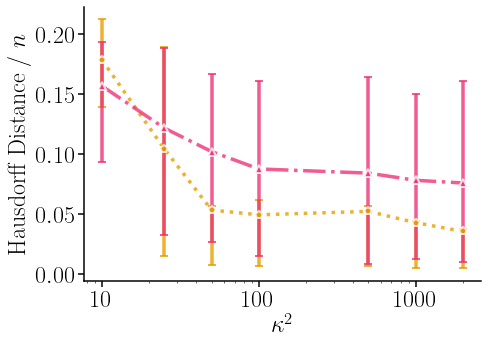

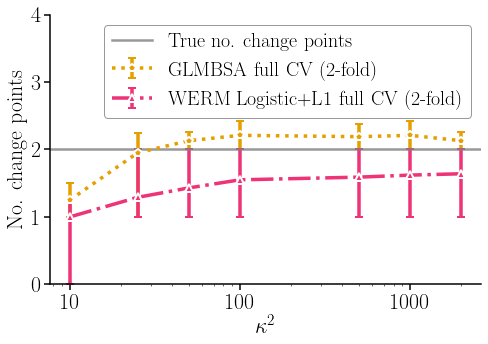

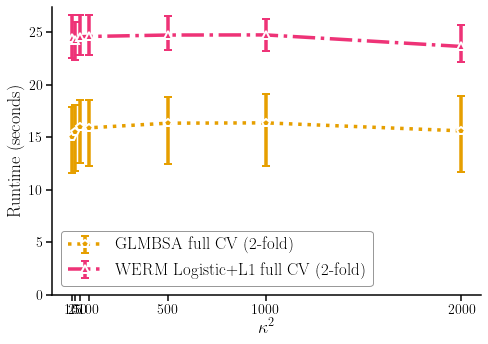


--- Plotting Distributions: boxplots + raw observations ---
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=10: n=84, unique=60, min=0.02, Q1=0.139583, median=0.180833, Q3=0.2125, max=0.32, IQR=0.0729167, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV-2fold; kappa^2=10: n=63, unique=54, min=0.00666667, Q1=0.0933333, median=0.135, Q3=0.193333, max=0.508333, IQR=0.1, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=25: n=98, unique=66, min=0, Q1=0.015, median=0.0675, Q3=0.189167, max=0.348333, IQR=0.174167, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV-2fold; kappa^2=25: n=91, unique=62, min=0.00166667, Q1=0.0325, median=0.136667, Q3=0.188333, max=0.253333, IQR=0.155833, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=50: n=99, unique=53, min=0, Q1=0.0075, median=0.0233333, Q3=0.0566667, max=0.34, IQR=0.0491667, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV-2fold; kappa^2=50: n=93, unique=63, min=0.00166

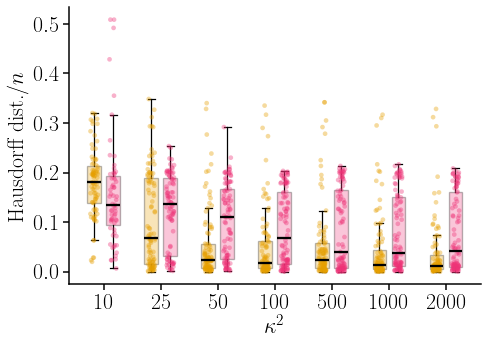

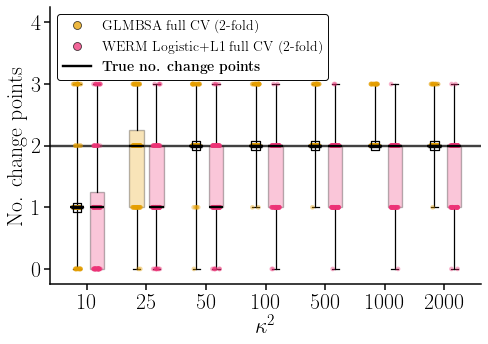

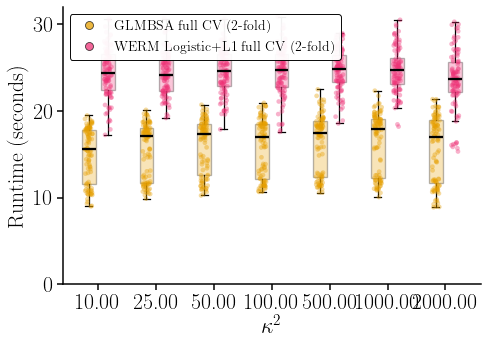


--- Plotting Changepoint Histograms ---


/tmp/ipykernel_245321/3138380877.py:1272: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96])


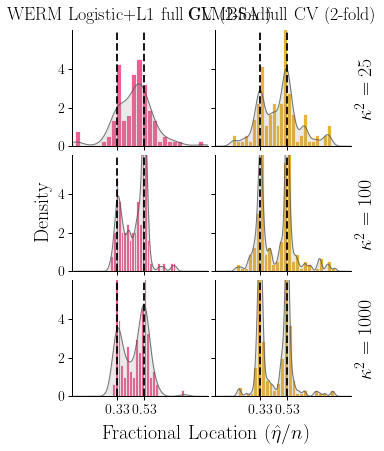

Publication-ready plotting completed in 4.11 seconds


In [2]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

methods_to_evaluate = [
    {'name': 'GLMBSA-CV', 'label': r'GLMBSA full CV (2-fold)', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'},
    {'name': 'WERM-L1-fullCV-2fold', 'label': r'WERM Logistic+L1 full CV (2-fold)', 'color': '#EE3377', 'marker': '^', 'linestyle': '-.'},
]

method_colors_map = {method['name']: method['color'] for method in methods_to_evaluate}
PAL = [method['color'] for method in methods_to_evaluate]

# KDE / Histogram Context Style
kde_style = {
    'color': '#555555',       # Dark Grey line for definition
    'linestyle': '-',         # Solid line (distinct from competitor dashes)
    'linewidth': 1.0,         # Thinner than your methods (1.0 vs 1.5/2.5)
    'alpha': 0.8,             # Slight transparency for the line itself
    'fill_color': '#999999',  # Lighter grey for the area
    'fill_alpha': 0.2         # Very transparent fill
}

import sys
import numpy as np
import time
import matplotlib
import gc
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import pickle
import os


# Ensure the 'figures' directory exists
FIGURES_DIR = 'results/M3_upsample_redo2_plots/final_M3_upsample_format'
if not os.path.exists(FIGURES_DIR):
    os.makedirs(FIGURES_DIR)

# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except Exception:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

try:
    # A dummy logger function to prevent NameError if main_logger is not defined
    def dummy_logger_info(message):
        print(message)
    main_logger = type('Logger', (object,), {'info': staticmethod(dummy_logger_info)})()
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()

print("Plotting M3d delta=3, alpha=0.3")
print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data ---
# Load the completed eleven-method artifact; this cell never reruns the experiment.
filename_to_load = 'results/M3d_redo_delta3_alpha03_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42_100trials.pkl'
if os.environ.get('WERM_SMOKE') == '1':
    filename_to_load = filename_to_load.replace('_100trials.pkl', '_smoke.pkl')
try:
    with open(filename_to_load, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    kappa_list = params['kappa_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    fixed_delta = params['fixed_delta']
    signal_alpha = params.get('signal_alpha', 0.3)
    n_jobs = params['n_jobs']
    # methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', 42) # Get random_seed if available

    # Ensure colors are assigned from the palette in order for loaded methods
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]
    print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")
    # Change the method name from 'WERM-CV' to 'WERM'
    for method in methods_to_evaluate:
        if method['name'] == 'WERM-CV':
            method['label'] = r'\textbf{WERM}'

    method_names_list = [method['name'] for method in methods_to_evaluate]
    available_method_names = {method['name'] for method in params['methods_evaluated']}
    assert set(method_names_list).issubset(available_method_names)

except FileNotFoundError:
    print(f"Error: Results file '{filename_to_load}' not found. Please ensure your results are saved.")
    print("For demonstration, creating dummy data.")
    # Create dummy data for demonstration if file not found
    p = 200
    L = 4
    noise_std = 0.7745966692414834
    kappa_list = np.array([1, 2, 3, 4, 5]) # Example kappas
    fractional_chgpt_locations = np.array([0.2, 0.4, 0.6, 0.8])
    num_trials = 10
    n_jobs = 1
    methods_to_evaluate = [
        {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'marker': 'o', 'linestyle': '-'},
        {'name': 'WERM-CV', 'label': r'\textbf{WERM-CV}', 'marker': 's', 'linestyle': '--'},
    ]
    method_names_list = [method['name'] for method in methods_to_evaluate]

    # Assign colors from palette
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]

    results = {}
    for metric in ['haus', 'size', 'runtime', 'chgpts']:
        for method_config in methods_to_evaluate:
            method_name = method_config['name']
            key = f'{metric}_{method_name}'
            if metric == 'chgpts':
                results[key] = []
                for kappa_idx, kappa_val in enumerate(kappa_list):
                    n_for_kappa = int(kappa_val * p)
                    for _ in range(num_trials):
                        num_chgpts_detected = np.random.randint(L - 1, L + 2)
                        # Fix for histogram: Ensure dummy changepoints span 0-1 range
                        dummy_chgpts_fractional = np.random.rand(num_chgpts_detected)
                        # Scale to actual indices (0 to n_for_kappa) for storage
                        results[key].append((kappa_idx, dummy_chgpts_fractional * n_for_kappa))
            else:
                results[key] = np.random.rand(len(kappa_list), num_trials)
                if metric == 'size':
                    results[key] = np.round(results[key] * (L + 2)).astype(int)
                elif metric == 'runtime':
                    results[key] = results[key] * 10
                elif metric == 'haus':
                    results[key] = results[key] * 0.2 + 0.05
    random_seed = 42 # Set dummy seed

for method_name in method_names_list:
    _size = np.asarray(results[f'size_{method_name}'], dtype=float)
    _haus = np.asarray(results[f'haus_{method_name}'], dtype=float)
    results[f'haus_{method_name}'] = np.where(_size > 0, _haus, np.nan)

print("Data loaded for plotting; empty-estimate Hausdorff values are NaN.")

# Filter kappa_list for plotting from kappa = 1.5 and onwards
kappa_list = np.array(kappa_list) # Ensure it's a numpy array for easy filtering
kappa_start_index = np.where(kappa_list >= 1.5)[0]
if len(kappa_start_index) > 0:
    kappa_start_index = kappa_start_index[0]
else: # If no kappa >= 1.5, use the whole list or handle as an error
    kappa_start_index = 0
    print("Warning: No kappa values >= 1.5 found. Using all available kappa values for filtering.")

kappa_list_filtered = kappa_list[kappa_start_index:]

# Replace kappa list with kappa^2 values for plotting
kappa_list_filtered = np.power(kappa_list_filtered, 2)
kappa_list = np.power(kappa_list, 2)

# Filter results based on the new kappa_list for line plots and all box plots
results_filtered = {}
for key, value in results.items():
    if key.startswith(('haus_', 'size_', 'runtime_')):
        if value.shape[0] > kappa_start_index:
            results_filtered[key] = value[kappa_start_index:, :]
        else:
            results_filtered[key] = np.empty((0, value.shape[1]))

print(f"DEBUG: Original kappa_list: {kappa_list}")
print(f"DEBUG: Filtered kappa_list (>= 1.5): {kappa_list_filtered}")
print(f"DEBUG: Method names available: {method_names_list}")
print(f"DEBUG: First few haus results (filtered): {results_filtered.get('haus_GLMBSA-CV', 'Not available')[:2]}") # Changed to GLMBSA for consistency with example filename

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Asymmetric Error Bars Plotting Functions (Separated) ---

x_y_label_fontsize = 22

def plot_location_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Location Error}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'haus_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Hausdorff) for current kappa_list. Skipping plot for this metric.")
            continue
        data = np.where(np.isinf(data), np.nan, data)
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
    ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=24)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=24)
    ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.get_xaxis().set_minor_formatter(matplotlib.ticker.NullFormatter())
    # Set the tick font size larger for better readability
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=24)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=24)
    # ax.legend(loc='upper right', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pgf"))
    plt.show()

    # Replot the above, with in log-scale on the x axis
    # fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # # ax.set_title(r'\textbf{Changepoint Location Error (Log Scale)}', fontsize=18, pad=15) # Title removed 
    # for i, method_obj in enumerate(methods_to_evaluate):
    #     method_name = method_obj['name']
    #     data = current_results.get(f'haus_{method_name}')
    #     if data is None or data.size == 0 or np.all(np.isnan(data)):
    #         continue
    #     data = np.where(np.isinf(data), np.nan, data)
    #     means = np.nanmean(data, axis=1)
    #     errors = get_asymmetric_errors(data)
    #     ax.errorbar(current_kappa_list, means, yerr=errors,
    #                 label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
    #                 color=plot_colors[i], capsize=4, capthick=2, markersize=8,
    #                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    # ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    # ax.set_xlabel(r'$\kappa$ (log scale)', fontsize=18)
    # ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    # ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.tick_params(axis='both', which='major', width=1.5, length=6)
    # ax.spines['top'].set_visible(False)
    # ax.spines['right'].set_visible(False)
    # ax.spines['left'].set_linewidth(1.5)
    # ax.spines['bottom'].set_linewidth(1.5)
    # ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    # plt.tight_layout()
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pdf"))
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pgf"))
    # plt.show()

def plot_size_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Set Size}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'size_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Size) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_xscale('log')
    ax.axhline(y=len(fractional_chgpt_locations), color='gray', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'True no. change points')
    ax.set_ylim((0, L))
    ax.set_yticks(np.arange(0, L + 1, step=1).astype(int))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=x_y_label_fontsize)
    ax.set_ylabel(r'No. change points', fontsize=x_y_label_fontsize)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=x_y_label_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 20}, fancybox = True, framealpha = 0.4)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=x_y_label_fontsize)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pgf"))
    plt.show()

def plot_runtime_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Method Runtime}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'runtime_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Runtime) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\kappa^2$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pgf"))
    plt.show()

# --- Distribution Plotting Functions -----------------------------------------
#
# Three display modes are supported:
#   1. "box_jitter"      : standard boxplot + all observations (recommended)
#   2. "interval_jitter" : 5--95%, IQR, median + all observations
#   3. "violin_jitter"   : violin + IQR/median + all observations
#
# A box with Q1 == Q3 is statistically supposed to collapse.  We therefore do
# not artificially change its quartiles.  Instead, collapsed IQRs are reinforced
# with a thick horizontal line and, optionally, a hollow-square glyph.

from matplotlib.lines import Line2D


_DISTRIBUTION_STYLES = {"box_jitter", "interval_jitter", "violin_jitter"}
_COLLAPSED_STYLES = {"line", "line_and_marker", "none"}


def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }


def _warn(message):
    """Use the project logger when it supports warnings; otherwise print."""
    logger = globals().get("main_logger")
    warning_method = getattr(logger, "warning", None)
    if callable(warning_method):
        warning_method(message)
    else:
        print(f"WARNING: {message}")


def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)


def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.38,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )


def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )


def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_summary(
    ax,
    position,
    color,
    summary,
    box_width,
    collapsed_style,
):
    """Draw 5--95%, IQR, and median summaries."""
    cap_half_width = 0.14 * box_width

    # Thin 5--95% interval and end caps.
    ax.vlines(
        position,
        summary["q05"],
        summary["q95"],
        color="black",
        linewidth=1.35,
        zorder=5,
    )
    ax.hlines(
        [summary["q05"], summary["q95"]],
        position - cap_half_width,
        position + cap_half_width,
        color="black",
        linewidth=1.35,
        zorder=5,
    )

    # Thick IQR interval. It correctly becomes a point/line when IQR=0.
    ax.vlines(
        position,
        summary["q25"],
        summary["q75"],
        color=color,
        linewidth=8.0,
        alpha=0.58,
        zorder=5,
    )

    # Median remains visible even when every interval collapses.
    ax.scatter(
        [position],
        [summary["median"]],
        marker="D",
        s=46,
        facecolor=color,
        edgecolor="black",
        linewidth=0.9,
        zorder=7,
        label="_nolegend_",
    )

    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw raw observations together with quantile intervals and the median."""
    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _draw_violin_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """
    Draw a violin/raincloud-style display plus points and quantile summaries.

    The violin is omitted when there are fewer than two distinct observations,
    because a kernel density is then undefined/uninformative.
    """
    if values.size >= 2 and summary["n_unique"] >= 2:
        parts = ax.violinplot(
            [values],
            positions=[position],
            widths=1.15 * box_width,
            showmeans=False,
            showmedians=False,
            showextrema=False,
            points=100,
            bw_method="scott",
        )
        body = parts["bodies"][0]
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_linewidth(1.0)
        body.set_alpha(0.20)
        body.set_zorder(1)

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _format_distribution_diagnostic(metric_label, method_name, kappa, summary):
    return (
        f"{metric_label}; method={method_name}; kappa^2={kappa:g}: "
        f"n={summary['n']}, unique={summary['n_unique']}, "
        f"min={summary['min']:.6g}, Q1={summary['q25']:.6g}, "
        f"median={summary['median']:.6g}, Q3={summary['q75']:.6g}, "
        f"max={summary['max']:.6g}, IQR={summary['iqr']:.6g}, "
        f"collapsed={summary['collapsed']}"
    )


def _plot_grouped_distributions(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    metric_prefix,
    metric_label,
    y_label,
    filename_base,
    filename_metric,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    random_seed=2026,
    box_width=0.72,
    jitter_width=0.20,
    point_size=22,
    point_alpha=0.38,
    diagnostics=False,
    show_legend=True,
    legend_loc="upper left",
    y_limits=None,
    y_ticks=None,
    reference_y=None,
    reference_label=None,
    x_label=r'$\kappa^2$',
    tick_label_format=".0f",
):
    """Shared implementation for location, size, and runtime distributions."""
    if plot_style not in _DISTRIBUTION_STYLES:
        raise ValueError(
            f"plot_style must be one of {sorted(_DISTRIBUTION_STYLES)}, "
            f"got {plot_style!r}."
        )
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )

    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    rng = np.random.default_rng(random_seed)

    plot_labels = [method["label"] for method in methods_to_evaluate]
    plot_colors = [method["color"] for method in methods_to_evaluate]
    methods = [method["name"] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    diagnostic_records = []

    for kappa_idx, kappa in enumerate(current_kappa_list):
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f"{metric_prefix}_{method_name}")
            if data is None or data.ndim < 2 or data.shape[0] <= kappa_idx:
                _warn(
                    f"No {metric_label} data for {method_name} at "
                    f"kappa^2={kappa:g}; skipping this group."
                )
                continue

            values = _finite_1d(data[kappa_idx, :])
            if values.size == 0:
                _warn(
                    f"No finite {metric_label} observations for {method_name} "
                    f"at kappa^2={kappa:g}; skipping this group."
                )
                continue

            summary = _distribution_summary(values)
            position = kappa_idx * spacing + method_idx
            color = plot_colors[method_idx]

            record = {
                "metric": metric_label,
                "method": method_name,
                "kappa_squared": float(kappa),
                **summary,
            }
            diagnostic_records.append(record)
            if diagnostics:
                print(
                    _format_distribution_diagnostic(
                        metric_label, method_name, kappa, summary
                    )
                )

            draw_kwargs = dict(
                ax=ax,
                values=values,
                position=position,
                color=color,
                rng=rng,
                summary=summary,
                box_width=box_width,
                jitter_width=jitter_width,
                point_size=point_size,
                point_alpha=point_alpha,
                collapsed_style=collapsed_style,
            )

            if plot_style == "box_jitter":
                _draw_box_jitter_group(**draw_kwargs)
            elif plot_style == "interval_jitter":
                _draw_interval_jitter_group(**draw_kwargs)
            else:
                _draw_violin_jitter_group(**draw_kwargs)

    # Optional horizontal truth/reference line.
    if reference_y is not None:
        ax.axhline(
            y=reference_y,
            color="black",
            linestyle="-",
            linewidth=2.4,
            alpha=0.75,
            zorder=0,
            label="_nolegend_",
        )

    kappa_positions = [
        i * spacing + (len(methods) - 1) / 2
        for i in range(len(current_kappa_list))
    ]
    ax.set_xticks(kappa_positions)
    ax.set_xticklabels(
        [format(float(k), tick_label_format) for k in current_kappa_list]
    )
    ax.set_xlabel(x_label, fontsize=x_y_label_fontsize)
    ax.set_ylabel(y_label, fontsize=x_y_label_fontsize)

    if y_limits is not None:
        ax.set_ylim(*y_limits)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)

    if show_legend:
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markersize=8,
                markerfacecolor=plot_colors[i],
                markeredgecolor="black",
                markeredgewidth=0.8,
                alpha=0.75,
                label=plot_labels[i],
            )
            for i in range(len(methods))
        ]
        if reference_y is not None and reference_label is not None:
            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    color="black",
                    linewidth=2.4,
                    label=reference_label,
                )
            )
        ax.legend(
            handles=legend_elements,
            loc=legend_loc,
            fontsize=14,
            frameon=True,
            edgecolor="black",
            framealpha=0.95,
        )

    ax.tick_params(
        axis="both",
        which="major",
        width=1.5,
        length=6,
        labelsize=x_y_label_fontsize,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    # Keep the historical filenames for the recommended box+jitter mode.
    style_suffix = {
        "box_jitter": "boxplots",
        "interval_jitter": "interval_jitter",
        "violin_jitter": "violin_jitter",
    }[plot_style]
    output_stem = f"{filename_base}_{filename_metric}_{style_suffix}"

    fig.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pdf"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.png"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pgf"))
    plt.show()

    return fig, ax, diagnostic_records


def plot_location_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot the Hausdorff-error distributions.

    Recommended publication mode: plot_style="box_jitter".
    Clean alternative:             plot_style="interval_jitter".
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="haus",
        metric_label="Hausdorff distance / n",
        y_label=r'Hausdorff dist./$n$',
        filename_base=filename_base,
        filename_metric="location",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=False,
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_size_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot estimated changepoint counts.

    Because this response is discrete, box+jitter or interval+jitter is preferable
    to a violin plot, whose kernel smoothing can imply nonexistent values.
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="size",
        metric_label="Number of change points",
        y_label=r'No. change points',
        filename_base=filename_base,
        filename_metric="size",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(-0.25, L + 0.25),
        y_ticks=np.arange(0, L + 1, dtype=int),
        reference_y=len(fractional_chgpt_locations),
        reference_label=r'\textbf{True no. change points}',
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_runtime_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """Plot runtime distributions using any supported display mode."""
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="runtime",
        metric_label="Runtime (seconds)",
        y_label=r'Runtime (seconds)',
        filename_base=filename_base,
        filename_metric="runtime",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(0, None),
        tick_label_format=".2f",
        x_label=r'$\kappa^2$',
    )

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms (Optimized Layout)
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(original_results, original_kappa_list, fractional_chgpt_locations, methods_to_plot_names_, p):
    """
    Publication-ready changepoint location histograms with tight layout (Kappa variant)
    """

    # 1. Setup Data
    # Use existing method_plotting_info/methods_to_evaluate if available, else fallback
    try:
        method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
        method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    except:
        import seaborn as sns
        pal = sns.color_palette("colorblind", len(methods_to_plot_names_))
        method_names_map = {name: name.upper() for name in methods_to_plot_names_}
        method_colors_map = {name: pal[i] for i, name in enumerate(methods_to_plot_names_)}

    current_methods = methods_to_plot_names_.copy()
    # current_method_names = [method['name'] for method in current_methods] # Adaptation: input is already names list
    
    # Reverse order as per original request
    # method_names_map = {k: method_names_map[k] for k in reversed(method_names_map)} # Key error risk if iterating dict
    current_methods.reverse()
    current_method_names = current_methods

    # Kappa Selection Logic (Adapted from Template's Delta Logic)
    selected_kappas_idx = [i for i, k in enumerate(original_kappa_list) if k >= 1.5]
    selected_kappas = [original_kappa_list[i] for i in selected_kappas_idx]
    
    num_rows = len(selected_kappas)
    num_cols = len(current_methods)

    # 2. Setup Figure - TIGHTER DIMENSIONS
    # Using a roughly 3:2.5 ratio per subplot, scaled for standard latex textwidth
    # A width of 14-16 inches usually scales down perfectly to a 7 inch page width
    fig, axes = plt.subplots(num_rows, num_cols,
                             figsize=(2.5 * num_cols, 2.2 * num_rows), 
                             sharex=True, sharey=True,
                             gridspec_kw={'wspace': 0.05, 'hspace': 0.08}) # <--- KEY FOR TIGHTNESS
    
    # Handle single subplot cases to ensure axes is always 2D array
    if num_rows == 1 and num_cols == 1:
        axes = np.array([[axes]])
    elif num_cols == 1:
        axes = axes.reshape(-1, 1)
    elif num_rows == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')

    # 3. Plotting Loop
    for row, (kappa_idx, kappa) in enumerate(zip(selected_kappas_idx, selected_kappas)):
        # Calculate n based on fixed_delta (assuming global) or fallback
        try:
            n = int(fixed_delta * p)
        except:
            n = 100
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # --- Data Collection (Adapted for Kappa structure) ---
            all_chgpts = []
            chgpts_data_for_method = original_results.get(f'chgpts_{method_name}', [])
            
            for stored_kappa_idx, chgpts_list in chgpts_data_for_method:
                if stored_kappa_idx == kappa_idx:
                     # Robust handling for list-of-lists vs arrays
                    if isinstance(chgpts_list, list):
                        for chgpts_arr in chgpts_list:
                            if chgpts_arr is not None and len(chgpts_arr) > 0:
                                arr = np.array(chgpts_arr)
                                if not (np.isscalar(arr) and np.isnan(arr)):
                                    valid = arr[arr != -1]
                                    for x in valid: all_chgpts.append(x / n)
                    elif chgpts_list is not None:
                        arr = np.array(chgpts_list)
                        if arr.size > 0 and not (np.isscalar(arr) and np.isnan(arr)):
                            valid = arr[arr != -1]
                            for x in valid: all_chgpts.append(x / n)
            
            # --- Plotting ---
            if len(all_chgpts) > 0:
                # Histogram
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                color=method_colors_map.get(method_name, 'blue'),
                                                density=True, edgecolor='white',
                                                linewidth=1.0) # Thinner line for tighter look
                
                # KDE (GridSearch Logic)
                if len(all_chgpts) > 6:
                    try:
                        # Use grid search to find optimal bandwidth
                        params = {'bandwidth': np.logspace(-2, 0, 50)}
                        grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)
                        grid.fit(np.array(all_chgpts).reshape(-1, 1))
                        
                        x_range = np.linspace(0, 1, 200)
                        # Score_samples returns log-density, so we exponentiate
                        log_dens = grid.best_estimator_.score_samples(x_range.reshape(-1, 1))
                        kde_values = np.exp(log_dens)
                        
                        # --- UPDATED PLOTTING LOGIC ---
                        # 1. Plot the line (Dark Grey)
                        ax.plot(x_range, kde_values, 
                                color=kde_style['color'], 
                                linewidth=kde_style['linewidth'],
                                linestyle=kde_style['linestyle'], # Solid line for context
                                alpha=kde_style['alpha'], 
                                label='KDE', # No bolding, keep it contextual
                                zorder=2) # Low z-order to sit BEHIND methods
                        
                        # 2. Add the fill (Subtle Grey)
                        # This makes the "shape" of the data distribution easier to see
                        ax.fill_between(x_range, kde_values, 
                                        color=kde_style['fill_color'], 
                                        alpha=kde_style['fill_alpha'],
                                        zorder=1)
                    except:
                        pass
            else:
                ax.text(0.5, 0.5, r'\textit{N/A}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=12, alpha=0.7, style='italic')
            
            # True Changepoints
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', 
                           linewidth=2, alpha=0.9, zorder=10,
                           label=r'\textbf{True changepoints}' if i == 0 else "")

            # --- Formatting & Ticks ---
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 6) # Enforce uniform height
            
            # Clean spines
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.0)
            ax.spines['bottom'].set_linewidth(1.0)
            
            # Custom ticks - apply to ALL, but sharex hides labels automatically
            ax.set_xticks(np.array([*fractional_chgpt_locations]))
            # ax.set_xticklabels([*[f'${tc:.2f}$' for tc in fractional_chgpt_locations]], fontsize=12)
            ax.set_xticklabels(['$0.33$', '$0.53$'], fontsize=10)
            ax.set_yticks([0, 2, 4]) # Minimal Y-ticks
            
            # Tick parameters
            # 'labelleft' and 'labelbottom' control visibility explicitly if sharex/y fails
            ax.tick_params(axis='both', which='major', width=1, length=4, labelsize=14)

            # 4. Labels and Titles (Specific Locations Only)
            
            # Column Titles (Method Names) - Only Top Row
            if row == 0:
                ax.set_title(f'{method_names_map.get(method_name, method_name)}', fontsize=18, pad=10)
            
            # Row Labels (Kappa) - Right side of Last Column
            if col == num_cols - 1:
                # Use ax.text roughly in the middle right
                ax.text(1.05, 0.5, rf'$\kappa$\textsuperscript{{2}} $= {kappa:.0f}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', horizontalalignment='left',
                        fontsize=20, fontweight='bold')

            # X-Axis Label - Bottom Row, Centered on Figure not Subplot
            # We skip per-subplot labels to save space
    
    # Global Labels (cleaner than per-subplot)
    fig.text(0.5, 0.01, r'Fractional Location ($\hat{\mathbf{\eta}}/n$)', 
             ha='center', va='bottom', fontsize=20)
    fig.text(0.02, 0.5, r'Density', 
             va='center', rotation='vertical', fontsize=20)

    # 5. Legend
    # Place one legend for the whole figure, or inside the first visible plot
    # Here we put it in the first plot, but make it compact
    first_ax = axes[0, 0]
    handles, labels = first_ax.get_legend_handles_labels()
    # if handles:
    #     # Create a legend that floats slightly inside the plot
    #     legend = first_ax.legend(loc='upper right', fontsize=18, frameon=True,
    #                              edgecolor='white', framealpha=0.8, handlelength=1.5)
    #     legend.set_zorder(20)

    # Final Tight Layout to handle the global labels
    # rect tuple is (left, bottom, right, top)
    plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96]) 
    
    return fig, axes

# Get a base filename for saving figures based on the loaded data's properties
# This uses the original filename from which data was loaded to create a consistent naming convention
filename_base_for_plots = 'final_M3_upsample_format_' + os.path.basename(filename_to_load).replace('.pkl', '') + '_two_method_2fold'
print(f"Base filename for saving plots: {filename_base_for_plots}")

# --- Execute plotting functions ---
print("\n--- Plotting Asymmetric Error Bars ---")
plot_location_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_size_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_runtime_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots)

print("\n--- Plotting Distributions: boxplots + raw observations ---")

# Recommended figure: retain the familiar boxplot, but show every repetition.
# Set this to False after you have diagnosed the collapsed groups once.
PRINT_DISTRIBUTION_DIAGNOSTICS = True

plot_location_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=PRINT_DISTRIBUTION_DIAGNOSTICS,
)
plot_size_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)
plot_runtime_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)

# Optional alternative outputs. These use distinct filenames, so they do not
# overwrite the recommended box+jitter figures.
PLOT_ALTERNATIVE_DISTRIBUTIONS = False
if PLOT_ALTERNATIVE_DISTRIBUTIONS:
    print("\n--- Plotting Distributions: quantile intervals + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_size_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        L,
        fractional_chgpt_locations,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )

    # Violin plots are optional for continuous metrics. They are deliberately
    # not generated for the integer-valued changepoint-count metric.
    print("\n--- Plotting Distributions: violin + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )

print("\n--- Plotting Changepoint Histograms ---")
fig_hist, axes_hist = plot_changepoint_histograms_publication(results, kappa_list[::2], fractional_chgpt_locations, method_names_list, p=p)
_histogram_stem = os.path.join(FIGURES_DIR, f'{filename_base_for_plots}_changepoint_histograms')
fig_hist.savefig(f'{_histogram_stem}.pdf', dpi=300, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.png', dpi=200, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.pgf', dpi=300, bbox_inches='tight')
plt.show()


plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

## M3d redo at $\delta=3$, $\alpha=0.1$

The following experiment and plot cells are self-contained and use the same eleven-method comparison as the $\alpha=0.5$ experiment.

In [5]:
from WERM.signal_priors import SparseGaussianSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
jax.config.update('jax_enable_x64', True)
import numpy.random as nprandom
import matplotlib.pyplot as plt
# Embed figures in executed notebook output even on a headless compute node.
plt.switch_backend("module://matplotlib_inline.backend_inline")
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
from joblib.externals.loky.process_executor import TerminatedWorkerError
from WERM.experiment_utils import data_hash as _data_hash, evaluate_changepoints as _evaluate_changepoints, summarize_setting as _summarize_setting, trial_rng as _trial_rng, weighted_erm_joint_cv as _weighted_erm_joint_cv, glm_bsa3_cv as _glm_bsa3_cv
import logging
from datetime import datetime, timedelta
import sys
import pickle
import os
os.environ['JAX_ENABLE_X64']='True'

# Set a random seed for reproducibility
random_seed = 42
SMOKE_MODE = os.environ.get('WERM_SMOKE') == '1'

def _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx):
    return os.path.join(checkpoint_dir, f'setting_{int(setting_idx):02d}_trial_{int(trial_idx):03d}.pkl')

def _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result):
    """Atomically persist one deterministic trial before returning it to joblib."""
    setting_idx, trial_idx, trial_result = result
    os.makedirs(checkpoint_dir, exist_ok=True)
    path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
    tmp_path = f'{path}.tmp-{os.getpid()}'
    payload = {
        'signature': checkpoint_signature,
        'setting_idx': int(setting_idx),
        'trial_idx': int(trial_idx),
        'result': result,
    }
    with open(tmp_path, 'wb') as checkpoint_file:
        pickle.dump(payload, checkpoint_file, protocol=pickle.HIGHEST_PROTOCOL)
        checkpoint_file.flush()
        os.fsync(checkpoint_file.fileno())
    os.replace(tmp_path, path)

def _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx):
    """Return a validated checkpoint, or None when absent/corrupt/incompatible."""
    path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
    if not os.path.exists(path):
        return None
    try:
        with open(path, 'rb') as checkpoint_file:
            payload = pickle.load(checkpoint_file)
        if payload.get('signature') != checkpoint_signature:
            return None
        result = payload['result']
        if (int(result[0]), int(result[1])) != (int(setting_idx), int(trial_idx)):
            return None
        data_hash = result[2].get('data_hash')
        if not isinstance(data_hash, str) or len(data_hash) != 32:
            return None
        return result
    except Exception as checkpoint_error:
        print(f'Ignoring invalid checkpoint {path}: {checkpoint_error}')
        return None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, gamma_candidates, method_configs, checkpoint_dir=None, checkpoint_signature=None, existing_trial_result=None):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    i, κ, j = params
    trial_start_time = time.time()
    rng = _trial_rng("M3d-redo-successive-halving", i, j)

    # Fixed delta
    δ = fixed_delta

    # --- Setup based on delta and kappa ---
    n = int(δ * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    α = signal_alpha
    σ_l_arr = κ * np.sqrt(δ) * np.ones(L)
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    B̃ = signal_prior.sample(p, rng=rng)
    X = rng.normal(0, np.sqrt(1/n), (n, p))
    ε = rng.uniform(0, 1, size=(n, ))

    X = X @ np.linalg.cholesky(Sigma).T
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    X_scaled = X * np.sqrt(n)
    B̃_scaled = B̃ / np.sqrt(n)
    Θ = X_scaled @ B̃_scaled
    y = np.array(jax.vmap(WERM.model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε))
    data_gen_time = time.time() - data_gen_start

    # --- Run Estimators for all configured methods ---
    current_data_hash = _data_hash(X, y)
    if existing_trial_result is not None:
        if existing_trial_result.get('data_hash') != current_data_hash:
            raise RuntimeError(f'legacy checkpoint data hash mismatch at setting={i}, trial={j}')
        trial_results = dict(existing_trial_result)
        methods_status = {method_name: False for method_name in method_configs.keys()}
        methods_status.update(existing_trial_result.get('methods_status', {}))
    else:
        trial_results = {'data_hash': current_data_hash}
        methods_status = {method_name: False for method_name in method_configs.keys()}
    reused_methods = []

    for method_name, method_func_info in method_configs.items():
        try:
            if f'status_{method_name}' in trial_results:
                reused_methods.append(method_name)
                continue
            print(f"Running {method_name} on params: ", params)
            method_start = time.time()
            cp = np.array([]) # Initialize changepoints

            if method_name == 'GLMBSA':
                # Fixed-c1 baseline; kmax is the automatic binary-segmentation pass budget.
                delta_fraction = 1/10
                cp = np.asarray(WERM.comparison.glm_bsa3(X_scaled, y.reshape((n, 1)), kmax=glmbsa_kmax, c1=0.18, 
                                                         m1 = None, delta = delta_fraction, exact=False))
                cp = np.asarray(cp, dtype=int)
                cp = cp[(cp > 1) & (cp < n)]  # Drop R endpoint sentinels 1 and n.
                print("BSA cp: ", cp)
            elif method_name in glmbsa_cv_folds:
                delta_fraction = 1/10
                selected_c1, cp, glmbsa_cv_scores = _glm_bsa3_cv(
                    X_scaled, y, kmax=glmbsa_kmax,
                    delta=delta_fraction, c1_candidates=glmbsa_c1_candidates,
                    num_folds=glmbsa_cv_folds[method_name],
                )
                trial_results[f'selected_c1_{method_name}'] = float(selected_c1)
                trial_results[f'cv_scores_{method_name}'] = np.asarray(glmbsa_cv_scores).copy()
                print(
                    f'{method_name} selected c1={selected_c1:g}; cp={cp}; '
                    f'folds={glmbsa_cv_folds[method_name]}'
                )

            elif method_name == 'GLMBSA-fixed0.18-2fold':
                # Use the identical held-out logistic CV path with c1 fixed at 0.18.
                delta_fraction = 1/10
                selected_c1, cp, glmbsa_cv_scores = _glm_bsa3_cv(
                    X_scaled, y, kmax=glmbsa_kmax,
                    delta=delta_fraction, c1_candidates=(0.18,),
                    num_folds=2,
                )
                trial_results['selected_c1_GLMBSA-fixed0.18-2fold'] = float(selected_c1)
                trial_results['cv_scores_GLMBSA-fixed0.18-2fold'] = np.asarray(glmbsa_cv_scores).copy()
                print(f'GLMBSA fixed c1=0.18 (2-fold CV path); cp={cp}')

                delta_fraction = 1/10
            elif method_name == 'WERM-CV':
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                def WERM_l1_reg_paramCV(X_train, y_train, l1_reg_param):
                    """Cross-validation function for WERM with L1 regularization, tested for fixed num chgpts."""
                    def P_func_(beta):
                        return l1_reg_param * jnp.sum(jnp.abs(beta))

                    return WERM.estimators.weighted_erm(
                        X=X_train, y=y_train, M=M, L=L, Delta_n=Delta_n(n), gamma=l1_reg_param,
                        L_is_upper_bound=False, return_B_hat=False,
                        brute_force=False, P_func=P_func_,
                        coefficient_loss="logistic", coefficient_lambda=l1_reg_param,
                    )
                lambda_hat = 1 * np.sqrt(2 * np.log(p) / n) 
                C=10
                best_l1_reg = C * n * lambda_hat
                P_func = lambda beta: best_l1_reg * jnp.sum(jnp.abs(beta))
                gamma = 3.75
                best_L_tilde, cp = WERM.estimators.weighted_erm_num_chgptCV(X=X, y=y, M=M, Delta_n=Delta_n(n), Lmax=L, 
                    brute_force=False, return_gof=False,
                    P_func=P_func, M_scorer=M_scorer,
                    num_folds=5, n_jobs=1,
                    coefficient_loss="logistic", coefficient_lambda=best_l1_reg,
                )
            elif method_name == 'WERM-L1-fullCV':
                # Fit and score with logistic loss; exhaustive joint CV.
                (best_segments, best_C), cp, full_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=joint_l1_constants,
                    num_folds=5, n_jobs=1, selection_strategy='exhaustive',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-6, 'max_iter': 20000},
                )
                trial_results['full_cv_WERM-L1-fullCV'] = full_cv_diagnostics
                trial_results['selected_segments_WERM-L1-fullCV'] = int(best_segments)
                trial_results['selected_num_chgpts_WERM-L1-fullCV'] = int(best_segments - 1)
                trial_results['selected_l1_constant_WERM-L1-fullCV'] = float(best_C)
                trial_results['selected_l1_lambda_WERM-L1-fullCV'] = float(best_C*np.sqrt(2*np.log(p)/n))

            elif method_name == 'WERM-L1-C0.3-2fold':
                # Hold C fixed and use exhaustive 2-fold CV only over segment count.
                (best_segments, best_C), cp, fixed_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=(0.3,),
                    num_folds=2, n_jobs=1, selection_strategy='exhaustive',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-6, 'max_iter': 20000},
                )
                trial_results['full_cv_WERM-L1-C0.3-2fold'] = fixed_cv_diagnostics
                trial_results['selected_segments_WERM-L1-C0.3-2fold'] = int(best_segments)
                trial_results['selected_num_chgpts_WERM-L1-C0.3-2fold'] = int(best_segments - 1)
                trial_results['selected_l1_constant_WERM-L1-C0.3-2fold'] = float(best_C)
                trial_results['selected_l1_lambda_WERM-L1-C0.3-2fold'] = float(best_C*np.sqrt(2*np.log(p)/n))

            elif method_name in (
                'WERM-L1-C0.18-2fold', 'WERM-L1-C0.18-10fold',
                'WERM-L1-C0.3-10fold',
                'WERM-L1-fullCV-2fold', 'WERM-L1-fullCV-10fold',
            ):
                # Reference M3d settings: logistic fit/score, Lmax=4,
                # delta_fraction=1/10, exhaustive segment-count selection.
                cv_folds = 10 if method_name.endswith('10fold') else 2
                if 'C0.18' in method_name:
                    l1_constants=(0.18,)
                elif 'C0.3' in method_name:
                    l1_constants=(0.3,)
                else:
                    l1_constants=joint_l1_constants
                (best_segments, best_C), cp, variant_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=l1_constants,
                    num_folds=cv_folds, n_jobs=1, selection_strategy='exhaustive',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-6, 'max_iter': 20000},
                )
                trial_results[f'full_cv_{method_name}'] = variant_cv_diagnostics
                trial_results[f'selected_segments_{method_name}'] = int(best_segments)
                trial_results[f'selected_num_chgpts_{method_name}'] = int(best_segments - 1)
                trial_results[f'selected_l1_constant_{method_name}'] = float(best_C)
                trial_results[f'selected_l1_lambda_{method_name}'] = float(best_C*np.sqrt(2*np.log(p)/n))

            elif method_name.startswith('WERM-unp-'):
                # Same M3d logistic fit and held-out logistic score; only k changes.
                cv_folds = int(method_name.rsplit('-', 1)[1].replace('fold', ''))
                (best_segments, _), cp, unpenalized_cv_diagnostics = _weighted_erm_joint_cv(
                    X=X_scaled, y=y, M=M, M_scorer=M,
                    Lmax=L, delta_fraction=1/10, l1_constants=(0.0,),
                    num_folds=cv_folds, n_jobs=1, standardize_y=False,
                    selection_strategy='exhaustive', penalty_norm='none',
                    return_diagnostics=True, coefficient_loss='logistic',
                    coefficient_solver_options={'tol': 1e-4, 'max_iter': 20000},
                )
                trial_results[f'full_cv_{method_name}'] = unpenalized_cv_diagnostics
                trial_results[f'selected_segments_{method_name}'] = int(best_segments)
                trial_results[f'selected_num_chgpts_{method_name}'] = int(best_segments - 1)

            elif method_name == 'WERM-unp':
                delta_fraction = 1/20
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta_n(n), gamma=0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, 
                )
            elif method_name == 'WERM-fixed':
                fixed_gamma_value = 1e-3 # Example fixed gamma value
                P_func_fixed = lambda beta: fixed_gamma_value * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func_fixed
                )
            else:
                continue

            method_time = time.time() - method_start
            evaluation = _evaluate_changepoints(cp, true_chgpts, n)
            raw_cp = evaluation['raw_cp']
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'raw_cp_{method_name}'] = None if raw_cp is None else raw_cp.copy()
            trial_results[f'status_{method_name}'] = evaluation['status']
            trial_results[f'haus_{method_name}'] = evaluation['haus']
            trial_results[f'size_{method_name}'] = evaluation['size']
            trial_results[f'chgpts_{method_name}'] = np.array([]) if raw_cp is None else raw_cp.copy()
            methods_status[method_name] = evaluation['status'] != 'not_applicable'

        except Exception as e:
            print(f"Trial {j+1} for kappa={κ:.2f}: {method_name} failed with error: {e}")
            raise

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status
    trial_results['reused_methods'] = tuple(reused_methods)

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for κ={κ:.2f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = trial_results[f'status_{method_name}']
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")

    result = (i, j, trial_results)
    if checkpoint_dir is not None:
        _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result)
    return result

# Simulation Parameters
p = 200
L = 4
noise_std = np.sqrt(0.6) # Not used in logistic model
fixed_delta = 3.0 # Fixed delta value
signal_alpha = 0.1
kappa_list = np.sqrt([1.0, 10.0, 25.0, 50.0, 100.0, 500.0, 1000.0, 2000.0]) # Iterate over kappa
num_trials = 100
fractional_chgpt_locations = np.array([1/3, 8/15])
# glmbsa_c1_candidates = (0.045, 0.09, 0.18, 0.36, 0.72) # two Half and double of recommended parameter
glmbsa_c1_candidates = (0.09, 0.18, 0.36) # Half and double of recommended parameter
joint_l1_constants = (0.15, 0.3, 0.6) # Half and double the recommended parameter
n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '36')), 36))
if SMOKE_MODE:
    kappa_list = np.array([5.0])
    num_trials = 1
    n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '2')), 36))

def sample_corr(p, df=10, seed=None):
    """Sample a random correlation matrix using the Haar measure."""
    rng = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
    λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
    B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
    D = np.sqrt(np.diag(B))
    return B / np.outer(D, D)

Sigma = sample_corr(p, df=10, seed=random_seed) 

# --- Define Methods to be Evaluated ---
glmbsa_kmax = L - 2  # original M3d protocol; independent of ground truth
glmbsa_cv_folds = {'GLMBSA-CV': 2, 'GLMBSA-CV-5fold': 5, 'GLMBSA-CV-10fold': 10}
methods_to_evaluate = [
    {'name': 'GLMBSA-CV', 'label': '\\textbf{GLMBSA-CV (2-fold)}', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-5fold', 'label': 'GLMBSA-CV (5-fold)', 'color': '#56B4E9', 'marker': '<', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-10fold', 'label': 'GLMBSA-CV (10-fold)', 'color': '#009E73', 'marker': '>', 'linestyle': ':'},
    {'name': 'GLMBSA-fixed0.18-2fold', 'label': 'GLMBSA fixed $c_1=0.18$ (2-fold)', 'color': '#AA4499', 'marker': 'D', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV', 'label': '\\textbf{WERM Logistic+L1 full CV (5-fold)}', 'color': 'black', 'marker': '*', 'linestyle': '-'},
    {'name': 'WERM-L1-C0.3-2fold', 'label': '\\textbf{WERM Logistic+L1 $C=0.3$ (2-fold)}', 'color': '#555555', 'marker': 'X', 'linestyle': '--'},
    {'name': 'WERM-unp-2fold', 'label': 'WERM Logistic unpenalized (2-fold)', 'color': '#BBBBBB', 'marker': 'h', 'linestyle': '-'},
    {'name': 'WERM-unp-10fold', 'label': 'WERM Logistic unpenalized (10-fold)', 'color': '#882255', 'marker': 'H', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.18-2fold', 'label': 'WERM Logistic+L1 $C=0.18$ (2-fold)', 'color': '#0077BB', 'marker': 's', 'linestyle': '--'},
    {'name': 'WERM-L1-C0.18-10fold', 'label': 'WERM Logistic+L1 $C=0.18$ (10-fold)', 'color': '#33BBEE', 'marker': 'o', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.3-10fold', 'label': 'WERM Logistic+L1 $C=0.3$ (10-fold)', 'color': '#CC3311', 'marker': 'P', 'linestyle': '--'},
    {'name': 'WERM-L1-fullCV-2fold', 'label': 'WERM Logistic+L1 full CV (2-fold)', 'color': '#EE3377', 'marker': '^', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV-10fold', 'label': 'WERM Logistic+L1 full CV (10-fold)', 'color': '#009988', 'marker': 'v', 'linestyle': '-.'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(kappa_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'kappa_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'haus_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = []


# Logistic loss function
M = lambda u, v: jnp.logaddexp(0.0, u) - jnp.multiply(v, u)
M_scorer = M

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-4, 1, 8)

# --- Checkpointed parallel execution ---
tasks = [(i, κ, j) for i, κ in enumerate(kappa_list) for j in range(num_trials)]
checkpoint_signature = {
    'schema_version': 12,
    'experiment': 'M3d-redo-alpha01-thirteen-method-logistic-fold-comparison-glmbsa2-5-10',
    'p': int(p),
    'L': int(L),
    'noise_std': float(noise_std),
    'fixed_delta': float(fixed_delta),
    'alpha': float(signal_alpha),
    'kappa_list': tuple(float(value) for value in kappa_list),
    'num_trials': int(num_trials),
    'fractional_chgpt_locations': tuple(float(value) for value in fractional_chgpt_locations),
    'random_seed': int(random_seed),
    'coefficient_solver': 'weighted-FISTA-backtracking-v2',
    'methods': tuple(method_names_list),
    'gamma_candidates': tuple(float(value) for value in gamma_candidates),
    'joint_l1_constants': tuple(float(value) for value in joint_l1_constants),
    'werm_cv_strategy': 'exhaustive',
    'glmbsa_c1_candidates': tuple(float(value) for value in glmbsa_c1_candidates),
    'glmbsa_cv_folds': (2, 5, 10),
}
checkpoint_mode = 'smoke' if SMOKE_MODE else 'full'
checkpoint_dir = os.path.join(
    'results', 'checkpoints',
    f'M3_upsample_d_redo_full_cv_delta{fixed_delta:g}_alpha{signal_alpha:g}_{checkpoint_mode}_seed{random_seed}_p{p}_L{L}_schema{checkpoint_signature["schema_version"]}',
)
os.makedirs(checkpoint_dir, exist_ok=True)

rerun_methods = ('GLMBSA-CV-5fold', 'GLMBSA-CV-10fold')

def _without_method_results(trial_result, method_names):
    cleaned = dict(trial_result)
    for key in tuple(cleaned):
        if any(key.endswith(f'_{method_name}') for method_name in method_names):
            cleaned.pop(key, None)
    cleaned['methods_status'] = dict(cleaned.get('methods_status', {}))
    for method_name in method_names:
        cleaned['methods_status'].pop(method_name, None)
    cleaned.pop('reused_methods', None)
    return cleaned

prior_checkpoint_signature = dict(checkpoint_signature)
prior_checkpoint_signature['schema_version'] = 11
prior_checkpoint_signature['experiment'] = 'M3d-redo-alpha01-eleven-method-logistic-fold-comparison-glmbsa2fold'
prior_checkpoint_signature['methods'] = tuple(
    name for name in method_names_list if name not in rerun_methods
)
prior_checkpoint_signature['glmbsa_cv_folds'] = 2
prior_checkpoint_dir = os.path.join(
    'results', 'checkpoints',
    f'M3_upsample_d_redo_full_cv_delta{fixed_delta:g}_alpha{signal_alpha:g}_{checkpoint_mode}_seed{random_seed}_p{p}_L{L}_schema11',
)
legacy_results = {}
if os.path.isdir(prior_checkpoint_dir):
    for setting_idx, _, trial_idx in tasks:
        prior_checkpoint = _load_trial_checkpoint(
            prior_checkpoint_dir, prior_checkpoint_signature, setting_idx, trial_idx
        )
        if prior_checkpoint is not None:
            legacy_results[(int(setting_idx), int(trial_idx))] = _without_method_results(
                prior_checkpoint[2], rerun_methods
            )
print(
    f'Validated {len(legacy_results)}/{len(tasks)} schema-11 checkpoints; '
    'reusing completed methods and running GLMBSA 5- and 10-fold CV'
)

completed_results = {}
for task in tasks:
    setting_idx, _, trial_idx = task
    checkpointed = _load_trial_checkpoint(
        checkpoint_dir, checkpoint_signature, setting_idx, trial_idx
    )
    if checkpointed is not None:
        completed_results[(int(setting_idx), int(trial_idx))] = checkpointed

print(f'Resuming M3d redo thirteen-method comparison with {len(completed_results)}/{len(tasks)} validated trial checkpoints')
single_trial_estimate = 30.0 * len(methods_to_evaluate)
total_estimated_time = (len(tasks) - len(completed_results)) * single_trial_estimate / max(n_jobs, 1)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
simulation_start_time = time.time()
active_n_jobs = n_jobs
worker_restarts = 0
progress = tqdm(total=len(tasks), initial=len(completed_results), desc='Running simulation trials', ncols=100)

while len(completed_results) < len(tasks):
    pending = [task for task in tasks if (int(task[0]), int(task[2])) not in completed_results]
    batch_n_jobs = max(1, active_n_jobs)  # Keep BLAS threading invariant in a partial final batch.
    batch = pending[:batch_n_jobs]  # one task per fresh worker generation
    before = len(completed_results)
    crashed = False
    try:
        Parallel(
            n_jobs=batch_n_jobs, verbose=0, batch_size=1, pre_dispatch=batch_n_jobs,
            idle_worker_timeout=1,
        )(
            delayed(run_single_trial)(
                params=task,
                p=p,
                L=L,
                noise_std=noise_std,
                fractional_chgpt_locations=fractional_chgpt_locations,
                M=M,
                gamma_candidates=gamma_candidates,
                method_configs=method_configs,
                checkpoint_dir=checkpoint_dir,
                checkpoint_signature=checkpoint_signature,
                existing_trial_result=legacy_results.get((int(task[0]), int(task[2]))),
            ) for task in batch
        )
    except TerminatedWorkerError:
        crashed = True
        worker_restarts += 1
        print(f'WARNING: native M3 worker crash #{worker_restarts}; reloading checkpoints and retrying missing tasks')
    finally:
        # Let loky retire this generation before the next batch; this bounds native R/JAX state lifetime.
        time.sleep(1.25)

    for task in batch:
        setting_idx, _, trial_idx = task
        checkpointed = _load_trial_checkpoint(
            checkpoint_dir, checkpoint_signature, setting_idx, trial_idx
        )
        if checkpointed is not None:
            completed_results[(int(setting_idx), int(trial_idx))] = checkpointed

    newly_completed = len(completed_results) - before
    progress.update(newly_completed)
    if crashed and newly_completed == 0 and active_n_jobs > 1:
        active_n_jobs = max(1, active_n_jobs // 2)
        print(f'No checkpoint progress in the crashed batch; reducing outer workers to {active_n_jobs}')

progress.close()
parallel_results = [completed_results[(int(i), int(j))] for i, _, j in tasks]
expected_keys = {(int(i), int(j)) for i, _, j in tasks}
assert set(completed_results) == expected_keys
assert len(parallel_results) == num_trials * len(kappa_list)
simulation_end_time = time.time()
total_simulation_time = simulation_end_time - simulation_start_time

# --- Aggregate Results ---
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['kappa_values'].append((i, kappa_list[i]))

results['trial_records'] = parallel_results
results['summaries'] = []
for setting_idx, setting in enumerate(kappa_list):
    setting_records = [record for i, _, record in parallel_results if i == setting_idx]
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        summary = _summarize_setting(
            [record[f'haus_{method_name}'] for record in setting_records],
            [record[f'size_{method_name}'] for record in setting_records],
            [record[f'status_{method_name}'] for record in setting_records],
        )
        summary.update({'method': method_name, 'setting': float(setting)})
        results['summaries'].append(summary)
        print(method_name, f"kappa={setting:.3g}", summary)


# --- Legacy detailed summary statistics ---
for i, kappa in enumerate(kappa_list):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]

# --- Save one concise, unique aggregate artifact for the following plot cell ---
artifact_stem = 'results/M3d_redo_delta3_alpha01_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42'
artifact_suffix = '_smoke' if SMOKE_MODE else '_100trials'
filename = artifact_stem + artifact_suffix + '.pkl'
payload = {
    'results': results,
    'params': {
        'p': p,
        'L': L,
        'noise_std': noise_std,
        'fixed_delta': fixed_delta,
        'signal_alpha': signal_alpha,
        'kappa_list': np.asarray(kappa_list).copy(),
        'num_trials': num_trials,
        'fractional_chgpt_locations': fractional_chgpt_locations.copy(),
        'n_jobs': n_jobs,
        'random_seed': random_seed,
        'methods_evaluated': methods_to_evaluate,
        'checkpoint_signature': checkpoint_signature,
    },
}
with open(filename, 'wb') as results_file:
    pickle.dump(payload, results_file, protocol=pickle.HIGHEST_PROTOCOL)
    results_file.flush()
    os.fsync(results_file.fileno())
print(f'Saved aggregate results to {filename}')


Validated 0/800 schema-11 checkpoints; reusing completed methods and running GLMBSA 5- and 10-fold CV
Resuming M3d redo thirteen-method comparison with 800/800 validated trial checkpoints


Running simulation trials: 100%|##########################################| 800/800 [00:00<?, ?it/s]

GLMBSA-CV kappa=1 {'mean_haus': 0.24869047619047618, 'median_haus': 0.25916666666666666, 'empty_estimate_rate': 0.86, 'not_applicable_rate': 0.0, 'mean_size': 0.17, 'method': 'GLMBSA-CV', 'setting': 1.0}
GLMBSA-CV-5fold kappa=1 {'mean_haus': 0.24782051282051282, 'median_haus': 0.25833333333333336, 'empty_estimate_rate': 0.87, 'not_applicable_rate': 0.0, 'mean_size': 0.14, 'method': 'GLMBSA-CV-5fold', 'setting': 1.0}
GLMBSA-CV-10fold kappa=1 {'mean_haus': 0.25177777777777777, 'median_haus': 0.25833333333333336, 'empty_estimate_rate': 0.85, 'not_applicable_rate': 0.0, 'mean_size': 0.2, 'method': 'GLMBSA-CV-10fold', 'setting': 1.0}
GLMBSA-fixed0.18-2fold kappa=1 {'mean_haus': 0.24426666666666666, 'median_haus': 0.25916666666666666, 'empty_estimate_rate': 0.0, 'not_applicable_rate': 0.0, 'mean_size': 2.91, 'method': 'GLMBSA-fixed0.18-2fold', 'setting': 1.0}
WERM-L1-fullCV kappa=1 {'mean_haus': 0.2917361111111111, 'median_haus': 0.25916666666666666, 'empty_estimate_rate': 0.76, 'not_applica

Saved aggregate results to results/M3d_redo_delta3_alpha01_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42_100trials.pkl


Removing 110 matplotlib modules...


Successfully set backend to: module://matplotlib_inline.backend_inline
Creating publication-ready plots...
Plotting M3d delta=3, alpha=0.1
Using palette: ['#E69F00', '#56B4E9', '#009E73', '#AA4499'] (Paul Tol Vibrant)
Using palette: ['#E69F00', '#56B4E9', '#009E73', '#AA4499', 'black', '#555555', '#BBBBBB', '#882255', '#0077BB', '#33BBEE', '#CC3311', '#EE3377', '#009988'] (Paul Tol Vibrant assigned to methods)
Data loaded for plotting; empty-estimate Hausdorff values are NaN.
DEBUG: Original kappa_list: [1.0e+00 1.0e+01 2.5e+01 5.0e+01 1.0e+02 5.0e+02 1.0e+03 2.0e+03]
DEBUG: Filtered kappa_list (>= 1.5): [  10.   25.   50.  100.  500. 1000. 2000.]
DEBUG: Method names available: ['GLMBSA-CV', 'GLMBSA-CV-5fold', 'GLMBSA-CV-10fold', 'GLMBSA-fixed0.18-2fold', 'WERM-L1-fullCV', 'WERM-L1-C0.3-2fold', 'WERM-unp-2fold', 'WERM-unp-10fold', 'WERM-L1-C0.18-2fold', 'WERM-L1-C0.18-10fold', 'WERM-L1-C0.3-10fold', 'WERM-L1-fullCV-2fold', 'WERM-L1-fullCV-10fold']
DEBUG: First few haus results (filtere

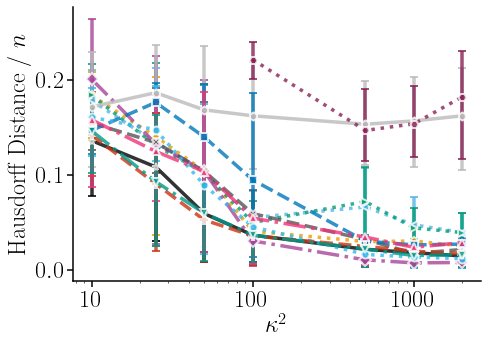

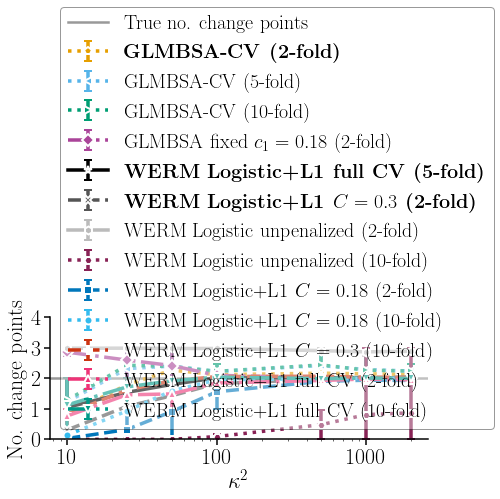

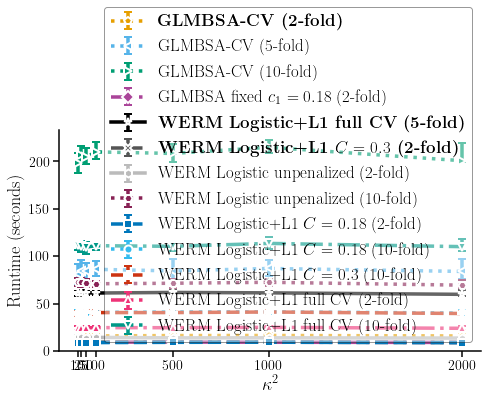


--- Plotting Distributions: boxplots + raw observations ---
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=10: n=69, unique=55, min=0.0316667, Q1=0.138333, median=0.181667, Q3=0.208333, max=0.38, IQR=0.07, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV-5fold; kappa^2=10: n=73, unique=60, min=0.0183333, Q1=0.136667, median=0.181667, Q3=0.21, max=0.341667, IQR=0.0733333, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV-10fold; kappa^2=10: n=74, unique=59, min=0.0183333, Q1=0.137083, median=0.186667, Q3=0.21625, max=0.341667, IQR=0.0791667, collapsed=False
Hausdorff distance / n; method=GLMBSA-fixed0.18-2fold; kappa^2=10: n=100, unique=80, min=0.00333333, Q1=0.150417, median=0.206667, Q3=0.263333, max=0.365, IQR=0.112917, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV; kappa^2=10: n=70, unique=55, min=0.00833333, Q1=0.0775, median=0.130833, Q3=0.183333, max=0.496667, IQR=0.105833, collapsed=False
Hausdorff distance / n; method=WERM-L1-C0.3-2fold; kappa

Hausdorff distance / n; method=WERM-unp-2fold; kappa^2=500: n=100, unique=65, min=0.055, Q1=0.11, median=0.143333, Q3=0.19875, max=0.298333, IQR=0.08875, collapsed=False
Hausdorff distance / n; method=WERM-unp-10fold; kappa^2=500: n=16, unique=14, min=0.0583333, Q1=0.115, median=0.145, Q3=0.19, max=0.215, IQR=0.075, collapsed=False
Hausdorff distance / n; method=WERM-L1-C0.18-2fold; kappa^2=500: n=100, unique=35, min=0, Q1=0.00333333, median=0.00833333, Q3=0.0233333, max=0.2, IQR=0.02, collapsed=False
Hausdorff distance / n; method=WERM-L1-C0.18-10fold; kappa^2=500: n=100, unique=24, min=0, Q1=0.00333333, median=0.00666667, Q3=0.0166667, max=0.196667, IQR=0.0133333, collapsed=False
Hausdorff distance / n; method=WERM-L1-C0.3-10fold; kappa^2=500: n=100, unique=34, min=0, Q1=0.00333333, median=0.01, Q3=0.03375, max=0.196667, IQR=0.0304167, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV-2fold; kappa^2=500: n=100, unique=38, min=0, Q1=0.005, median=0.01, Q3=0.0333333, max=0.

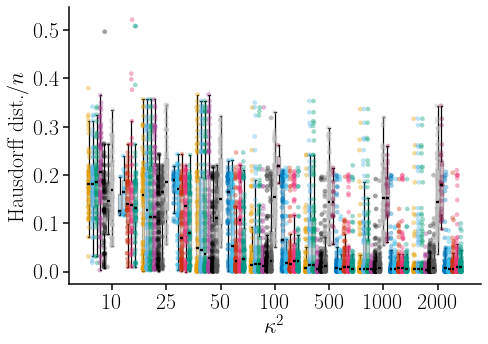

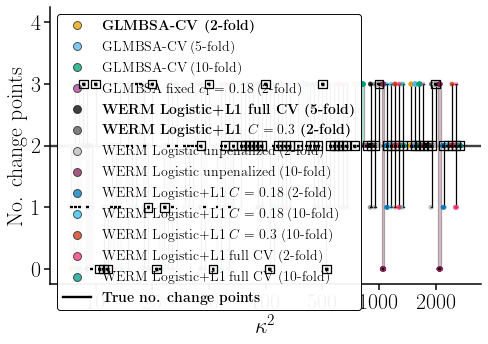

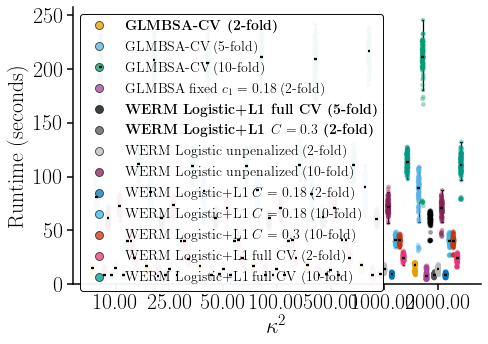


--- Plotting Changepoint Histograms ---


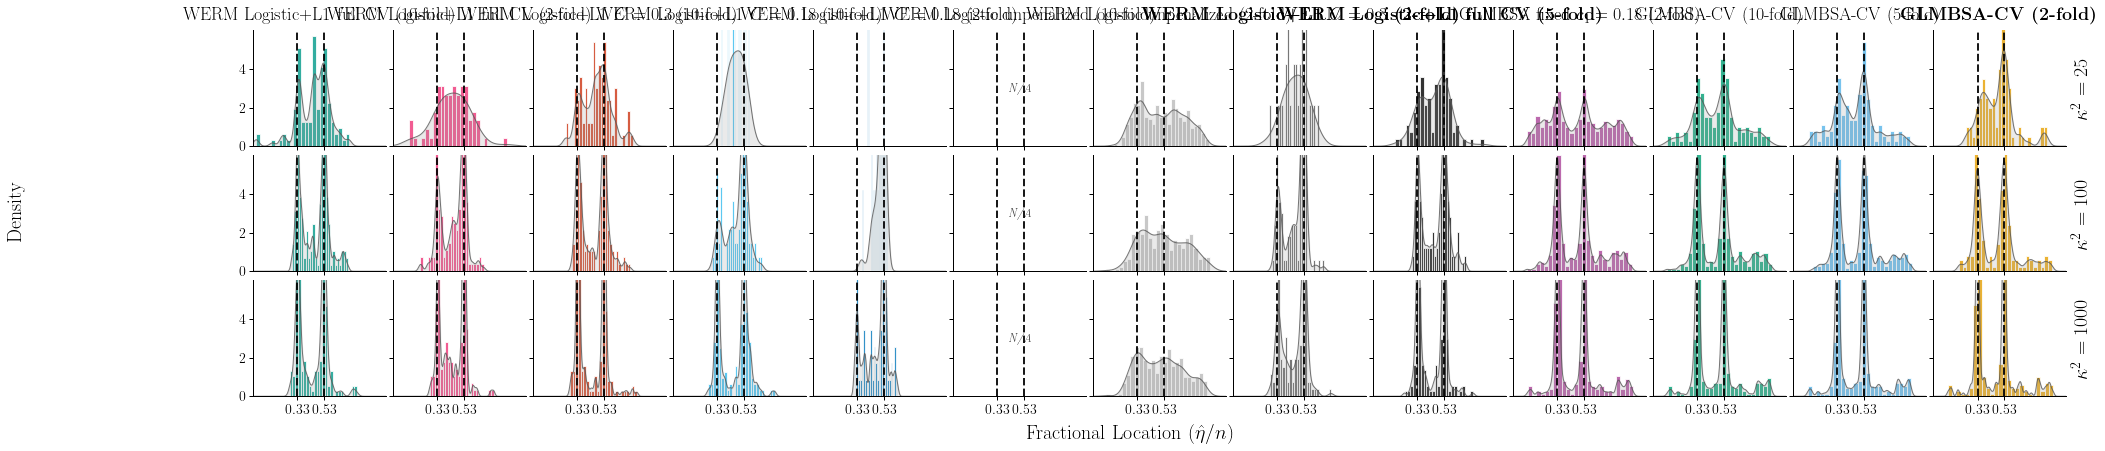

Publication-ready plotting completed in 13.15 seconds


In [6]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

methods_to_evaluate = [
    {'name': 'GLMBSA-CV', 'label': '\\textbf{GLMBSA-CV (2-fold)}', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-5fold', 'label': 'GLMBSA-CV (5-fold)', 'color': '#56B4E9', 'marker': '<', 'linestyle': ':'},
    {'name': 'GLMBSA-CV-10fold', 'label': 'GLMBSA-CV (10-fold)', 'color': '#009E73', 'marker': '>', 'linestyle': ':'},
    {'name': 'GLMBSA-fixed0.18-2fold', 'label': 'GLMBSA fixed $c_1=0.18$ (2-fold)', 'color': '#AA4499', 'marker': 'D', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV', 'label': '\\textbf{WERM Logistic+L1 full CV (5-fold)}', 'color': 'black', 'marker': '*', 'linestyle': '-'},
    {'name': 'WERM-L1-C0.3-2fold', 'label': '\\textbf{WERM Logistic+L1 $C=0.3$ (2-fold)}', 'color': '#555555', 'marker': 'X', 'linestyle': '--'},
    {'name': 'WERM-unp-2fold', 'label': 'WERM Logistic unpenalized (2-fold)', 'color': '#BBBBBB', 'marker': 'h', 'linestyle': '-'},
    {'name': 'WERM-unp-10fold', 'label': 'WERM Logistic unpenalized (10-fold)', 'color': '#882255', 'marker': 'H', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.18-2fold', 'label': 'WERM Logistic+L1 $C=0.18$ (2-fold)', 'color': '#0077BB', 'marker': 's', 'linestyle': '--'},
    {'name': 'WERM-L1-C0.18-10fold', 'label': 'WERM Logistic+L1 $C=0.18$ (10-fold)', 'color': '#33BBEE', 'marker': 'o', 'linestyle': ':'},
    {'name': 'WERM-L1-C0.3-10fold', 'label': 'WERM Logistic+L1 $C=0.3$ (10-fold)', 'color': '#CC3311', 'marker': 'P', 'linestyle': '--'},
    {'name': 'WERM-L1-fullCV-2fold', 'label': 'WERM Logistic+L1 full CV (2-fold)', 'color': '#EE3377', 'marker': '^', 'linestyle': '-.'},
    {'name': 'WERM-L1-fullCV-10fold', 'label': 'WERM Logistic+L1 full CV (10-fold)', 'color': '#009988', 'marker': 'v', 'linestyle': '-.'},
]

method_colors_map = {method['name']: method['color'] for method in methods_to_evaluate}
PAL = [method['color'] for method in methods_to_evaluate]

# KDE / Histogram Context Style
kde_style = {
    'color': '#555555',       # Dark Grey line for definition
    'linestyle': '-',         # Solid line (distinct from competitor dashes)
    'linewidth': 1.0,         # Thinner than your methods (1.0 vs 1.5/2.5)
    'alpha': 0.8,             # Slight transparency for the line itself
    'fill_color': '#999999',  # Lighter grey for the area
    'fill_alpha': 0.2         # Very transparent fill
}

import sys
import numpy as np
import time
import matplotlib
import gc
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import pickle
import os


# Ensure the 'figures' directory exists
FIGURES_DIR = 'results/M3_upsample_redo2_plots/final_M3_upsample_format'
if not os.path.exists(FIGURES_DIR):
    os.makedirs(FIGURES_DIR)

# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except Exception:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

try:
    # A dummy logger function to prevent NameError if main_logger is not defined
    def dummy_logger_info(message):
        print(message)
    main_logger = type('Logger', (object,), {'info': staticmethod(dummy_logger_info)})()
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()

print("Plotting M3d delta=3, alpha=0.1")
print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data ---
# Load the completed eleven-method artifact; this cell never reruns the experiment.
filename_to_load = 'results/M3d_redo_delta3_alpha01_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42_100trials.pkl'
if os.environ.get('WERM_SMOKE') == '1':
    filename_to_load = filename_to_load.replace('_100trials.pkl', '_smoke.pkl')
try:
    with open(filename_to_load, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    kappa_list = params['kappa_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    fixed_delta = params['fixed_delta']
    signal_alpha = params.get('signal_alpha', 0.1)
    n_jobs = params['n_jobs']
    # methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', 42) # Get random_seed if available

    # Ensure colors are assigned from the palette in order for loaded methods
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]
    print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")
    # Change the method name from 'WERM-CV' to 'WERM'
    for method in methods_to_evaluate:
        if method['name'] == 'WERM-CV':
            method['label'] = r'\textbf{WERM}'

    method_names_list = [method['name'] for method in methods_to_evaluate]
    assert [method['name'] for method in params['methods_evaluated']] == method_names_list

except FileNotFoundError:
    print(f"Error: Results file '{filename_to_load}' not found. Please ensure your results are saved.")
    print("For demonstration, creating dummy data.")
    # Create dummy data for demonstration if file not found
    p = 200
    L = 4
    noise_std = 0.7745966692414834
    kappa_list = np.array([1, 2, 3, 4, 5]) # Example kappas
    fractional_chgpt_locations = np.array([0.2, 0.4, 0.6, 0.8])
    num_trials = 10
    n_jobs = 1
    methods_to_evaluate = [
        {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'marker': 'o', 'linestyle': '-'},
        {'name': 'WERM-CV', 'label': r'\textbf{WERM-CV}', 'marker': 's', 'linestyle': '--'},
    ]
    method_names_list = [method['name'] for method in methods_to_evaluate]

    # Assign colors from palette
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]

    results = {}
    for metric in ['haus', 'size', 'runtime', 'chgpts']:
        for method_config in methods_to_evaluate:
            method_name = method_config['name']
            key = f'{metric}_{method_name}'
            if metric == 'chgpts':
                results[key] = []
                for kappa_idx, kappa_val in enumerate(kappa_list):
                    n_for_kappa = int(kappa_val * p)
                    for _ in range(num_trials):
                        num_chgpts_detected = np.random.randint(L - 1, L + 2)
                        # Fix for histogram: Ensure dummy changepoints span 0-1 range
                        dummy_chgpts_fractional = np.random.rand(num_chgpts_detected)
                        # Scale to actual indices (0 to n_for_kappa) for storage
                        results[key].append((kappa_idx, dummy_chgpts_fractional * n_for_kappa))
            else:
                results[key] = np.random.rand(len(kappa_list), num_trials)
                if metric == 'size':
                    results[key] = np.round(results[key] * (L + 2)).astype(int)
                elif metric == 'runtime':
                    results[key] = results[key] * 10
                elif metric == 'haus':
                    results[key] = results[key] * 0.2 + 0.05
    random_seed = 42 # Set dummy seed

for method_name in method_names_list:
    _size = np.asarray(results[f'size_{method_name}'], dtype=float)
    _haus = np.asarray(results[f'haus_{method_name}'], dtype=float)
    results[f'haus_{method_name}'] = np.where(_size > 0, _haus, np.nan)

print("Data loaded for plotting; empty-estimate Hausdorff values are NaN.")

# Filter kappa_list for plotting from kappa = 1.5 and onwards
kappa_list = np.array(kappa_list) # Ensure it's a numpy array for easy filtering
kappa_start_index = np.where(kappa_list >= 1.5)[0]
if len(kappa_start_index) > 0:
    kappa_start_index = kappa_start_index[0]
else: # If no kappa >= 1.5, use the whole list or handle as an error
    kappa_start_index = 0
    print("Warning: No kappa values >= 1.5 found. Using all available kappa values for filtering.")

kappa_list_filtered = kappa_list[kappa_start_index:]

# Replace kappa list with kappa^2 values for plotting
kappa_list_filtered = np.power(kappa_list_filtered, 2)
kappa_list = np.power(kappa_list, 2)

# Filter results based on the new kappa_list for line plots and all box plots
results_filtered = {}
for key, value in results.items():
    if key.startswith(('haus_', 'size_', 'runtime_')):
        if value.shape[0] > kappa_start_index:
            results_filtered[key] = value[kappa_start_index:, :]
        else:
            results_filtered[key] = np.empty((0, value.shape[1]))

print(f"DEBUG: Original kappa_list: {kappa_list}")
print(f"DEBUG: Filtered kappa_list (>= 1.5): {kappa_list_filtered}")
print(f"DEBUG: Method names available: {method_names_list}")
print(f"DEBUG: First few haus results (filtered): {results_filtered.get('haus_GLMBSA-CV', 'Not available')[:2]}") # Changed to GLMBSA for consistency with example filename

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Asymmetric Error Bars Plotting Functions (Separated) ---

x_y_label_fontsize = 22

def plot_location_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Location Error}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'haus_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Hausdorff) for current kappa_list. Skipping plot for this metric.")
            continue
        data = np.where(np.isinf(data), np.nan, data)
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
    ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=24)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=24)
    ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.get_xaxis().set_minor_formatter(matplotlib.ticker.NullFormatter())
    # Set the tick font size larger for better readability
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=24)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=24)
    # ax.legend(loc='upper right', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pgf"))
    plt.show()

    # Replot the above, with in log-scale on the x axis
    # fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # # ax.set_title(r'\textbf{Changepoint Location Error (Log Scale)}', fontsize=18, pad=15) # Title removed 
    # for i, method_obj in enumerate(methods_to_evaluate):
    #     method_name = method_obj['name']
    #     data = current_results.get(f'haus_{method_name}')
    #     if data is None or data.size == 0 or np.all(np.isnan(data)):
    #         continue
    #     data = np.where(np.isinf(data), np.nan, data)
    #     means = np.nanmean(data, axis=1)
    #     errors = get_asymmetric_errors(data)
    #     ax.errorbar(current_kappa_list, means, yerr=errors,
    #                 label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
    #                 color=plot_colors[i], capsize=4, capthick=2, markersize=8,
    #                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    # ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    # ax.set_xlabel(r'$\kappa$ (log scale)', fontsize=18)
    # ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    # ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.tick_params(axis='both', which='major', width=1.5, length=6)
    # ax.spines['top'].set_visible(False)
    # ax.spines['right'].set_visible(False)
    # ax.spines['left'].set_linewidth(1.5)
    # ax.spines['bottom'].set_linewidth(1.5)
    # ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    # plt.tight_layout()
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pdf"))
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pgf"))
    # plt.show()

def plot_size_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Set Size}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'size_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Size) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_xscale('log')
    ax.axhline(y=len(fractional_chgpt_locations), color='gray', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'True no. change points')
    ax.set_ylim((0, L))
    ax.set_yticks(np.arange(0, L + 1, step=1).astype(int))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=x_y_label_fontsize)
    ax.set_ylabel(r'No. change points', fontsize=x_y_label_fontsize)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=x_y_label_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 20}, fancybox = True, framealpha = 0.4)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=x_y_label_fontsize)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pgf"))
    plt.show()

def plot_runtime_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Method Runtime}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'runtime_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Runtime) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\kappa^2$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pgf"))
    plt.show()

# --- Distribution Plotting Functions -----------------------------------------
#
# Three display modes are supported:
#   1. "box_jitter"      : standard boxplot + all observations (recommended)
#   2. "interval_jitter" : 5--95%, IQR, median + all observations
#   3. "violin_jitter"   : violin + IQR/median + all observations
#
# A box with Q1 == Q3 is statistically supposed to collapse.  We therefore do
# not artificially change its quartiles.  Instead, collapsed IQRs are reinforced
# with a thick horizontal line and, optionally, a hollow-square glyph.

from matplotlib.lines import Line2D


_DISTRIBUTION_STYLES = {"box_jitter", "interval_jitter", "violin_jitter"}
_COLLAPSED_STYLES = {"line", "line_and_marker", "none"}


def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }


def _warn(message):
    """Use the project logger when it supports warnings; otherwise print."""
    logger = globals().get("main_logger")
    warning_method = getattr(logger, "warning", None)
    if callable(warning_method):
        warning_method(message)
    else:
        print(f"WARNING: {message}")


def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)


def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.38,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )


def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )


def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_summary(
    ax,
    position,
    color,
    summary,
    box_width,
    collapsed_style,
):
    """Draw 5--95%, IQR, and median summaries."""
    cap_half_width = 0.14 * box_width

    # Thin 5--95% interval and end caps.
    ax.vlines(
        position,
        summary["q05"],
        summary["q95"],
        color="black",
        linewidth=1.35,
        zorder=5,
    )
    ax.hlines(
        [summary["q05"], summary["q95"]],
        position - cap_half_width,
        position + cap_half_width,
        color="black",
        linewidth=1.35,
        zorder=5,
    )

    # Thick IQR interval. It correctly becomes a point/line when IQR=0.
    ax.vlines(
        position,
        summary["q25"],
        summary["q75"],
        color=color,
        linewidth=8.0,
        alpha=0.58,
        zorder=5,
    )

    # Median remains visible even when every interval collapses.
    ax.scatter(
        [position],
        [summary["median"]],
        marker="D",
        s=46,
        facecolor=color,
        edgecolor="black",
        linewidth=0.9,
        zorder=7,
        label="_nolegend_",
    )

    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw raw observations together with quantile intervals and the median."""
    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _draw_violin_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """
    Draw a violin/raincloud-style display plus points and quantile summaries.

    The violin is omitted when there are fewer than two distinct observations,
    because a kernel density is then undefined/uninformative.
    """
    if values.size >= 2 and summary["n_unique"] >= 2:
        parts = ax.violinplot(
            [values],
            positions=[position],
            widths=1.15 * box_width,
            showmeans=False,
            showmedians=False,
            showextrema=False,
            points=100,
            bw_method="scott",
        )
        body = parts["bodies"][0]
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_linewidth(1.0)
        body.set_alpha(0.20)
        body.set_zorder(1)

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _format_distribution_diagnostic(metric_label, method_name, kappa, summary):
    return (
        f"{metric_label}; method={method_name}; kappa^2={kappa:g}: "
        f"n={summary['n']}, unique={summary['n_unique']}, "
        f"min={summary['min']:.6g}, Q1={summary['q25']:.6g}, "
        f"median={summary['median']:.6g}, Q3={summary['q75']:.6g}, "
        f"max={summary['max']:.6g}, IQR={summary['iqr']:.6g}, "
        f"collapsed={summary['collapsed']}"
    )


def _plot_grouped_distributions(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    metric_prefix,
    metric_label,
    y_label,
    filename_base,
    filename_metric,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    random_seed=2026,
    box_width=0.72,
    jitter_width=0.20,
    point_size=22,
    point_alpha=0.38,
    diagnostics=False,
    show_legend=True,
    legend_loc="upper left",
    y_limits=None,
    y_ticks=None,
    reference_y=None,
    reference_label=None,
    x_label=r'$\kappa^2$',
    tick_label_format=".0f",
):
    """Shared implementation for location, size, and runtime distributions."""
    if plot_style not in _DISTRIBUTION_STYLES:
        raise ValueError(
            f"plot_style must be one of {sorted(_DISTRIBUTION_STYLES)}, "
            f"got {plot_style!r}."
        )
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )

    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    rng = np.random.default_rng(random_seed)

    plot_labels = [method["label"] for method in methods_to_evaluate]
    plot_colors = [method["color"] for method in methods_to_evaluate]
    methods = [method["name"] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    diagnostic_records = []

    for kappa_idx, kappa in enumerate(current_kappa_list):
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f"{metric_prefix}_{method_name}")
            if data is None or data.ndim < 2 or data.shape[0] <= kappa_idx:
                _warn(
                    f"No {metric_label} data for {method_name} at "
                    f"kappa^2={kappa:g}; skipping this group."
                )
                continue

            values = _finite_1d(data[kappa_idx, :])
            if values.size == 0:
                _warn(
                    f"No finite {metric_label} observations for {method_name} "
                    f"at kappa^2={kappa:g}; skipping this group."
                )
                continue

            summary = _distribution_summary(values)
            position = kappa_idx * spacing + method_idx
            color = plot_colors[method_idx]

            record = {
                "metric": metric_label,
                "method": method_name,
                "kappa_squared": float(kappa),
                **summary,
            }
            diagnostic_records.append(record)
            if diagnostics:
                print(
                    _format_distribution_diagnostic(
                        metric_label, method_name, kappa, summary
                    )
                )

            draw_kwargs = dict(
                ax=ax,
                values=values,
                position=position,
                color=color,
                rng=rng,
                summary=summary,
                box_width=box_width,
                jitter_width=jitter_width,
                point_size=point_size,
                point_alpha=point_alpha,
                collapsed_style=collapsed_style,
            )

            if plot_style == "box_jitter":
                _draw_box_jitter_group(**draw_kwargs)
            elif plot_style == "interval_jitter":
                _draw_interval_jitter_group(**draw_kwargs)
            else:
                _draw_violin_jitter_group(**draw_kwargs)

    # Optional horizontal truth/reference line.
    if reference_y is not None:
        ax.axhline(
            y=reference_y,
            color="black",
            linestyle="-",
            linewidth=2.4,
            alpha=0.75,
            zorder=0,
            label="_nolegend_",
        )

    kappa_positions = [
        i * spacing + (len(methods) - 1) / 2
        for i in range(len(current_kappa_list))
    ]
    ax.set_xticks(kappa_positions)
    ax.set_xticklabels(
        [format(float(k), tick_label_format) for k in current_kappa_list]
    )
    ax.set_xlabel(x_label, fontsize=x_y_label_fontsize)
    ax.set_ylabel(y_label, fontsize=x_y_label_fontsize)

    if y_limits is not None:
        ax.set_ylim(*y_limits)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)

    if show_legend:
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markersize=8,
                markerfacecolor=plot_colors[i],
                markeredgecolor="black",
                markeredgewidth=0.8,
                alpha=0.75,
                label=plot_labels[i],
            )
            for i in range(len(methods))
        ]
        if reference_y is not None and reference_label is not None:
            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    color="black",
                    linewidth=2.4,
                    label=reference_label,
                )
            )
        ax.legend(
            handles=legend_elements,
            loc=legend_loc,
            fontsize=14,
            frameon=True,
            edgecolor="black",
            framealpha=0.95,
        )

    ax.tick_params(
        axis="both",
        which="major",
        width=1.5,
        length=6,
        labelsize=x_y_label_fontsize,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    # Keep the historical filenames for the recommended box+jitter mode.
    style_suffix = {
        "box_jitter": "boxplots",
        "interval_jitter": "interval_jitter",
        "violin_jitter": "violin_jitter",
    }[plot_style]
    output_stem = f"{filename_base}_{filename_metric}_{style_suffix}"

    fig.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pdf"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.png"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pgf"))
    plt.show()

    return fig, ax, diagnostic_records


def plot_location_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot the Hausdorff-error distributions.

    Recommended publication mode: plot_style="box_jitter".
    Clean alternative:             plot_style="interval_jitter".
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="haus",
        metric_label="Hausdorff distance / n",
        y_label=r'Hausdorff dist./$n$',
        filename_base=filename_base,
        filename_metric="location",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=False,
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_size_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot estimated changepoint counts.

    Because this response is discrete, box+jitter or interval+jitter is preferable
    to a violin plot, whose kernel smoothing can imply nonexistent values.
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="size",
        metric_label="Number of change points",
        y_label=r'No. change points',
        filename_base=filename_base,
        filename_metric="size",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(-0.25, L + 0.25),
        y_ticks=np.arange(0, L + 1, dtype=int),
        reference_y=len(fractional_chgpt_locations),
        reference_label=r'\textbf{True no. change points}',
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_runtime_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """Plot runtime distributions using any supported display mode."""
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="runtime",
        metric_label="Runtime (seconds)",
        y_label=r'Runtime (seconds)',
        filename_base=filename_base,
        filename_metric="runtime",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(0, None),
        tick_label_format=".2f",
        x_label=r'$\kappa^2$',
    )

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms (Optimized Layout)
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(original_results, original_kappa_list, fractional_chgpt_locations, methods_to_plot_names_, p):
    """
    Publication-ready changepoint location histograms with tight layout (Kappa variant)
    """

    # 1. Setup Data
    # Use existing method_plotting_info/methods_to_evaluate if available, else fallback
    try:
        method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
        method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    except:
        import seaborn as sns
        pal = sns.color_palette("colorblind", len(methods_to_plot_names_))
        method_names_map = {name: name.upper() for name in methods_to_plot_names_}
        method_colors_map = {name: pal[i] for i, name in enumerate(methods_to_plot_names_)}

    current_methods = methods_to_plot_names_.copy()
    # current_method_names = [method['name'] for method in current_methods] # Adaptation: input is already names list
    
    # Reverse order as per original request
    # method_names_map = {k: method_names_map[k] for k in reversed(method_names_map)} # Key error risk if iterating dict
    current_methods.reverse()
    current_method_names = current_methods

    # Kappa Selection Logic (Adapted from Template's Delta Logic)
    selected_kappas_idx = [i for i, k in enumerate(original_kappa_list) if k >= 1.5]
    selected_kappas = [original_kappa_list[i] for i in selected_kappas_idx]
    
    num_rows = len(selected_kappas)
    num_cols = len(current_methods)

    # 2. Setup Figure - TIGHTER DIMENSIONS
    # Using a roughly 3:2.5 ratio per subplot, scaled for standard latex textwidth
    # A width of 14-16 inches usually scales down perfectly to a 7 inch page width
    fig, axes = plt.subplots(num_rows, num_cols,
                             figsize=(2.5 * num_cols, 2.2 * num_rows), 
                             sharex=True, sharey=True,
                             gridspec_kw={'wspace': 0.05, 'hspace': 0.08}) # <--- KEY FOR TIGHTNESS
    
    # Handle single subplot cases to ensure axes is always 2D array
    if num_rows == 1 and num_cols == 1:
        axes = np.array([[axes]])
    elif num_cols == 1:
        axes = axes.reshape(-1, 1)
    elif num_rows == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')

    # 3. Plotting Loop
    for row, (kappa_idx, kappa) in enumerate(zip(selected_kappas_idx, selected_kappas)):
        # Calculate n based on fixed_delta (assuming global) or fallback
        try:
            n = int(fixed_delta * p)
        except:
            n = 100
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # --- Data Collection (Adapted for Kappa structure) ---
            all_chgpts = []
            chgpts_data_for_method = original_results.get(f'chgpts_{method_name}', [])
            
            for stored_kappa_idx, chgpts_list in chgpts_data_for_method:
                if stored_kappa_idx == kappa_idx:
                     # Robust handling for list-of-lists vs arrays
                    if isinstance(chgpts_list, list):
                        for chgpts_arr in chgpts_list:
                            if chgpts_arr is not None and len(chgpts_arr) > 0:
                                arr = np.array(chgpts_arr)
                                if not (np.isscalar(arr) and np.isnan(arr)):
                                    valid = arr[arr != -1]
                                    for x in valid: all_chgpts.append(x / n)
                    elif chgpts_list is not None:
                        arr = np.array(chgpts_list)
                        if arr.size > 0 and not (np.isscalar(arr) and np.isnan(arr)):
                            valid = arr[arr != -1]
                            for x in valid: all_chgpts.append(x / n)
            
            # --- Plotting ---
            if len(all_chgpts) > 0:
                # Histogram
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                color=method_colors_map.get(method_name, 'blue'),
                                                density=True, edgecolor='white',
                                                linewidth=1.0) # Thinner line for tighter look
                
                # KDE (GridSearch Logic)
                if len(all_chgpts) > 6:
                    try:
                        # Use grid search to find optimal bandwidth
                        params = {'bandwidth': np.logspace(-2, 0, 50)}
                        grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)
                        grid.fit(np.array(all_chgpts).reshape(-1, 1))
                        
                        x_range = np.linspace(0, 1, 200)
                        # Score_samples returns log-density, so we exponentiate
                        log_dens = grid.best_estimator_.score_samples(x_range.reshape(-1, 1))
                        kde_values = np.exp(log_dens)
                        
                        # --- UPDATED PLOTTING LOGIC ---
                        # 1. Plot the line (Dark Grey)
                        ax.plot(x_range, kde_values, 
                                color=kde_style['color'], 
                                linewidth=kde_style['linewidth'],
                                linestyle=kde_style['linestyle'], # Solid line for context
                                alpha=kde_style['alpha'], 
                                label='KDE', # No bolding, keep it contextual
                                zorder=2) # Low z-order to sit BEHIND methods
                        
                        # 2. Add the fill (Subtle Grey)
                        # This makes the "shape" of the data distribution easier to see
                        ax.fill_between(x_range, kde_values, 
                                        color=kde_style['fill_color'], 
                                        alpha=kde_style['fill_alpha'],
                                        zorder=1)
                    except:
                        pass
            else:
                ax.text(0.5, 0.5, r'\textit{N/A}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=12, alpha=0.7, style='italic')
            
            # True Changepoints
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', 
                           linewidth=2, alpha=0.9, zorder=10,
                           label=r'\textbf{True changepoints}' if i == 0 else "")

            # --- Formatting & Ticks ---
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 6) # Enforce uniform height
            
            # Clean spines
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.0)
            ax.spines['bottom'].set_linewidth(1.0)
            
            # Custom ticks - apply to ALL, but sharex hides labels automatically
            ax.set_xticks(np.array([*fractional_chgpt_locations]))
            # ax.set_xticklabels([*[f'${tc:.2f}$' for tc in fractional_chgpt_locations]], fontsize=12)
            ax.set_xticklabels(['$0.33$', '$0.53$'], fontsize=10)
            ax.set_yticks([0, 2, 4]) # Minimal Y-ticks
            
            # Tick parameters
            # 'labelleft' and 'labelbottom' control visibility explicitly if sharex/y fails
            ax.tick_params(axis='both', which='major', width=1, length=4, labelsize=14)

            # 4. Labels and Titles (Specific Locations Only)
            
            # Column Titles (Method Names) - Only Top Row
            if row == 0:
                ax.set_title(f'{method_names_map.get(method_name, method_name)}', fontsize=18, pad=10)
            
            # Row Labels (Kappa) - Right side of Last Column
            if col == num_cols - 1:
                # Use ax.text roughly in the middle right
                ax.text(1.05, 0.5, rf'$\kappa$\textsuperscript{{2}} $= {kappa:.0f}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', horizontalalignment='left',
                        fontsize=20, fontweight='bold')

            # X-Axis Label - Bottom Row, Centered on Figure not Subplot
            # We skip per-subplot labels to save space
    
    # Global Labels (cleaner than per-subplot)
    fig.text(0.5, 0.01, r'Fractional Location ($\hat{\mathbf{\eta}}/n$)', 
             ha='center', va='bottom', fontsize=20)
    fig.text(0.02, 0.5, r'Density', 
             va='center', rotation='vertical', fontsize=20)

    # 5. Legend
    # Place one legend for the whole figure, or inside the first visible plot
    # Here we put it in the first plot, but make it compact
    first_ax = axes[0, 0]
    handles, labels = first_ax.get_legend_handles_labels()
    # if handles:
    #     # Create a legend that floats slightly inside the plot
    #     legend = first_ax.legend(loc='upper right', fontsize=18, frameon=True,
    #                              edgecolor='white', framealpha=0.8, handlelength=1.5)
    #     legend.set_zorder(20)

    # Final Tight Layout to handle the global labels
    # rect tuple is (left, bottom, right, top)
    plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96]) 
    
    return fig, axes

# Get a base filename for saving figures based on the loaded data's properties
# This uses the original filename from which data was loaded to create a consistent naming convention
filename_base_for_plots = 'final_M3_upsample_format_' + os.path.basename(filename_to_load).replace('.pkl', '')
print(f"Base filename for saving plots: {filename_base_for_plots}")

# --- Execute plotting functions ---
print("\n--- Plotting Asymmetric Error Bars ---")
plot_location_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_size_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_runtime_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots)

print("\n--- Plotting Distributions: boxplots + raw observations ---")

# Recommended figure: retain the familiar boxplot, but show every repetition.
# Set this to False after you have diagnosed the collapsed groups once.
PRINT_DISTRIBUTION_DIAGNOSTICS = True

plot_location_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=PRINT_DISTRIBUTION_DIAGNOSTICS,
)
plot_size_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)
plot_runtime_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)

# Optional alternative outputs. These use distinct filenames, so they do not
# overwrite the recommended box+jitter figures.
PLOT_ALTERNATIVE_DISTRIBUTIONS = False
if PLOT_ALTERNATIVE_DISTRIBUTIONS:
    print("\n--- Plotting Distributions: quantile intervals + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_size_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        L,
        fractional_chgpt_locations,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )

    # Violin plots are optional for continuous metrics. They are deliberately
    # not generated for the integer-valued changepoint-count metric.
    print("\n--- Plotting Distributions: violin + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )

print("\n--- Plotting Changepoint Histograms ---")
fig_hist, axes_hist = plot_changepoint_histograms_publication(results, kappa_list[::2], fractional_chgpt_locations, method_names_list, p=p)
_histogram_stem = os.path.join(FIGURES_DIR, f'{filename_base_for_plots}_changepoint_histograms')
fig_hist.savefig(f'{_histogram_stem}.pdf', dpi=300, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.png', dpi=200, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.pgf', dpi=300, bbox_inches='tight')
plt.show()


plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

### Two-method comparison: 2-fold full CV only

Removing 110 matplotlib modules...


Successfully set backend to: module://matplotlib_inline.backend_inline
Creating publication-ready plots...
Plotting M3d delta=3, alpha=0.1
Using palette: ['#E69F00', '#EE3377'] (Paul Tol Vibrant)
Using palette: ['#E69F00', '#EE3377'] (Paul Tol Vibrant assigned to methods)
Data loaded for plotting; empty-estimate Hausdorff values are NaN.
DEBUG: Original kappa_list: [1.0e+00 1.0e+01 2.5e+01 5.0e+01 1.0e+02 5.0e+02 1.0e+03 2.0e+03]
DEBUG: Filtered kappa_list (>= 1.5): [  10.   25.   50.  100.  500. 1000. 2000.]
DEBUG: Method names available: ['GLMBSA-CV', 'WERM-L1-fullCV-2fold']
DEBUG: First few haus results (filtered): [[0.145      0.21666667 0.17833333 0.13166667        nan 0.16166667
         nan 0.11       0.17166667 0.10833333 0.18166667 0.31166667
  0.24666667 0.23666667 0.18166667        nan 0.20833333 0.20666667
  0.17       0.18166667 0.25              nan 0.12166667 0.2
  0.16666667        nan 0.22       0.255      0.32       0.11166667
  0.165      0.325      0.13666667 0.295 

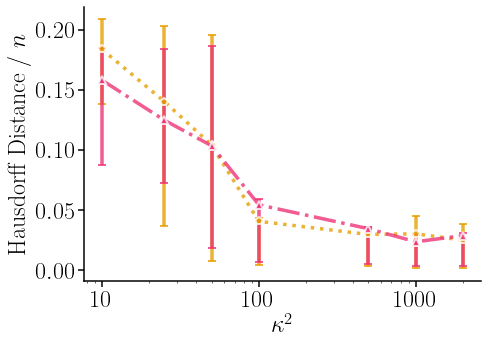

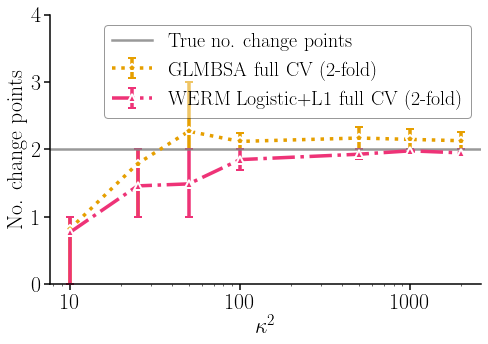

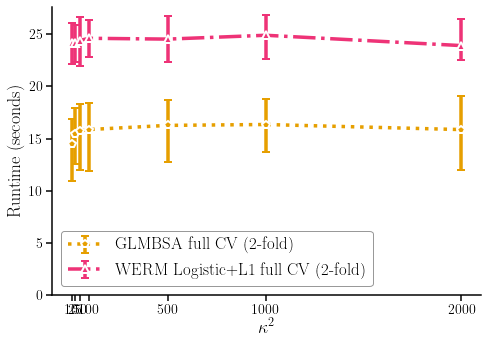


--- Plotting Distributions: boxplots + raw observations ---
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=10: n=69, unique=55, min=0.0316667, Q1=0.138333, median=0.181667, Q3=0.208333, max=0.38, IQR=0.07, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV-2fold; kappa^2=10: n=51, unique=43, min=0.01, Q1=0.0875, median=0.138333, Q3=0.185, max=0.521667, IQR=0.0975, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=25: n=97, unique=72, min=0.00166667, Q1=0.0366667, median=0.158333, Q3=0.203333, max=0.356667, IQR=0.166667, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV-2fold; kappa^2=25: n=92, unique=62, min=0, Q1=0.0729167, median=0.136667, Q3=0.184167, max=0.22, IQR=0.11125, collapsed=False
Hausdorff distance / n; method=GLMBSA-CV; kappa^2=50: n=100, unique=64, min=0, Q1=0.00791667, median=0.05, Q3=0.195417, max=0.366667, IQR=0.1875, collapsed=False
Hausdorff distance / n; method=WERM-L1-fullCV-2fold; kappa^2=50: n=97, unique=62, min=0, Q1=0

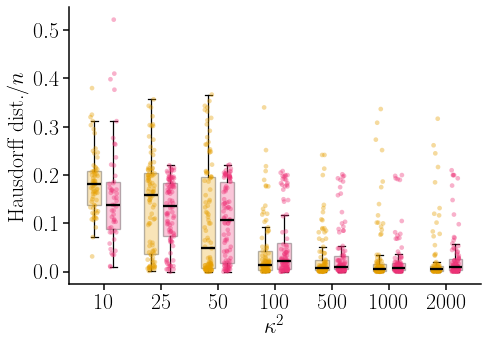

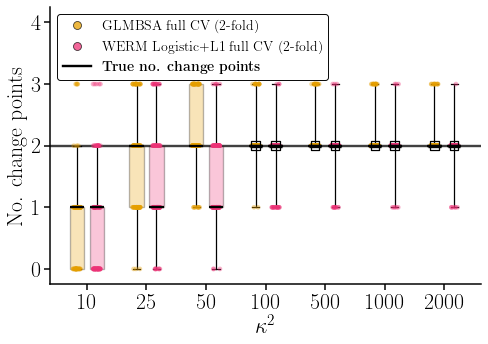

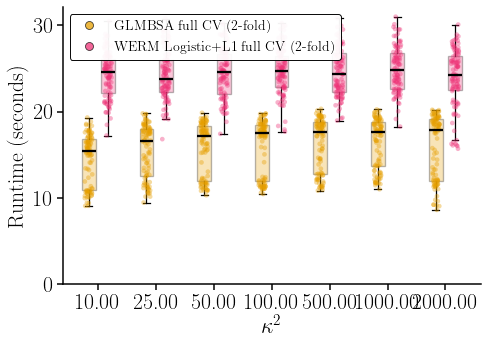


--- Plotting Changepoint Histograms ---


/tmp/ipykernel_245321/2181504968.py:1272: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96])


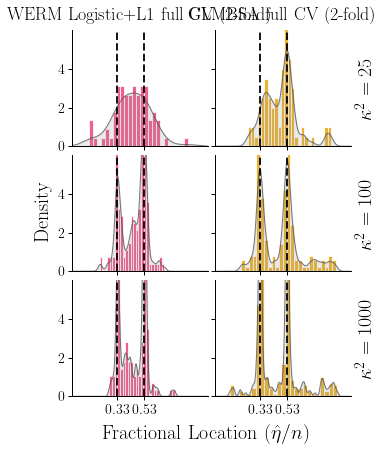

Publication-ready plotting completed in 3.77 seconds


In [3]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

methods_to_evaluate = [
    {'name': 'GLMBSA-CV', 'label': r'GLMBSA full CV (2-fold)', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'},
    {'name': 'WERM-L1-fullCV-2fold', 'label': r'WERM Logistic+L1 full CV (2-fold)', 'color': '#EE3377', 'marker': '^', 'linestyle': '-.'},
]

method_colors_map = {method['name']: method['color'] for method in methods_to_evaluate}
PAL = [method['color'] for method in methods_to_evaluate]

# KDE / Histogram Context Style
kde_style = {
    'color': '#555555',       # Dark Grey line for definition
    'linestyle': '-',         # Solid line (distinct from competitor dashes)
    'linewidth': 1.0,         # Thinner than your methods (1.0 vs 1.5/2.5)
    'alpha': 0.8,             # Slight transparency for the line itself
    'fill_color': '#999999',  # Lighter grey for the area
    'fill_alpha': 0.2         # Very transparent fill
}

import sys
import numpy as np
import time
import matplotlib
import gc
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import pickle
import os


# Ensure the 'figures' directory exists
FIGURES_DIR = 'results/M3_upsample_redo2_plots/final_M3_upsample_format'
if not os.path.exists(FIGURES_DIR):
    os.makedirs(FIGURES_DIR)

# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except Exception:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

try:
    # A dummy logger function to prevent NameError if main_logger is not defined
    def dummy_logger_info(message):
        print(message)
    main_logger = type('Logger', (object,), {'info': staticmethod(dummy_logger_info)})()
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()

print("Plotting M3d delta=3, alpha=0.1")
print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data ---
# Load the completed eleven-method artifact; this cell never reruns the experiment.
filename_to_load = 'results/M3d_redo_delta3_alpha01_glmbsa2-5-10_thirteen_methods_folds2-5-10_seed42_100trials.pkl'
if os.environ.get('WERM_SMOKE') == '1':
    filename_to_load = filename_to_load.replace('_100trials.pkl', '_smoke.pkl')
try:
    with open(filename_to_load, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    kappa_list = params['kappa_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    fixed_delta = params['fixed_delta']
    signal_alpha = params.get('signal_alpha', 0.1)
    n_jobs = params['n_jobs']
    # methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', 42) # Get random_seed if available

    # Ensure colors are assigned from the palette in order for loaded methods
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]
    print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")
    # Change the method name from 'WERM-CV' to 'WERM'
    for method in methods_to_evaluate:
        if method['name'] == 'WERM-CV':
            method['label'] = r'\textbf{WERM}'

    method_names_list = [method['name'] for method in methods_to_evaluate]
    available_method_names = {method['name'] for method in params['methods_evaluated']}
    assert set(method_names_list).issubset(available_method_names)

except FileNotFoundError:
    print(f"Error: Results file '{filename_to_load}' not found. Please ensure your results are saved.")
    print("For demonstration, creating dummy data.")
    # Create dummy data for demonstration if file not found
    p = 200
    L = 4
    noise_std = 0.7745966692414834
    kappa_list = np.array([1, 2, 3, 4, 5]) # Example kappas
    fractional_chgpt_locations = np.array([0.2, 0.4, 0.6, 0.8])
    num_trials = 10
    n_jobs = 1
    methods_to_evaluate = [
        {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'marker': 'o', 'linestyle': '-'},
        {'name': 'WERM-CV', 'label': r'\textbf{WERM-CV}', 'marker': 's', 'linestyle': '--'},
    ]
    method_names_list = [method['name'] for method in methods_to_evaluate]

    # Assign colors from palette
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]

    results = {}
    for metric in ['haus', 'size', 'runtime', 'chgpts']:
        for method_config in methods_to_evaluate:
            method_name = method_config['name']
            key = f'{metric}_{method_name}'
            if metric == 'chgpts':
                results[key] = []
                for kappa_idx, kappa_val in enumerate(kappa_list):
                    n_for_kappa = int(kappa_val * p)
                    for _ in range(num_trials):
                        num_chgpts_detected = np.random.randint(L - 1, L + 2)
                        # Fix for histogram: Ensure dummy changepoints span 0-1 range
                        dummy_chgpts_fractional = np.random.rand(num_chgpts_detected)
                        # Scale to actual indices (0 to n_for_kappa) for storage
                        results[key].append((kappa_idx, dummy_chgpts_fractional * n_for_kappa))
            else:
                results[key] = np.random.rand(len(kappa_list), num_trials)
                if metric == 'size':
                    results[key] = np.round(results[key] * (L + 2)).astype(int)
                elif metric == 'runtime':
                    results[key] = results[key] * 10
                elif metric == 'haus':
                    results[key] = results[key] * 0.2 + 0.05
    random_seed = 42 # Set dummy seed

for method_name in method_names_list:
    _size = np.asarray(results[f'size_{method_name}'], dtype=float)
    _haus = np.asarray(results[f'haus_{method_name}'], dtype=float)
    results[f'haus_{method_name}'] = np.where(_size > 0, _haus, np.nan)

print("Data loaded for plotting; empty-estimate Hausdorff values are NaN.")

# Filter kappa_list for plotting from kappa = 1.5 and onwards
kappa_list = np.array(kappa_list) # Ensure it's a numpy array for easy filtering
kappa_start_index = np.where(kappa_list >= 1.5)[0]
if len(kappa_start_index) > 0:
    kappa_start_index = kappa_start_index[0]
else: # If no kappa >= 1.5, use the whole list or handle as an error
    kappa_start_index = 0
    print("Warning: No kappa values >= 1.5 found. Using all available kappa values for filtering.")

kappa_list_filtered = kappa_list[kappa_start_index:]

# Replace kappa list with kappa^2 values for plotting
kappa_list_filtered = np.power(kappa_list_filtered, 2)
kappa_list = np.power(kappa_list, 2)

# Filter results based on the new kappa_list for line plots and all box plots
results_filtered = {}
for key, value in results.items():
    if key.startswith(('haus_', 'size_', 'runtime_')):
        if value.shape[0] > kappa_start_index:
            results_filtered[key] = value[kappa_start_index:, :]
        else:
            results_filtered[key] = np.empty((0, value.shape[1]))

print(f"DEBUG: Original kappa_list: {kappa_list}")
print(f"DEBUG: Filtered kappa_list (>= 1.5): {kappa_list_filtered}")
print(f"DEBUG: Method names available: {method_names_list}")
print(f"DEBUG: First few haus results (filtered): {results_filtered.get('haus_GLMBSA-CV', 'Not available')[:2]}") # Changed to GLMBSA for consistency with example filename

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Asymmetric Error Bars Plotting Functions (Separated) ---

x_y_label_fontsize = 22

def plot_location_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Location Error}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'haus_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Hausdorff) for current kappa_list. Skipping plot for this metric.")
            continue
        data = np.where(np.isinf(data), np.nan, data)
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
    ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=24)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=24)
    ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.get_xaxis().set_minor_formatter(matplotlib.ticker.NullFormatter())
    # Set the tick font size larger for better readability
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=24)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=24)
    # ax.legend(loc='upper right', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pgf"))
    plt.show()

    # Replot the above, with in log-scale on the x axis
    # fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # # ax.set_title(r'\textbf{Changepoint Location Error (Log Scale)}', fontsize=18, pad=15) # Title removed 
    # for i, method_obj in enumerate(methods_to_evaluate):
    #     method_name = method_obj['name']
    #     data = current_results.get(f'haus_{method_name}')
    #     if data is None or data.size == 0 or np.all(np.isnan(data)):
    #         continue
    #     data = np.where(np.isinf(data), np.nan, data)
    #     means = np.nanmean(data, axis=1)
    #     errors = get_asymmetric_errors(data)
    #     ax.errorbar(current_kappa_list, means, yerr=errors,
    #                 label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
    #                 color=plot_colors[i], capsize=4, capthick=2, markersize=8,
    #                 linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    # ax.set_xscale('log')
    # ax.set_ylim((0, 0.5))
    # ax.set_xlabel(r'$\kappa$ (log scale)', fontsize=18)
    # ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    # ax.set_xticks(current_kappa_list)
    # ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    # ax.tick_params(axis='both', which='major', width=1.5, length=6)
    # ax.spines['top'].set_visible(False)
    # ax.spines['right'].set_visible(False)
    # ax.spines['left'].set_linewidth(1.5)
    # ax.spines['bottom'].set_linewidth(1.5)
    # ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    # plt.tight_layout()
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pdf"))
    # plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors_logscale.pgf"))
    # plt.show()

def plot_size_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Set Size}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'size_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Size) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')

    ax.set_xscale('log')
    ax.axhline(y=len(fractional_chgpt_locations), color='gray', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'True no. change points')
    ax.set_ylim((0, L))
    ax.set_yticks(np.arange(0, L + 1, step=1).astype(int))
    ax.set_xlabel(r'$\kappa\textsuperscript{2}$', fontsize=x_y_label_fontsize)
    ax.set_ylabel(r'No. change points', fontsize=x_y_label_fontsize)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=x_y_label_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 20}, fancybox = True, framealpha = 0.4)
    # Set x-ticks to 10^1, 10^2, 10^3, etc.
    ax.set_xticks(np.array([10, 100, 1000]), minor=False)
    # Set the x-tick labels to use \textsuperscript
    ax.set_xticklabels([r'$10$', r'$100$', r'$1000$'], fontsize=x_y_label_fontsize)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pgf"))
    plt.show()

def plot_runtime_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Method Runtime}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'runtime_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Runtime) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\kappa^2$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.png"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pgf"))
    plt.show()

# --- Distribution Plotting Functions -----------------------------------------
#
# Three display modes are supported:
#   1. "box_jitter"      : standard boxplot + all observations (recommended)
#   2. "interval_jitter" : 5--95%, IQR, median + all observations
#   3. "violin_jitter"   : violin + IQR/median + all observations
#
# A box with Q1 == Q3 is statistically supposed to collapse.  We therefore do
# not artificially change its quartiles.  Instead, collapsed IQRs are reinforced
# with a thick horizontal line and, optionally, a hollow-square glyph.

from matplotlib.lines import Line2D


_DISTRIBUTION_STYLES = {"box_jitter", "interval_jitter", "violin_jitter"}
_COLLAPSED_STYLES = {"line", "line_and_marker", "none"}


def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }


def _warn(message):
    """Use the project logger when it supports warnings; otherwise print."""
    logger = globals().get("main_logger")
    warning_method = getattr(logger, "warning", None)
    if callable(warning_method):
        warning_method(message)
    else:
        print(f"WARNING: {message}")


def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)


def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.38,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )


def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )


def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_summary(
    ax,
    position,
    color,
    summary,
    box_width,
    collapsed_style,
):
    """Draw 5--95%, IQR, and median summaries."""
    cap_half_width = 0.14 * box_width

    # Thin 5--95% interval and end caps.
    ax.vlines(
        position,
        summary["q05"],
        summary["q95"],
        color="black",
        linewidth=1.35,
        zorder=5,
    )
    ax.hlines(
        [summary["q05"], summary["q95"]],
        position - cap_half_width,
        position + cap_half_width,
        color="black",
        linewidth=1.35,
        zorder=5,
    )

    # Thick IQR interval. It correctly becomes a point/line when IQR=0.
    ax.vlines(
        position,
        summary["q25"],
        summary["q75"],
        color=color,
        linewidth=8.0,
        alpha=0.58,
        zorder=5,
    )

    # Median remains visible even when every interval collapses.
    ax.scatter(
        [position],
        [summary["median"]],
        marker="D",
        s=46,
        facecolor=color,
        edgecolor="black",
        linewidth=0.9,
        zorder=7,
        label="_nolegend_",
    )

    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw raw observations together with quantile intervals and the median."""
    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _draw_violin_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """
    Draw a violin/raincloud-style display plus points and quantile summaries.

    The violin is omitted when there are fewer than two distinct observations,
    because a kernel density is then undefined/uninformative.
    """
    if values.size >= 2 and summary["n_unique"] >= 2:
        parts = ax.violinplot(
            [values],
            positions=[position],
            widths=1.15 * box_width,
            showmeans=False,
            showmedians=False,
            showextrema=False,
            points=100,
            bw_method="scott",
        )
        body = parts["bodies"][0]
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_linewidth(1.0)
        body.set_alpha(0.20)
        body.set_zorder(1)

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _format_distribution_diagnostic(metric_label, method_name, kappa, summary):
    return (
        f"{metric_label}; method={method_name}; kappa^2={kappa:g}: "
        f"n={summary['n']}, unique={summary['n_unique']}, "
        f"min={summary['min']:.6g}, Q1={summary['q25']:.6g}, "
        f"median={summary['median']:.6g}, Q3={summary['q75']:.6g}, "
        f"max={summary['max']:.6g}, IQR={summary['iqr']:.6g}, "
        f"collapsed={summary['collapsed']}"
    )


def _plot_grouped_distributions(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    metric_prefix,
    metric_label,
    y_label,
    filename_base,
    filename_metric,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    random_seed=2026,
    box_width=0.72,
    jitter_width=0.20,
    point_size=22,
    point_alpha=0.38,
    diagnostics=False,
    show_legend=True,
    legend_loc="upper left",
    y_limits=None,
    y_ticks=None,
    reference_y=None,
    reference_label=None,
    x_label=r'$\kappa^2$',
    tick_label_format=".0f",
):
    """Shared implementation for location, size, and runtime distributions."""
    if plot_style not in _DISTRIBUTION_STYLES:
        raise ValueError(
            f"plot_style must be one of {sorted(_DISTRIBUTION_STYLES)}, "
            f"got {plot_style!r}."
        )
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )

    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    rng = np.random.default_rng(random_seed)

    plot_labels = [method["label"] for method in methods_to_evaluate]
    plot_colors = [method["color"] for method in methods_to_evaluate]
    methods = [method["name"] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    diagnostic_records = []

    for kappa_idx, kappa in enumerate(current_kappa_list):
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f"{metric_prefix}_{method_name}")
            if data is None or data.ndim < 2 or data.shape[0] <= kappa_idx:
                _warn(
                    f"No {metric_label} data for {method_name} at "
                    f"kappa^2={kappa:g}; skipping this group."
                )
                continue

            values = _finite_1d(data[kappa_idx, :])
            if values.size == 0:
                _warn(
                    f"No finite {metric_label} observations for {method_name} "
                    f"at kappa^2={kappa:g}; skipping this group."
                )
                continue

            summary = _distribution_summary(values)
            position = kappa_idx * spacing + method_idx
            color = plot_colors[method_idx]

            record = {
                "metric": metric_label,
                "method": method_name,
                "kappa_squared": float(kappa),
                **summary,
            }
            diagnostic_records.append(record)
            if diagnostics:
                print(
                    _format_distribution_diagnostic(
                        metric_label, method_name, kappa, summary
                    )
                )

            draw_kwargs = dict(
                ax=ax,
                values=values,
                position=position,
                color=color,
                rng=rng,
                summary=summary,
                box_width=box_width,
                jitter_width=jitter_width,
                point_size=point_size,
                point_alpha=point_alpha,
                collapsed_style=collapsed_style,
            )

            if plot_style == "box_jitter":
                _draw_box_jitter_group(**draw_kwargs)
            elif plot_style == "interval_jitter":
                _draw_interval_jitter_group(**draw_kwargs)
            else:
                _draw_violin_jitter_group(**draw_kwargs)

    # Optional horizontal truth/reference line.
    if reference_y is not None:
        ax.axhline(
            y=reference_y,
            color="black",
            linestyle="-",
            linewidth=2.4,
            alpha=0.75,
            zorder=0,
            label="_nolegend_",
        )

    kappa_positions = [
        i * spacing + (len(methods) - 1) / 2
        for i in range(len(current_kappa_list))
    ]
    ax.set_xticks(kappa_positions)
    ax.set_xticklabels(
        [format(float(k), tick_label_format) for k in current_kappa_list]
    )
    ax.set_xlabel(x_label, fontsize=x_y_label_fontsize)
    ax.set_ylabel(y_label, fontsize=x_y_label_fontsize)

    if y_limits is not None:
        ax.set_ylim(*y_limits)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)

    if show_legend:
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markersize=8,
                markerfacecolor=plot_colors[i],
                markeredgecolor="black",
                markeredgewidth=0.8,
                alpha=0.75,
                label=plot_labels[i],
            )
            for i in range(len(methods))
        ]
        if reference_y is not None and reference_label is not None:
            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    color="black",
                    linewidth=2.4,
                    label=reference_label,
                )
            )
        ax.legend(
            handles=legend_elements,
            loc=legend_loc,
            fontsize=14,
            frameon=True,
            edgecolor="black",
            framealpha=0.95,
        )

    ax.tick_params(
        axis="both",
        which="major",
        width=1.5,
        length=6,
        labelsize=x_y_label_fontsize,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    # Keep the historical filenames for the recommended box+jitter mode.
    style_suffix = {
        "box_jitter": "boxplots",
        "interval_jitter": "interval_jitter",
        "violin_jitter": "violin_jitter",
    }[plot_style]
    output_stem = f"{filename_base}_{filename_metric}_{style_suffix}"

    fig.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pdf"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.png"))
    fig.savefig(os.path.join(FIGURES_DIR, f"{output_stem}.pgf"))
    plt.show()

    return fig, ax, diagnostic_records


def plot_location_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot the Hausdorff-error distributions.

    Recommended publication mode: plot_style="box_jitter".
    Clean alternative:             plot_style="interval_jitter".
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="haus",
        metric_label="Hausdorff distance / n",
        y_label=r'Hausdorff dist./$n$',
        filename_base=filename_base,
        filename_metric="location",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=False,
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_size_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot estimated changepoint counts.

    Because this response is discrete, box+jitter or interval+jitter is preferable
    to a violin plot, whose kernel smoothing can imply nonexistent values.
    """
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="size",
        metric_label="Number of change points",
        y_label=r'No. change points',
        filename_base=filename_base,
        filename_metric="size",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(-0.25, L + 0.25),
        y_ticks=np.arange(0, L + 1, dtype=int),
        reference_y=len(fractional_chgpt_locations),
        reference_label=r'\textbf{True no. change points}',
        tick_label_format=".0f",
        x_label=r'$\kappa^2$',
    )


def plot_runtime_boxplots(
    current_kappa_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """Plot runtime distributions using any supported display mode."""
    return _plot_grouped_distributions(
        current_kappa_list=current_kappa_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="runtime",
        metric_label="Runtime (seconds)",
        y_label=r'Runtime (seconds)',
        filename_base=filename_base,
        filename_metric="runtime",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(0, None),
        tick_label_format=".2f",
        x_label=r'$\kappa^2$',
    )

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms (Optimized Layout)
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(original_results, original_kappa_list, fractional_chgpt_locations, methods_to_plot_names_, p):
    """
    Publication-ready changepoint location histograms with tight layout (Kappa variant)
    """

    # 1. Setup Data
    # Use existing method_plotting_info/methods_to_evaluate if available, else fallback
    try:
        method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
        method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    except:
        import seaborn as sns
        pal = sns.color_palette("colorblind", len(methods_to_plot_names_))
        method_names_map = {name: name.upper() for name in methods_to_plot_names_}
        method_colors_map = {name: pal[i] for i, name in enumerate(methods_to_plot_names_)}

    current_methods = methods_to_plot_names_.copy()
    # current_method_names = [method['name'] for method in current_methods] # Adaptation: input is already names list
    
    # Reverse order as per original request
    # method_names_map = {k: method_names_map[k] for k in reversed(method_names_map)} # Key error risk if iterating dict
    current_methods.reverse()
    current_method_names = current_methods

    # Kappa Selection Logic (Adapted from Template's Delta Logic)
    selected_kappas_idx = [i for i, k in enumerate(original_kappa_list) if k >= 1.5]
    selected_kappas = [original_kappa_list[i] for i in selected_kappas_idx]
    
    num_rows = len(selected_kappas)
    num_cols = len(current_methods)

    # 2. Setup Figure - TIGHTER DIMENSIONS
    # Using a roughly 3:2.5 ratio per subplot, scaled for standard latex textwidth
    # A width of 14-16 inches usually scales down perfectly to a 7 inch page width
    fig, axes = plt.subplots(num_rows, num_cols,
                             figsize=(2.5 * num_cols, 2.2 * num_rows), 
                             sharex=True, sharey=True,
                             gridspec_kw={'wspace': 0.05, 'hspace': 0.08}) # <--- KEY FOR TIGHTNESS
    
    # Handle single subplot cases to ensure axes is always 2D array
    if num_rows == 1 and num_cols == 1:
        axes = np.array([[axes]])
    elif num_cols == 1:
        axes = axes.reshape(-1, 1)
    elif num_rows == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')

    # 3. Plotting Loop
    for row, (kappa_idx, kappa) in enumerate(zip(selected_kappas_idx, selected_kappas)):
        # Calculate n based on fixed_delta (assuming global) or fallback
        try:
            n = int(fixed_delta * p)
        except:
            n = 100
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # --- Data Collection (Adapted for Kappa structure) ---
            all_chgpts = []
            chgpts_data_for_method = original_results.get(f'chgpts_{method_name}', [])
            
            for stored_kappa_idx, chgpts_list in chgpts_data_for_method:
                if stored_kappa_idx == kappa_idx:
                     # Robust handling for list-of-lists vs arrays
                    if isinstance(chgpts_list, list):
                        for chgpts_arr in chgpts_list:
                            if chgpts_arr is not None and len(chgpts_arr) > 0:
                                arr = np.array(chgpts_arr)
                                if not (np.isscalar(arr) and np.isnan(arr)):
                                    valid = arr[arr != -1]
                                    for x in valid: all_chgpts.append(x / n)
                    elif chgpts_list is not None:
                        arr = np.array(chgpts_list)
                        if arr.size > 0 and not (np.isscalar(arr) and np.isnan(arr)):
                            valid = arr[arr != -1]
                            for x in valid: all_chgpts.append(x / n)
            
            # --- Plotting ---
            if len(all_chgpts) > 0:
                # Histogram
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                color=method_colors_map.get(method_name, 'blue'),
                                                density=True, edgecolor='white',
                                                linewidth=1.0) # Thinner line for tighter look
                
                # KDE (GridSearch Logic)
                if len(all_chgpts) > 6:
                    try:
                        # Use grid search to find optimal bandwidth
                        params = {'bandwidth': np.logspace(-2, 0, 50)}
                        grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)
                        grid.fit(np.array(all_chgpts).reshape(-1, 1))
                        
                        x_range = np.linspace(0, 1, 200)
                        # Score_samples returns log-density, so we exponentiate
                        log_dens = grid.best_estimator_.score_samples(x_range.reshape(-1, 1))
                        kde_values = np.exp(log_dens)
                        
                        # --- UPDATED PLOTTING LOGIC ---
                        # 1. Plot the line (Dark Grey)
                        ax.plot(x_range, kde_values, 
                                color=kde_style['color'], 
                                linewidth=kde_style['linewidth'],
                                linestyle=kde_style['linestyle'], # Solid line for context
                                alpha=kde_style['alpha'], 
                                label='KDE', # No bolding, keep it contextual
                                zorder=2) # Low z-order to sit BEHIND methods
                        
                        # 2. Add the fill (Subtle Grey)
                        # This makes the "shape" of the data distribution easier to see
                        ax.fill_between(x_range, kde_values, 
                                        color=kde_style['fill_color'], 
                                        alpha=kde_style['fill_alpha'],
                                        zorder=1)
                    except:
                        pass
            else:
                ax.text(0.5, 0.5, r'\textit{N/A}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=12, alpha=0.7, style='italic')
            
            # True Changepoints
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', 
                           linewidth=2, alpha=0.9, zorder=10,
                           label=r'\textbf{True changepoints}' if i == 0 else "")

            # --- Formatting & Ticks ---
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 6) # Enforce uniform height
            
            # Clean spines
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.0)
            ax.spines['bottom'].set_linewidth(1.0)
            
            # Custom ticks - apply to ALL, but sharex hides labels automatically
            ax.set_xticks(np.array([*fractional_chgpt_locations]))
            # ax.set_xticklabels([*[f'${tc:.2f}$' for tc in fractional_chgpt_locations]], fontsize=12)
            ax.set_xticklabels(['$0.33$', '$0.53$'], fontsize=10)
            ax.set_yticks([0, 2, 4]) # Minimal Y-ticks
            
            # Tick parameters
            # 'labelleft' and 'labelbottom' control visibility explicitly if sharex/y fails
            ax.tick_params(axis='both', which='major', width=1, length=4, labelsize=14)

            # 4. Labels and Titles (Specific Locations Only)
            
            # Column Titles (Method Names) - Only Top Row
            if row == 0:
                ax.set_title(f'{method_names_map.get(method_name, method_name)}', fontsize=18, pad=10)
            
            # Row Labels (Kappa) - Right side of Last Column
            if col == num_cols - 1:
                # Use ax.text roughly in the middle right
                ax.text(1.05, 0.5, rf'$\kappa$\textsuperscript{{2}} $= {kappa:.0f}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', horizontalalignment='left',
                        fontsize=20, fontweight='bold')

            # X-Axis Label - Bottom Row, Centered on Figure not Subplot
            # We skip per-subplot labels to save space
    
    # Global Labels (cleaner than per-subplot)
    fig.text(0.5, 0.01, r'Fractional Location ($\hat{\mathbf{\eta}}/n$)', 
             ha='center', va='bottom', fontsize=20)
    fig.text(0.02, 0.5, r'Density', 
             va='center', rotation='vertical', fontsize=20)

    # 5. Legend
    # Place one legend for the whole figure, or inside the first visible plot
    # Here we put it in the first plot, but make it compact
    first_ax = axes[0, 0]
    handles, labels = first_ax.get_legend_handles_labels()
    # if handles:
    #     # Create a legend that floats slightly inside the plot
    #     legend = first_ax.legend(loc='upper right', fontsize=18, frameon=True,
    #                              edgecolor='white', framealpha=0.8, handlelength=1.5)
    #     legend.set_zorder(20)

    # Final Tight Layout to handle the global labels
    # rect tuple is (left, bottom, right, top)
    plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96]) 
    
    return fig, axes

# Get a base filename for saving figures based on the loaded data's properties
# This uses the original filename from which data was loaded to create a consistent naming convention
filename_base_for_plots = 'final_M3_upsample_format_' + os.path.basename(filename_to_load).replace('.pkl', '') + '_two_method_2fold'
print(f"Base filename for saving plots: {filename_base_for_plots}")

# --- Execute plotting functions ---
print("\n--- Plotting Asymmetric Error Bars ---")
plot_location_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_size_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_runtime_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots)

print("\n--- Plotting Distributions: boxplots + raw observations ---")

# Recommended figure: retain the familiar boxplot, but show every repetition.
# Set this to False after you have diagnosed the collapsed groups once.
PRINT_DISTRIBUTION_DIAGNOSTICS = True

plot_location_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=PRINT_DISTRIBUTION_DIAGNOSTICS,
)
plot_size_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)
plot_runtime_boxplots(
    kappa_list_filtered,
    results_filtered,
    methods_to_evaluate,
    filename_base_for_plots,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
)

# Optional alternative outputs. These use distinct filenames, so they do not
# overwrite the recommended box+jitter figures.
PLOT_ALTERNATIVE_DISTRIBUTIONS = False
if PLOT_ALTERNATIVE_DISTRIBUTIONS:
    print("\n--- Plotting Distributions: quantile intervals + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_size_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        L,
        fractional_chgpt_locations,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="interval_jitter",
        collapsed_style="line_and_marker",
    )

    # Violin plots are optional for continuous metrics. They are deliberately
    # not generated for the integer-valued changepoint-count metric.
    print("\n--- Plotting Distributions: violin + raw observations ---")
    plot_location_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )
    plot_runtime_boxplots(
        kappa_list_filtered,
        results_filtered,
        methods_to_evaluate,
        filename_base_for_plots,
        plot_style="violin_jitter",
        collapsed_style="line_and_marker",
    )

print("\n--- Plotting Changepoint Histograms ---")
fig_hist, axes_hist = plot_changepoint_histograms_publication(results, kappa_list[::2], fractional_chgpt_locations, method_names_list, p=p)
_histogram_stem = os.path.join(FIGURES_DIR, f'{filename_base_for_plots}_changepoint_histograms')
fig_hist.savefig(f'{_histogram_stem}.pdf', dpi=300, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.png', dpi=200, bbox_inches='tight')
fig_hist.savefig(f'{_histogram_stem}.pgf', dpi=300, bbox_inches='tight')
plt.show()


plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")